# Churn Analysis: raw data exploration
Loads the tabs of `Churn Analysis 10312026 - updated.xlsx`, the UB4108 disengagement tickets from `PB-4108.xlsx`, plus `NCNS.xlsx`, `Tardiness.xlsx`, `Absences.xlsx` and `Late Payments.xlsx`, exactly as stored, with no cleaning, joins or reformatting, so you can look at the data.

Values are the ones Excel last calculated and saved. Formula columns, such as `Engagement Raw` O:AI and all of `Client Raw`, show their saved results; nothing is recalculated here.

| Tab | Source | Grain |
|---|---|---|
| `Engagement Raw` | A:N pasted from the **SC Engagement List** export; O:AI are formulas | one row per engagement |
| `PB-4108.xlsx`, tab `UB Staff Disengagement` | separate file: the full UB4108 disengagement ticket export, since 2020 (replaces the workbook's `UB4108` tab, which stopped at its 6,800-row link range) | one row per disengagement ticket |
| `UB Retraction ` | linked to `PB4109 Retraction for HR.xlsx` | one row per retraction ticket |
| `PB-4136 CSNOW Churn` | linked to `PB4136 Disengagement for CS Now.xlsx` | one row per CS Now disengagement ticket |
| `Mystaff Lookup` | static | client, shortcode and region |
| `Reference` | static | A:E reason mapping (H:P industry and JP lists, not used) |
| `Settings` | input | report period and thresholds |
| `Client Raw` | calculated | one row per client per month |
| `Client Table` | calculated | one row per client |
| `NCNS.xlsx`, tab `NCNS` | separate file: no call no show log | one row per no call no show (staff and date) |
| `Tardiness.xlsx`, tab `Tardiness` | separate file: late arrival log | one row per late arrival (staff and date) |
| `Absences.xlsx`, tab `Absences` | separate file: notified absence log (to 16 Feb 2026) | one row per absence record (can repeat for a staff member and day) |
| `Late Payments.xlsx`, tabs `2023`–`2026` | separate file: monthly days-to-pay and late flags per client | one row per client per year, months as columns (reshaped to one row per client per month) |

# Part 1 · Data: load, join and build the timeline
Everything up to the timeline and its spot checks. Part 2 (churn analysis) starts after it and only reads `timeline` and `sc_engagement`.

In [380]:
import numpy as np
import pandas as pd
from pathlib import Path

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

DATA_PATH = Path.home() / "Desktop" / "Projects" / "Churn Analysis" / "Data"
WORKBOOK = DATA_PATH / 'Churn Analysis 10312026 - updated.xlsx'
UB4108_FILE = DATA_PATH / 'PB-4108.xlsx'          # UB4108 tickets (full export; the workbook tab was cut off)
WORKBOOK.exists()

True

## Load
The workbook is about 32 MB and `Engagement Raw` alone is roughly 31k rows by 35 columns, so this cell takes a few minutes. Run it once and work from `raw`.

Header rows: most tabs have headers in row 1. `Client Table` has them in row 4, and `Settings` is loaded with no header.

In [381]:
SHEETS = {
    'engagement':   ('Engagement Raw', 0),
    'retraction':   ('UB Retraction ', 0),   # the tab name has a trailing space
    'pb4136':       ('PB-4136 CSNOW Churn', 0),
    'mystaff':      ('Mystaff Lookup', 0),
    'reference':    ('Reference', 0),
    'settings':     ('Settings', None),
    'client_raw':   ('Client Raw', 0),
    'client_table': ('Client Table', 3),
}

raw = {
    key: pd.read_excel(WORKBOOK, sheet_name=sheet, header=header)
    for key, (sheet, header) in SHEETS.items()
}
# UB4108 tickets from the full PB-4108 export, not the workbook's UB4108 tab: same columns, every ticket since 2020.
# Its 'Client ShortCode' is the ticket's shortcode (the workbook tab had the same values in an added 'Shortcode'
# column, which the UB4108 join below uses).
raw['ub4108'] = pd.read_excel(UB4108_FILE, sheet_name='UB Staff Disengagement')
raw['ub4108']['Shortcode'] = raw['ub4108']['Client ShortCode']
{key: df.shape for key, df in raw.items()}

{'engagement': (31126, 35),
 'retraction': (636, 17),
 'pb4136': (113, 16),
 'mystaff': (2805, 3),
 'reference': (2708, 16),
 'settings': (21, 4),
 'client_raw': (9719, 33),
 'client_table': (1196, 21),
 'ub4108': (14802, 117)}

In [382]:
# NCNS.xlsx is a separate file. Its 'NCNS' tab is Attendance = NCNS with Actual NCNS = 'No logs' (confirmed no-shows).
# The 'NCNS (2)' tab also holds late notifications and rows tagged with logs; it is not used.
NCNS_FILE = DATA_PATH / 'NCNS.xlsx'
ncns_raw = pd.read_excel(NCNS_FILE, sheet_name='NCNS')
ncns_raw.shape

(22447, 27)

In [383]:
# Tardiness.xlsx is a separate file with the same layout as NCNS.xlsx; every row is Attendance = Late.
TARDINESS_FILE = DATA_PATH / 'Tardiness.xlsx'
tardiness_raw = pd.read_excel(TARDINESS_FILE, sheet_name='Tardiness')
tardiness_raw.shape

(14638, 27)

In [384]:
# Absences.xlsx is a separate file with its own layout: 'Shortcode', 'CSID' (often blank) and 'Username', no Log ID.
ABSENCES_FILE = DATA_PATH / 'Absences.xlsx'
absences_raw = pd.read_excel(ABSENCES_FILE, sheet_name='Absences')
absences_raw.shape

(79753, 17)

In [385]:
# Late Payments.xlsx is a separate file with one sheet per year (2023-2026) and one row per client. Each month appears
# twice: the first block of month columns is the days the client took to pay that month's invoice, the second block
# (headers ending '.1') is 1 when that was later than the client's Terms.
from datetime import datetime

LATE_PAYMENTS_FILE = DATA_PATH / 'Late Payments.xlsx'
late_payments_raw = pd.read_excel(LATE_PAYMENTS_FILE, sheet_name=['2023', '2024', '2025', '2026'])

# Reshaped to one row per client per month with an invoice (days to pay > 0; blank in 2023-24 and 0 in 2025-26 mean
# the client wasn't in that month's report). Used by the summary below and by step 6.
parts = []
for year, df in late_payments_raw.items():
    days_cols = [c for c in df.columns if isinstance(c, datetime)]
    for dc in days_cols:
        flag_col = f"{dc:%Y-%m-%d} 00:00:00.1"                  # the matching 1/0 column in the second block
        parts.append(pd.DataFrame({
            "sheet": year, "Client Name": df["Client Name"], "Mystaff Shortcode": df["Mystaff Shortcode"],
            "Terms": df["Terms"], "Cause of Delay": df["Cause of Delay"],
            "Month": pd.Timestamp(dc).to_period("M").to_timestamp(),  # '2024-07-31' headers mean July 2024
            "days_to_pay": df[dc], "late_flag": df[flag_col]}))
late_payments = pd.concat(parts, ignore_index=True)
late_payments = late_payments[late_payments["days_to_pay"] > 0].reset_index(drop=True)
print(f"{sum(len(d) for d in late_payments_raw.values()):,} client rows across sheets {list(late_payments_raw)} -> "
      f"{len(late_payments):,} client-months with an invoice, {int(late_payments['late_flag'].sum()):,} of them late")

3,986 client rows across sheets ['2023', '2024', '2025', '2026'] -> 31,461 client-months with an invoice, 14,289 of them late


### What was loaded
One row per dataset: where it comes from, its size, and the earliest and latest date in its main date column. Engagement Raw takes the earliest Engagement Date and the latest Disengagement Date. Blank, unreadable and text dates are ignored. Late Payments counts client-months with an invoice (after reshaping), and its dates are months.

In [386]:
# ---------------- What was loaded: rows, columns and date range per dataset ----------------
def _dates(s):
    """Dates as stored: real dates, or ticket text such as '28-Mar-2024 01:38pm'."""
    text = s.astype("string").str.strip().str.upper()
    d = pd.to_datetime(text, format="%d-%b-%Y %I:%M%p", errors="coerce")
    return d.fillna(pd.to_datetime(s.where(d.isna()), errors="coerce"))

LOADED = [  # (dataset, file and tab, data frame, date column(s) the range is taken from)
    ("Engagement Raw",   "Churn Analysis workbook · Engagement Raw",      raw["engagement"],   ["Engagement Date", "Disengagement Date"]),
    ("UB4108",           "PB-4108.xlsx · UB Staff Disengagement",         raw["ub4108"],       ["Submitted at"]),
    ("UB Retraction",    "Churn Analysis workbook · UB Retraction",       raw["retraction"],   ["Submitted at"]),
    ("PB-4136 CS Now",   "Churn Analysis workbook · PB-4136 CSNOW Churn", raw["pb4136"],       ["Submitted At"]),
    ("Mystaff Lookup",   "Churn Analysis workbook · Mystaff Lookup",      raw["mystaff"],      []),
    ("Reference",        "Churn Analysis workbook · Reference",           raw["reference"],    []),
    ("Settings",         "Churn Analysis workbook · Settings",            raw["settings"],     []),
    ("Client Raw",       "Churn Analysis workbook · Client Raw",          raw["client_raw"],   ["Month"]),
    ("Client Table",     "Churn Analysis workbook · Client Table",        raw["client_table"], ["First start date"]),
    ("NCNS",             "NCNS.xlsx · NCNS",                              ncns_raw,            ["Date"]),
    ("Tardiness",        "Tardiness.xlsx · Tardiness",                    tardiness_raw,       ["Date"]),
    ("Absences",         "Absences.xlsx · Absences",                      absences_raw,        ["Date"]),
    ("Late Payments",    "Late Payments.xlsx · 2023-2026 (client-months)", late_payments,      ["Month"]),
]
summary = []
for name, source, df, date_cols in LOADED:
    d = pd.concat([_dates(df[c]) for c in date_cols]) if date_cols else pd.Series(dtype="datetime64[ns]")
    summary.append({"dataset": name, "source": source, "rows": len(df), "columns": df.shape[1],
                    "date column": " / ".join(date_cols) or "(no dates)",
                    "min date": d.min().date() if d.notna().any() else None,
                    "max date": d.max().date() if d.notna().any() else None})
load_summary = pd.DataFrame(summary)
load_summary.style.format({"rows": "{:,}"}).hide(axis="index")

dataset,source,rows,columns,date column,min date,max date
Engagement Raw,Churn Analysis workbook · Engagement Raw,"31,126",35,Engagement Date / Disengagement Date,1995-05-13,2026-10-31
UB4108,PB-4108.xlsx · UB Staff Disengagement,"14,802",117,Submitted at,2020-05-07,2026-11-14
UB Retraction,Churn Analysis workbook · UB Retraction,636,17,Submitted at,2024-04-04,2026-11-10
PB-4136 CS Now,Churn Analysis workbook · PB-4136 CSNOW Churn,113,16,Submitted At,2025-01-02,2026-11-09
Mystaff Lookup,Churn Analysis workbook · Mystaff Lookup,"2,805",3,(no dates),None,None
Reference,Churn Analysis workbook · Reference,"2,708",16,(no dates),None,None
Settings,Churn Analysis workbook · Settings,21,4,(no dates),None,None
Client Raw,Churn Analysis workbook · Client Raw,"9,719",33,Month,2026-01-01,2026-10-01
Client Table,Churn Analysis workbook · Client Table,"1,196",21,First start date,2011-08-02,2026-10-29
NCNS,NCNS.xlsx · NCNS,"22,447",27,Date,2023-01-01,2026-09-18


## Helpers

In [387]:
today = pd.Timestamp.today().normalize()

# --- Type helpers (applied identically to both tables) ---
def clean_id(s):
    """Trimmed text; blanks -> NA; '12345.0' -> '12345' (IDs read as numbers in one file)."""
    s = s.astype("string").str.strip().replace("", pd.NA)
    return s.str.replace(r"\.0+$", "", regex=True)

def clean_text(s):
    """Trimmed text; blanks -> NA."""
    return s.astype("string").str.strip().replace("", pd.NA)

def clean_date(s, fill=None):
    """datetime64[ns] with the time stripped, so both sides are plain calendar dates."""
    d = pd.to_datetime(s, errors="coerce").dt.normalize()
    if fill is not None:
        d = d.fillna(fill)
    return d.astype("datetime64[ns]")

def clean_key(s):
    """Join key: trimmed, upper case, '12345.0' -> '12345', blanks -> NA (so 'arrivia ' matches 'ARRIVIA')."""
    return s.astype("string").str.strip().str.upper().str.replace(r"\.0+$", "", regex=True).replace("", pd.NA)

## Engagement Raw
Columns A:N come from the export. O:AI hold the saved formula results: Region, Inscope HC/Churn, ticket match and FINAL REASON.

In [388]:
sc_engagement_raw = raw['engagement']
sc_engagement = sc_engagement_raw.copy()
sc_engagement['Shortcode']          = clean_id(sc_engagement['Shortcode'])
sc_engagement['Engagement ID']      = clean_id(sc_engagement['Engagement ID'])
sc_engagement['Username']           = clean_text(sc_engagement['Username'])
sc_engagement['engagement_date']    = clean_date(sc_engagement['Engagement Date'])
sc_engagement['disengagement_date'] = clean_date(sc_engagement['Disengagement Date'], fill=today)


In [389]:
sc_engagement

,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date,Top Division,Client Type,Shortcode + Username,UserName2,_Engagement Date,_Disengagement Date,Inscope HC,Inscope Churn,Uber Ticket,UberTicket Type,UBER Vol/Inv,UBER Type Reason,UBER Main Reason,UBER For future rehire,Final Vol/Inv,_REASON FOR DISENGAGEMENT_,FINAL REASON FOR DISENGAGEMENT,UBER Notes,Client First Engagement,Engagement Tag,Disengagement Tag,engagement_date,disengagement_date
0,AakashM@cloudstaff.com,CS-15237,active,akash,NaN,mallick,Regular,Engaged,CS-15237-01,Huffman Group LLC,NXTLEVELDM,engage,2026-05-04,NaN,AMER,CS,NXTLEVELDMAakashM,AakashM,2026-05-04,NaT,yes,NaN,-,-,-,-,-,-,-,-,-,-,2026-05-04,New Logo,NaN,2026-05-04,2026-11-17
1,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-01,4Stones LLC dba Coburn and Company,COBURNANDCO,disengage,2024-03-18,2025-04-11,AMER,CS,COBURNANDCOAakashR,AakashR,2024-03-18,2025-04-11,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2024-03-18,2025-04-11
2,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2025-04-12,2025-05-10,Internal,-,CSTREENGAGEAakashR,AakashR,2025-04-12,2025-05-10,-,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2025-04-12,2025-05-10
3,aaroml@cloudstaff.com,CS-01271,inactive,aarom paul,cajucom,laus,Resigned,Engaged,CS-01271-01,Temenos Australia Services Pty Ltd,CIB019,disengage,2016-11-29,2018-03-02,APAC,CS,CIB019aaroml,aaroml,2016-11-29,2018-03-02,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2016-11-29,2018-03-02
4,aarona@cloudstaff.com,CS-04424,inactive,aaron gilbert,salta,alfonzo,Separated,RTG,CS-04424-01,Stafflink Pty Ltd,STAFFLINK,disengage,2019-08-07,2020-04-17,VAR,CS,STAFFLINKaarona,aarona,2019-08-07,2020-04-17,yes,NaN,-,-,-,-,-,-,-,-,-,-,2018-06-12,Organic,Organic,2019-08-07,2020-04-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31121,zyrellr@cloudstaff.com,CS-06176,inactive,zyrell jean,ermino,ramos,Resigned,Engaged,CS-06176-01,"Network Coverage, LLC",NETCOV,disengage,2020-12-21,2021-09-03,AMER,CS,NETCOVzyrellr,zyrellr,2020-12-21,2021-09-03,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2020-12-21,2021-09-03
31122,zyrhas@cloudstaff.com,CS-21915,inactive,zyrha suzane,chuaquico,soriano,Resigned,Engaged,CS-21915-01,"Quikaid, Inc.",QUIKAID,disengage,2024-04-15,2024-06-19,AMER,CS,QUIKAIDzyrhas,zyrhas,2024-04-15,2024-06-19,yes,NaN,-,-,-,-,-,-,-,-,-,-,2021-10-04,Organic,Organic,2024-04-15,2024-06-19
31123,ZyrinA@cloudstaff.com,CS-21537,inactive,zyrin venes,escander,algura,Resigned,RTG,CS-21537-01,Mowery & Schoenfeld LLC,MOSHO,disengage,2024-01-02,2025-05-08,AMER,CS,MOSHOZyrinA,ZyrinA,2024-01-02,2025-05-08,yes,NaN,-,-,-,-,-,-,-,-,-,-,2018-05-30,Organic,Organic,2024-01-02,2025-05-08
31124,ZyrinA@cloudstaff.com,CS-21537,inactive,zyrin venes,escander,algura,Resigned,RTG,CS-21537-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2025-05-09,2025-05-15,Internal,-,CSTREENGAGEZyrinA,ZyrinA,2025-05-09,2025-05-15,-,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2025-05-09,2025-05-15


## UB4108: disengagement tickets (PB-4108)

In [390]:
ub4108 = raw['ub4108']
ub4108.head()

,Year Disengagement,Month Disengagement,Date Disengagement,Tenure,Username in SC Count,JP Number,JP Industry,JP Title,UB - Count,MB - Count,AR - Count,AR - Status,NCE_Count,Client Region,Client ShortCode,Client Name,Client Segmentation,UB Detail,UB Main Reason,_Staff Master Reason,_Client Master Reason,NOTE,QA - Reason,QA - Staff Sub-Category 1,QA - Sub-Category 2,QA - Client Churn,QA - Client's Final Date with Cloudstaff:,QA - Client Reason 1,QA - Client Reason 2,Ticket no.,Main Ticket no.,Submitted at,Submitted by,CS Username,Will you be replacing the candidate?,Will you require the cloudstaffer who is being disengaged to work through to the end of the notice period?,Is this reason for the disengagement related to a performance / attendance issue?,Reason for Disengagement:,Please provide a brief summary,Would you recommend this Cloudstaffer to be presented to other clients?,Communication,Quality of Work,Productivity,Attendance,Please provide a brief summary of what the Cloudstaffer did well and also where they need to improve.,Account Name,CS Division,Cloudstaff(er),Engagement ID,Building Location,...,Type of End of Role,Type of Client Deal Retracted,Type of Business Reasons,Type of CS Now Contract,Type of Want to Hire Staff Direct,Type of Temporary Role,Type of Service Dissatisfaction,Type of Performance Issues,Type of Staff AWOL,Type of Behavior Issues,Type of Medical Issues,Type of Role Being Moved,Type of Attendance Issues,Type of Fraud,Redundancy Payable,Desired Last Day,Notice to Staff,End of Billing Date,Termination Notice Date,Cloudstaff(er) Notification,Unused Leave Treatment,with HMO Billed to Client?,No. of dependents,Staff Seating Location,Workstation,Is Return of Device/s needed?,UberTicket no. for the Return Of Device/s Ticket,Hard Disk/SSD Media,Business Suite Utilization,Separately purchased assets,Does staff have CS installed internet connection?,Does the staff have Adobe Subscriptions that needs to be Deactivated?,UberTicket no. for the Adobe Subscription Ticket,Does the staff have installed Cloudstaff VOIP account?,Comment,Recommended to go to RTG,Add your comments below,Profile Presentation,Who is the CRE?,AM Username,Primary Reason of Disengagement,Business Reason,Performance Reason,Attendance Reason,Conduct Reason,Medical Reason,Checker dup,Dup Count,Opti,Shortcode
0,2020,2020-04-01,2020-04-27,0-30 Days,1,-,-,-,1,0,0,-,0,APAC,RFGROUP,Integrascreen (HK) Ltd,0,Resignation,Resignation,Resignation,-,NaN,-,-,-,-,-,-,-,#0047835,NaN,NaN,ToniM,sydneyl,NaN,NaN,NaN,Staff retracted application on his 2nd day of NHI,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(RFGROUP)-The Red Flag Group Products (HK) Ltd,NaN,Sydney Loteria,CS-05459-01,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,2020-04-27,No invoice to client since staff only attended...,NaN,-,CustomerCare/HR should Advise,no leave allocated,NaN,NaN,Shared space,Keep workstation and PC as is - continue to pa...,NaN,NaN,NaN,NaN,No Separately purchased assets,NaN,NaN,NaN,NaN,- Staff attended Day 1 of NHI and did not proc...,No,NaN,NaN,NaN,-,-,-,-,-,-,-,43922sydneyl(RFGROUP)-The Red Flag Group Produ...,1,NaN,RFGROUP
1,2020,2020-04-01,2020-04-30,> 5 Years,1,JP-38267,JP-38 IT Software Development,JP-38 IT Software Development,1,0,0,-,0,APAC,WB,Management Reports International Pty Limited,2,Resignation,Resignation,Resignation,-,NaN,-,-,-,-,-,-,-,#0042778,NaN,NaN,MarkCa,rheinfalzm,NaN,NaN,NaN,*** staff will be moving to an internal role a...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,(WB)-Website Blue,NaN,Rheinfalz Musni,CS-00307-01,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No,2020-04-30,Staff will be moving to the Hub Team (possible...,NaN,-,CustomerCare/HR should Advise,Bill Customer for Unpaid Leave Owing,NaN,NaN,Shared space,Keep workstation and PC as is - continue to pa...,NaN,NaN,NaN,NaN,No Separately purchased assets,NaN,NaN,NaN,NaN,L2 CRK07 S02-W72 - brought home. Staff will be...,Yes,Will be transferring internally.,c. Do not present until the end 

### UB4108 answers joined to `sc_engagement`
Source: `PB-4108.xlsx`, every ticket since 2020. Before 2023 the reason tree below level 1 is often blank (*Type of Customer Initiated* is filled on 0% of 2021 tickets and about a quarter of 2022 ones), so many older exits have a replacement status and notice date but no detailed reason.

Every column added from UB4108 starts with **`ub4108_`**, so you can tell where it came from (`sc_engagement.filter(like="ub4108_")` lists them).

**How tickets are matched.** Each ticket is matched to one engagement on Shortcode, Engagement ID and CS Username (the part of `Username` before the @), in steps from most to least certain. The step used is in `ub4108_match_method`: steps 3 and 5 are the least certain. When an engagement has several tickets, the latest is kept and `ub4108_ticket_count` says how many there were. Unfilled form fields (`{{FIELD_…}}`) are blank, test tickets are dropped, and tickets that match nothing are in `ub4108_unmatched`.

| Group | Columns (`ub4108_…`) | Filled |
|---|---|---|
| Ticket | `ticket_no`, `main_ticket_no`, `submitted_at`, `match_method`, `ticket_count` | all |
| Client feedback | `replacing_candidate`, `work_notice_period`, `recommend_to_other_clients` (Yes/No); `rating_communication`, `rating_quality_of_work`, `rating_productivity`, `rating_attendance` (1–5, word in `*_label`); `feedback_summary` (text) | about half; more for involuntary exits than resignations |
| Client feedback, 2024 only | `performance_attendance_issue_2024only` | removed from the form in Oct 2024; use `service_dissatisfaction_type` instead |
| Reason tree | `reason_vol_invol` → `voluntary_reason`, `resignation_reason` / `involuntary_type` → `customer_initiated_reason`, `cloudstaff_initiated_reason` → `service_dissatisfaction_type`, `business_reason_type` → `performance_issue_type`, `attendance_issue_type`; also `end_of_role_type`, `role_moved_type`, `hire_direct_type`, `awol_type`, `behavior_issue_type`, `fraud_type`, `medical_issue_type` | every level is filled whenever it applies |
| Replacement | `disengagement_type`, `no_replacement_reason`, `replacement_jr_no` | all (JR no. when replaced) |
| Contract and location | `msa_type`, `msa_commitment`, `cs_division`, `building_location`, `seating_location`, `cre` | all |
| Rehire and exit handling | `future_rehire`, `proximity_post_disengagement`, `recommended_rtg`, `redundancy_payable`, `hmo_billed_to_client`, `notice_to_staff`, `unused_leave_treatment` | all |
| Dates | `client_start_date`, `termination_notice_date`, `desired_last_day`, `end_of_billing_date` | all (Excel day numbers converted; typos outside 2000–2035 blank) |

Columns left out: offboarding logistics (devices, Adobe, VOIP, internet), the newer "Primary Reason" list (overlaps the reason tree, filled since Sep 2024 only), Country and PB-4157 (2025 onward), and free-text comments.

In [391]:
# ---------------- UB4108 tickets -> sc_engagement (every added column starts with ub4108_) ----------------
# Each ticket is matched to one engagement, in steps from most to least certain; the first step that finds it wins.
#   1 shortcode + engagement ID + username   all three agree
#   2 engagement ID + shortcode              username wrong or "Other" on the ticket
#   3 engagement ID + username               shortcode differs (internal or parent codes, e.g. CLOUDSTAFF vs CSBUY)
#   4 shortcode + username                   engagement ID missing or malformed ("CS-10842", "12048"); if the person had
#                                            more than one engagement there, the one ending closest to the ticket date
#   5 staff ID (CSID)                        the ticket has only the CSID ("CS-03209", no -01 suffix) and nothing else matched:
#                                            that person's engagement ending closest to the ticket date
# Then one ticket per engagement (the latest submitted) is joined onto sc_engagement.

def _excel_date(s):
    """Dates stored either as dates/text or as Excel day numbers (45628 = 2024-12-02). Typos outside 2000-2035 -> blank."""
    if pd.api.types.is_datetime64_any_dtype(s):
        d = s
    else:
        num = pd.to_numeric(s.where(s.map(lambda v: isinstance(v, (int, float)))), errors="coerce")
        from_num = pd.to_datetime(num.where(num.between(20000, 80000)), unit="D", origin="1899-12-30")
        d = from_num.fillna(pd.to_datetime(s.where(num.isna()), errors="coerce"))
    d = pd.to_datetime(d, errors="coerce").dt.normalize()
    return d.where(d.between("2000-01-01", "2035-12-31")).astype("datetime64[ns]")

PLACEHOLDER = r"^\{\{.*\}\}$"          # unfilled form fields, e.g. {{FIELD_REASON_FOR_DISENGAGEMENT:}}

UB_TEXT = {   # UB4108 header -> new name. Grouped as in the column check; all fully filled where they apply unless noted.
    # client feedback (filled on about half of tickets, more often for involuntary exits)
    "Will you be replacing the candidate?": "ub4108_replacing_candidate",
    "Will you require the cloudstaffer who is being disengaged to work through to the end of the notice period?": "ub4108_work_notice_period",
    "Is this reason for the disengagement related to a performance / attendance issue?": "ub4108_performance_attendance_issue_2024only",  # removed from the form Oct 2024
    "Would you recommend this Cloudstaffer to be presented to other clients?": "ub4108_recommend_to_other_clients",
    "Please provide a brief summary of what the Cloudstaffer did well and also where they need to improve.": "ub4108_feedback_summary",
    # disengagement reason tree (level 1 -> 5)
    "Reason for Disengagement": "ub4108_reason_vol_invol",                       # Voluntary / Involuntary / For Record Purpose Only
    "Type of Voluntary Reason": "ub4108_voluntary_reason",
    "Reason for Resignation": "ub4108_resignation_reason",
    "Type of Involuntary": "ub4108_involuntary_type",                            # Customer Initiated / Cloudstaff Initiated
    "Type of Customer Initiated": "ub4108_customer_initiated_reason",
    "Type of Cloudstaff Initiated": "ub4108_cloudstaff_initiated_reason",
    "Type of Service Dissatisfaction": "ub4108_service_dissatisfaction_type",
    "Type of Business Reasons": "ub4108_business_reason_type",
    "Type of Performance Issues": "ub4108_performance_issue_type",
    "Type of Attendance Issues": "ub4108_attendance_issue_type",
    "Type of End of Role": "ub4108_end_of_role_type",
    "Type of Role Being Moved": "ub4108_role_moved_type",
    "Type of Want to Hire Staff Direct": "ub4108_hire_direct_type",
    "Type of Staff AWOL": "ub4108_awol_type",
    "Type of Behavior Issues": "ub4108_behavior_issue_type",
    "Type of Fraud": "ub4108_fraud_type",
    "Type of Medical Issues": "ub4108_medical_issue_type",
    # replacement
    "Type of Disengagement": "ub4108_disengagement_type",
    "Reason for NO Replacement": "ub4108_no_replacement_reason",
    "JR no. for Replacement": "ub4108_replacement_jr_no",
    # contract and location
    "Type of MSA": "ub4108_msa_type",
    "Commitment as per MSA": "ub4108_msa_commitment",
    "CS Division": "ub4108_cs_division",
    "Building Location": "ub4108_building_location",
    "Staff Seating Location": "ub4108_seating_location",
    "Who is the CRE?": "ub4108_cre",
    # rehire, redundancy, exit handling
    "Future Re-Hire": "ub4108_future_rehire",
    "Proximity Post Disengagement": "ub4108_proximity_post_disengagement",
    "Recommended to go to RTG": "ub4108_recommended_rtg",
    "Redundancy Payable": "ub4108_redundancy_payable",
    "with HMO Billed to Client?": "ub4108_hmo_billed_to_client",
    "Notice to Staff": "ub4108_notice_to_staff",
    "Unused Leave Treatment": "ub4108_unused_leave_treatment",
}
UB_DATES = {
    "Start Date of Employment with Client:": "ub4108_client_start_date",
    "Desired Last Day": "ub4108_desired_last_day",
    "End of Billing Date": "ub4108_end_of_billing_date",
    "Termination Notice Date": "ub4108_termination_notice_date",
}
UB_RATINGS = {
    "Communication": "ub4108_rating_communication",
    "Quality of Work": "ub4108_rating_quality_of_work",
    "Productivity": "ub4108_rating_productivity",
    "Attendance": "ub4108_rating_attendance",
}

ub = ub4108.copy()
out = pd.DataFrame(index=ub.index)
out["ub4108_ticket_no"] = clean_text(ub["Ticket no."])
out["ub4108_main_ticket_no"] = clean_text(ub["Main Ticket no."])
# 'Submitted at' is text ('28-Mar-2024 01:38pm') on newer tickets and a real date on older ones; when blank (about 5%,
# all older tickets) the Termination Notice Date stands in, so every ticket can be ordered and matched by date.
_sub = ub["Submitted at"]
out["ub4108_submitted_at"] = pd.to_datetime(_sub.astype("string").str.upper(), format="%d-%b-%Y %I:%M%p", errors="coerce")
out["ub4108_submitted_at"] = (out["ub4108_submitted_at"]
                              .fillna(pd.to_datetime(_sub.where(_sub.map(lambda v: not isinstance(v, str))), errors="coerce"))
                              .fillna(_excel_date(ub["Termination Notice Date"])))
for src_col, new in UB_TEXT.items():           # "NA" typed in the form means not applicable -> blank
    out[new] = clean_text(ub[src_col]).replace(PLACEHOLDER, pd.NA, regex=True).replace("NA", pd.NA)
for src_col, new in UB_DATES.items():
    out[new] = _excel_date(ub[src_col])
for src_col, new in UB_RATINGS.items():       # "3-PROFICIENT: Communicates clearly…" -> 3 and "Proficient"
    parts = clean_text(ub[src_col]).replace(PLACEHOLDER, pd.NA, regex=True).str.extract(r"^\s*([1-5])\s*-\s*([^:]+)")
    out[new] = pd.to_numeric(parts[0], errors="coerce").astype("Int64")
    out[new + "_label"] = parts[1].str.strip().str.title()

# test tickets out
is_test = ub["CS Username"].astype("string").str.upper().eq("TEST") | ub["Engagement ID"].astype("string").str.contains("TEST", case=False, na=False)
ub, out = ub[~is_test], out[~is_test].copy()

# match keys (upper case on both sides; username = Username before the @)
out["k_sc"], out["k_eid"], out["k_user"] = clean_key(ub["Shortcode"]), clean_key(ub["Engagement ID"]), clean_key(ub["CS Username"])
out["k_csid"] = out["k_eid"].str.extract(r"^(CS-\d{5})(?:-\d{2})?$", expand=False)
eng_keys = sc_engagement[["Engagement ID", "disengagement_date"]].copy()
eng_keys["k_sc"] = clean_key(sc_engagement["Shortcode"])
eng_keys["k_eid"] = clean_key(sc_engagement["Engagement ID"])
eng_keys["k_user"] = clean_key(sc_engagement["Username"].str.split("@").str[0])
eng_keys["k_csid"] = clean_key(sc_engagement["CSID"])
eng_keys = eng_keys.rename(columns={"Engagement ID": "matched_engagement_id"})

STEPS = [
    ("1 shortcode + engagement ID + username", ["k_sc", "k_eid", "k_user"]),
    ("2 engagement ID + shortcode", ["k_eid", "k_sc"]),
    ("3 engagement ID + username", ["k_eid", "k_user"]),
    ("4 shortcode + username", ["k_sc", "k_user"]),
    ("5 staff ID (CSID)", ["k_csid"]),
]
out["ub4108_match_method"] = pd.NA
out["matched_engagement_id"] = pd.NA
for name, keys in STEPS:
    todo = out["matched_engagement_id"].isna() & out[keys].notna().all(axis=1)
    cand = out.loc[todo, keys + ["ub4108_submitted_at"]].reset_index().merge(eng_keys, on=keys, how="inner")
    if cand.empty:
        continue
    # several engagements for the same keys (re-hires): the one whose end date is closest to the ticket date
    cand["gap"] = (cand["disengagement_date"] - cand["ub4108_submitted_at"]).abs()
    best = cand.sort_values(["index", "gap"]).drop_duplicates("index").set_index("index")
    out.loc[best.index, "matched_engagement_id"] = best["matched_engagement_id"]
    out.loc[best.index, "ub4108_match_method"] = name

print("UB4108 tickets matched to an engagement:")
print(out["ub4108_match_method"].fillna("not matched").value_counts().sort_index().to_string())
print(f"test tickets dropped: {int(is_test.sum())}")

# one ticket per engagement: the latest submitted (earlier ones are usually re-submissions)
ub_cols = [c for c in out.columns if c.startswith("ub4108_")]
per_eng = (out[out["matched_engagement_id"].notna()]
           .sort_values("ub4108_submitted_at")
           .assign(ub4108_ticket_count=lambda d: d.groupby("matched_engagement_id")["ub4108_ticket_no"].transform("size"))
           .drop_duplicates("matched_engagement_id", keep="last")
           .set_index("matched_engagement_id")[ub_cols + ["ub4108_ticket_count"]])

sc_engagement = sc_engagement.drop(columns=[c for c in sc_engagement.columns if c.startswith("ub4108_")])  # safe to re-run
sc_engagement = sc_engagement.join(per_eng, on="Engagement ID")
print(f"\nengagements with a UB4108 ticket: {sc_engagement['ub4108_ticket_no'].notna().sum():,} of {len(sc_engagement):,} "
      f"({int((sc_engagement['ub4108_ticket_count'] > 1).sum())} with more than one ticket; the latest is kept) · "
      f"{len(per_eng.columns)} ub4108_ columns added")
ub4108_unmatched = ub4108.loc[out.index[out["matched_engagement_id"].isna()]]

C:\Users\Alfonso(FonsoP)Panli\AppData\Local\Temp\ipykernel_4708\3525396534.py:19: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d = from_num.fillna(pd.to_datetime(s.where(num.isna()), errors="coerce"))
C:\Users\Alfonso(FonsoP)Panli\AppData\Local\Temp\ipykernel_4708\3525396534.py:19: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  d = from_num.fillna(pd.to_datetime(s.where(num.isna()), errors="coerce"))


UB4108 tickets matched to an engagement:
ub4108_match_method
1 shortcode + engagement ID + username    11961
2 engagement ID + shortcode                 187
3 engagement ID + username                  460
4 shortcode + username                     1923
5 staff ID (CSID)                           139
not matched                                  92
test tickets dropped: 21

engagements with a UB4108 ticket: 13,118 of 31,126 (1400 with more than one ticket; the latest is kept) · 55 ub4108_ columns added


In [392]:
ub_cols = [c for c in sc_engagement.columns if c.startswith("ub4108_")]
print(len(ub_cols), "ub4108_ columns; filled share among engagements with a ticket:")
has_ticket = sc_engagement["ub4108_ticket_no"].notna()
display(sc_engagement.loc[has_ticket, ub_cols].notna().mean().round(2).to_frame("filled"))
sc_engagement.loc[has_ticket, ["Engagement ID", "Shortcode", "Username", "disengagement_date"] + ub_cols].head(10)

55 ub4108_ columns; filled share among engagements with a ticket:


,filled
ub4108_ticket_no,1.00
ub4108_main_ticket_no,0.54
ub4108_submitted_at,1.00
ub4108_replacing_candidate,0.25
ub4108_work_notice_period,0.22
ub4108_performance_attendance_issue_2024only,0.02
ub4108_recommend_to_other_clients,0.21
ub4108_feedback_summary,0.17
ub4108_reason_vol_invol,1.00
ub4108_voluntary_reason,0.29


,Engagement ID,Shortcode,Username,disengagement_date,ub4108_ticket_no,ub4108_main_ticket_no,ub4108_submitted_at,ub4108_replacing_candidate,ub4108_work_notice_period,ub4108_performance_attendance_issue_2024only,ub4108_recommend_to_other_clients,ub4108_feedback_summary,ub4108_reason_vol_invol,ub4108_voluntary_reason,ub4108_resignation_reason,ub4108_involuntary_type,ub4108_customer_initiated_reason,ub4108_cloudstaff_initiated_reason,ub4108_service_dissatisfaction_type,ub4108_business_reason_type,ub4108_performance_issue_type,ub4108_attendance_issue_type,ub4108_end_of_role_type,ub4108_role_moved_type,ub4108_hire_direct_type,ub4108_awol_type,ub4108_behavior_issue_type,ub4108_fraud_type,ub4108_medical_issue_type,ub4108_disengagement_type,ub4108_no_replacement_reason,ub4108_replacement_jr_no,ub4108_msa_type,ub4108_msa_commitment,ub4108_cs_division,ub4108_building_location,ub4108_seating_location,ub4108_cre,ub4108_future_rehire,ub4108_proximity_post_disengagement,ub4108_recommended_rtg,ub4108_redundancy_payable,ub4108_hmo_billed_to_client,ub4108_notice_to_staff,ub4108_unused_leave_treatment,ub4108_client_start_date,ub4108_desired_last_day,ub4108_end_of_billing_date,ub4108_termination_notice_date,ub4108_rating_communication,ub4108_rating_communication_label,ub4108_rating_quality_of_work,ub4108_rating_quality_of_work_label,ub4108_rating_productivity,ub4108_rating_productivity_label,ub4108_rating_attendance,ub4108_rating_attendance_label,ub4108_match_method,ub4108_ticket_count
1,CS-12502-01,COBURNANDCO,AakashR@cloudstaff.com,2025-04-11,UB-2609974,UB-2605706,2025-04-14 22:49:00,No,No,<NA>,Yes,Open to creative ideas,Involuntary,<NA>,<NA>,Customer Initiated,Business Reasons,<NA>,<NA>,Budget Issues,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Disengagement with NO replacement,Budget constraints,<NA>,CS Elevate,No Commitment,AMER,Work From Home (Staff on Fiber),Agent on Fiber/ Permanent WFH,IvanPo,Absolutely Yes,Acceptable,Yes,No,No,Leave Account Immediately payout Notice Period,Deduct Negative Leave Balances from Salary,2024-03-18,2025-04-11,2025-07-10,2025-04-11,3,Proficient,4,Commendable,3,Adequate,3,Dependable,1 shortcode + engagement ID + username,1
8,CS-06080-01,DEFERIT,AaronAs@cloudstaff.com,2022-05-15,UB-0763862,<NA>,2022-05-19 08:03:00,<NA>,<NA>,<NA>,<NA>,<NA>,Involuntary,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Disengagement For Documentation (staff is movi...,<NA>,<NA>,<NA>,<NA>,CSBIZAM,<NA>,Agent on Fiber/ Permanent WFH,<NA>,Yes,Acceptable,No,No,<NA>,For documentation purposes only. Staff is movi...,For documentation purposes only. Staff is movi...,2022-05-16,2022-05-15,2022-05-15,2022-05-15,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4 shortcode + username,2
9,CS-06080-02,DEFERITUS,AaronAs@cloudstaff.com,2025-09-24,UB-2909579,UB-2908695,2025-09-11 10:08:00,Yes,Yes,<NA>,Yes,He has the knowledge and skills required for h...,Involuntary,<NA>,<NA>,Customer Initiated,Service Dissatisfaction,<NA>,Violation of client's code of conduct,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Disengagement with Replacement,no active projects,JR-18070,MyStaff,Monthly,AMER,Work From Home (Staff on Fiber),Agent on Fiber/ Permanent WFH,AnthonyL,No,Prefer not,No,No,No,Cloudstaff(er) works out full Notice Period,Write off Negative Leave Balances,2022-05-16,2025-09-24,2025-10-11,2025-09-11,2,Developing,1,Unsatisfactory,1,Inefficient,3,Dependable,1 shortcode + engagement ID + username,3
13,CS-01915-01,WB,aaronc@cloudstaff.com,2021-09-30,UB-0455524,<NA>,2021-11-17 15:57:00,<NA>,<NA>,<NA>,<NA>,<NA>,Involuntary,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Disengagement with NO replacement,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Agent on Fiber/ Permanent WFH,<NA>,Yes,Acceptable,No,No,<NA>,Cloudstaff(er) works to Desired Last Date,Bill Customer for Unpaid Leave Owing,2017-08-30,2021-09-30,2021-10-01,2021-10-12,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,4 shortcode + username,2
15,CS-11928-01,VIKINGCLOU

## UB Retraction (PB-4109)

In [393]:
retraction = raw['retraction']
retraction.head()

,LOOKUP,Shortcode,Client Name,Primary Ticket No.,Ticket No.,Account Name,Account Category,"Candidate Name: (Last name, First name)",Reference Activation Ticket number,Retraction Category,Date of Retraction Request,Date of Expected Account Kick-Off,Detailed Reason for Retraction,Submitted at,Submitted by,Ticket Status,Resolved Date
0,ABRAMSONtest,ABRAMSON,Abramson Labor Group,UB-1891592,UB-1891592,(ABRAMSON)-Abramson Labor Group,Organic/ Existing,test,test,Client retracted offer,2024-04-04,2024-04-04,test,04-Apr-2024 07:13AM,ClarenceMe,resolved,05-Apr-2024 02:31AM
1,HRGKatrina Nool,HRG,Healthcare Receivables Group,UB-1908776,UB-1908776,(HRG)-Healthcare Receivables Group,Organic/ Existing,Katrina Nool,1904642,Candidate retracted application,2024-04-12,2024-04-15,Candidate retracted,12-Apr-2024 09:27PM,JasonE,resolved,16-Apr-2024 12:36AM
2,OPTIAUAlyza Nicole Corre,OPTIAU,OptiBPO Australia Pty Ltd,UB-1911260,UB-1911260,(OPTIAU)-OptiBPO Australia Pty Ltd,Organic/ Existing,Alyza Nicole Corre,UB-1901529,Candidate retracted application,2024-04-15,2024-04-29,"Emergency, unable to WFO",15-Apr-2024 03:30PM,WendyDelaCruz,resolved,24-Apr-2024 10:30AM
3,QUIKAIDRamil Ramirez,QUIKAID,"Quikaid, Inc.",UB-1912228,UB-1912228,"(QUIKAID)-Quikaid, Inc.",Organic/ Existing,Ramil Ramirez,1906960,Candidate retracted application,2024-04-16,2024-04-15,Unfit to work due to drug test result.,16-Apr-2024 01:01AM,EldaO,resolved,25-Apr-2024 09:33PM
4,OPTIINTLCaerhwin Mendoza,OPTIINTL,optiBPO International Ltd,UB-1912731,UB-1912731,(OPTIINTL)-optiBPO International Ltd,Organic/ Existing,Caerhwin Mendoza,UB-1875566,Client retracted offer,2024-04-15,2024-04-22,The client team is set up as WFO and candidate...,16-Apr-2024 07:11AM,AlvinGatus,resolved,22-Apr-2024 07:33AM


## PB-4136: CS Now disengagements

In [394]:
pb4136 = raw['pb4136']
pb4136.head()

,Lookup,Ticket ID,Primary ID,Submitted At,Submitter,Assignee,Status,Disengagement For,CS Username,Client Name,Type Of Disengagement,Disengagement Category,Reason For Disengagement,Notice Period Requirement (Based On The Type Of Disengagement. Please Choose The Notice Period),Desired Last Day,Comment
0,"Park Street IMports, LLCAppleF",UB-2406494,UB-2406494,02-Jan-2025 07:29am,ChrisCas,ChrisCas,on-going,CS Now,AppleF,"Park Street IMports, LLC",Disengagement For Documentation (staff is movi...,Staff Converted to Full-Time Employee,Staff converted from CS Now to Full-Time,7 days - Monthly Project,2024-12-31,NaN
1,"Park Street IMports, LLCAndreiD",UB-2406498,UB-2406498,02-Jan-2025 07:31am,ChrisCas,ChrisCas,on-going,CS Now,AndreiD,"Park Street IMports, LLC",Disengagement For Documentation (staff is movi...,Staff Converted to Full-Time Employee,Staff converted from CS Now to Full-Time,7 days - Monthly Project,2024-12-31,NaN
2,Fitness Passport Pty LtdEdronD,UB-2425600,UB-2425600,13-Jan-2025 08:31am,ChrisCas,ChrisCas,on-going,CS Now,EdronD,Fitness Passport Pty Ltd,Disengagement with NO replacement,Staff Converted to Full-Time Employee,CS Now Staff has converted to Full Time effect...,14 days - Monthly Project,2025-01-10,NaN
3,Ella VariAbigailB,UB-2428132,UB-2428132,14-Jan-2025 08:38am,ChrisCas,ChrisCas,on-going,CS Freelancer,AbigailB,Ella Vari,Disengagement with NO replacement,End of CS Now Project,Staff's contract has ended effective January 1...,14 days - Monthly Project,2025-01-13,The staff member's contract has ended because ...
4,Buxton Real Estate Group Pty LtdChesterTu,UB-2445358,UB-2445358,22-Jan-2025 07:52am,ChrisCas,ChrisCas,on-going,CS Now,ChesterTu,Buxton Real Estate Group Pty Ltd,Disengagement with NO replacement,Staff Converted to Full-Time Employee,Staff has been converted to Full Time to anoth...,7 days - Monthly Project,2025-01-20,NaN


## Mystaff Lookup

In [395]:
mystaff = raw['mystaff']
mystaff.head()

,Client,Shortcode,Region
0,GSD Decisions,GSDDECISIONS,AMER
1,Octave Specialty Group,OCTAVEGROUP,AMER
2,AssetProjects & Services Pty Ltd,AUASSETPROJECTS,APAC
3,3D Accounting Pty Ltd,AU3DACCOUNTING,-
4,Biasetto Pty Ltd,RAYWHITEWP,APAC


## Reference
A:E is the mapping from Vol/Inv + Main Reason to Final Reason.

In [396]:
reference = raw['reference']
reference.head(45)

,LOOKUP,Type,Main Reason,FINAL TYPE OF DIENGAGEMENT,Final Reason,Unnamed: 5,Unnamed: 6,Shortcode,Client,Hubspot Industry,Industry Rollup,Main Industry,Unnamed: 12,Unnamed: 13,JP,JP Industry
0,VoluntaryOrchestrated move between clients,Voluntary Reason,Orchestrated move between clients,Voluntary,Resignation,NaN,NaN,360,360 Property Group,Real Estate,Real Estate Services,Real Estate,NaN,NaN,JP-38,JP-38 IT Software Development
1,VoluntaryEngaged staff member moved to Hub role,Voluntary Reason,Engaged staff member moved to Hub role,Voluntary,Resignation,NaN,NaN,5655543,ReadyToGo-Dev,TEST,Test Record - No Category,NaN,NaN,NaN,JP-10,JP-10 Accounting
2,VoluntaryDissatisfied with client training,Voluntary Reason,Dissatisfied with client training,Voluntary,Resignation,NaN,NaN,11CAPFIN,"The Loan Man, LLC",Mortgage Broker,Real Estate Services,Real Estate,NaN,NaN,JP-11,JP-11 Administrative
3,VoluntaryFamily caring responsibilities,Voluntary Reason,Family caring responsibilities,Voluntary,Resignation,NaN,NaN,3SGRP,3s CFO Group,Management Consulting,Professional Advisory,Professional Services,NaN,NaN,JP-36,JP-36 IT Information Security
4,VoluntaryFamily relocating,Voluntary Reason,Family relocating,Voluntary,Resignation,NaN,NaN,5DEGREES,5 Degrees Property,Real Estate,Real Estate Services,Real Estate,NaN,NaN,JP-22,"JP-22 Creative, Design & Multimedia"
5,VoluntaryFamily business,Voluntary Reason,Family business,Voluntary,Resignation,NaN,NaN,5FACES,Alphalitica Pty Ltd (former Five Faces Pty Ltd),Information Technology and Services,Advanced Technology Services,Technology & IT Services,NaN,NaN,JP-25,JP-25 Electronics Communications
6,VoluntaryBetter opportunity for advancement,Voluntary Reason,Better opportunity for advancement,Voluntary,Resignation,NaN,NaN,A1ESTIMATES,A1 ESTIMATES PTY LTD,Construction,Construction & Infrastructure,Construction & Infrastructure,NaN,NaN,JP-21,JP-21 Data Science / Analytics
7,VoluntaryStaff Moving Overseas,Voluntary Reason,Staff Moving Overseas,Voluntary,Resignation,NaN,NaN,ABACUSFINANCE,Abacus Finance and Property Pty Ltd,Financial Services,Comprehensive Financial Services,Financial & Accounting Services,NaN,NaN,JP-18,JP-18 BPO Voice
8,VoluntaryMedical - Mental Health,Voluntary Reason,Medical - Mental Health,Voluntary,Resignation,NaN,NaN,ABAD,Abadeen Administration Pty Ltd,Real Estate,Real Estate Services,Real Estate,NaN,NaN,JP-16,JP-16 BPO Non-Voice/Back-Office
9,VoluntaryMedical - Physical Health,Voluntary Reason,Medical - Physical Health,Voluntary,Resignation,NaN,NaN,ABMORISON,Broken Head Investments Pty Ltd dba AB Morison...,Investment Banking,Comprehensive Financial Services,Financial & Accounting Services,NaN,NaN,JP-43,JP-43 Marketing/Content


## Client Raw (calculated): one row per client per month

In [397]:
client_raw = raw['client_raw']
client_raw.head()

,Year,Month,Client Name,Shortcode,Top Division,Client Type,Clients with seats,Opening HC,Upsell,Downsell: Business Reason,Downsell: Service\nDissatisfaction,Downsell: Resignation,Churn: Business Reason,Churn: Service\nDissatisfaction,Churn: Resignation,Other exits,Of which replaced,Net churn #,Net churn %,Closing HC,Check (should be 0),Client Status,Disengaged to 0 flag,Brand,Flag,View,Upsell: New Logo,Upsell: Organic,Exits with reason: New Logo,Downsell: New Logo,Downsell: Organic,Churn: New Logo,Churn: Organic
0,2026,2026-05-01,Huffman Group LLC,NXTLEVELDM,AMER,CS,1,0,2,0,0,0,0,0,0,0,0,-2,0.0,2,0,Active,0,Cloudstaff,New logo under 5,B,2,0,0,0,0,0,0
1,2026,2026-06-01,Huffman Group LLC,NXTLEVELDM,AMER,CS,1,2,0,0,0,0,0,0,0,0,0,0,0.0,2,0,Active,0,Cloudstaff,New logo under 5,B,0,0,0,0,0,0,0
2,2026,2026-07-01,Huffman Group LLC,NXTLEVELDM,AMER,CS,1,2,0,0,0,0,0,0,0,0,0,0,0.0,2,0,Active,0,Cloudstaff,New logo under 5,B,0,0,0,0,0,0,0
3,2026,2026-08-01,Huffman Group LLC,NXTLEVELDM,AMER,CS,1,2,0,0,0,0,0,0,0,0,0,0,0.0,2,0,Active,0,Cloudstaff,New logo under 5,B,0,0,0,0,0,0,0
4,2026,2026-09-01,Huffman Group LLC,NXTLEVELDM,AMER,CS,1,2,1,0,0,0,0,0,0,0,0,-1,-0.5,3,0,Active,0,Cloudstaff,New logo under 5,B,1,0,0,0,0,0,0


## Client Table (calculated): one row per client

In [398]:
client_table = raw['client_table']
client_table.head()

,Shortcode,Client Name,Brand,Region,Seats 1 Jan,Peak opening HC,First start date,Flag,Month reached 5+,Seats 30 Nov 2025,Upsell,Business Reasons,Service Dissatisfaction,Resignation,Other exits,Of which replaced,Seats Oct,Net change,Change %,Status,Check (should be 0)
0,STAFFLINK,Stafflink Pty Ltd,Cloudstaff,VAR,262,267,2018-06-12,Base 5+,NaT,267,20,24,8,19,7,28,224,-38,-0.145038,Shrinking,0
1,LRE,Little Real Estate (Vic & NSW) Pty Ltd,Cloudstaff,APAC,40,40,2013-04-08,Base 5+,NaT,40,0,12,0,2,16,0,10,-30,-0.750000,Shrinking,0
2,PREZZEE,Prezzee Pty Limited,Cloudstaff,APAC,40,40,2020-03-23,Base 5+,NaT,38,2,24,2,2,0,4,14,-26,-0.650000,Shrinking,0
3,PARKSTREET,"Park Street Imports, LLC",Cloudstaff,AMER,146,146,2021-10-04,Base 5+,NaT,146,0,17,1,5,0,0,123,-23,-0.157534,Shrinking,0
4,BLUEWHALE,Bluewhale Research Inc.,Cloudstaff,AMER,59,60,2023-12-01,Base 5+,NaT,60,3,20,1,5,0,0,36,-23,-0.389831,Shrinking,0


## Events and headcount timeline
Same logic as steps 1 (events) and 2 (headcount timeline) of `reference code/SC_disengagement.ipynb`, with more datasets added. The summary, cohorts and models from that notebook are not built here.

Each dataset feeds the timeline in its own numbered cell below. The combine cell then stacks them into `events`, and `timeline` sums them per Shortcode per date.

| Step | Dataset | Adds to `events` | Timeline columns |
|---|---|---|---|
| 1 | SC Engagement List (`Engagement Raw`) | starts and exits | `seat_added`, `seat_exit` (and `active_staff`) |
| 2 | UB4108 (via the `ub4108_` join) | a reason and replacement status on each exit, and notice events | `exit_*` reason and replacement columns, `exit_notices_received`, `exit_notices_client_initiated` |
| 3 | NCNS (`NCNS.xlsx`) | no call no show events, only while the staff member is on that client | `ncns_incidents` |
| 4 | Tardiness (`Tardiness.xlsx`) | late arrival events, only while the staff member is on that client | `tardiness_incidents` |
| 5 | Absences (`Absences.xlsx`) | notified absence events, only while the staff member is on that client | `absence_incidents` |
| 6 | Late Payments (`Late Payments.xlsx`) | a monthly event on the 15th for each client in the late-payment report, while the client has staff | `late_payment_reported`, `late_payment`, `late_payment_cause_client_unresponsive`, `late_payment_cause_invoice_issue` |

Outputs:
- `events`: one row per event (a start, an exit, a notice, a no call no show, a late arrival, an absence or a monthly payment record)
- `sc_ends`: exit rows only
- `timeline`: one row per Shortcode per date with `active_staff` (headcount after that day's changes) and the counts for that day
- `ncns_unmatched`, `tardiness_unmatched`, `absences_unmatched`, `late_payments_unmatched`: records not counted, with the reason

Every `timeline` column is described in the data dictionary at the bottom of the notebook (`timeline_data_dictionary`).

In [399]:
# ---------------- Config (same as the reference; confirm with stakeholders) ----------------
ACTIVE_FILL_DATE = None   # date the extract puts in disengagement_date for still-active staff (None = today)
ACTIVE_STATUSES  = []     # Employment Status values that always mean "still active", e.g. ["Active"]

In [400]:
# ---------------- Setup: who is active, which hires count ----------------
today_ts = pd.Timestamp(today)

if ACTIVE_STATUSES:
    assert "Employment Status" in sc_engagement.columns, "Missing column in sc_engagement: Employment Status"

# --- Who is still active? (explicit, instead of "disengagement_date == today") ---
fill_ts = pd.Timestamp(ACTIVE_FILL_DATE) if ACTIVE_FILL_DATE else today_ts
dd = sc_engagement["disengagement_date"]
is_active = dd.isna() | (dd >= today_ts) | (dd == fill_ts)   # blank, today/future-dated (e.g. notice period), or fill date
if ACTIVE_STATUSES:
    is_active |= sc_engagement["Employment Status"].isin(ACTIVE_STATUSES)
sc_engagement["is_active"] = is_active

# Hires that haven't started yet are left out of every count
future_start = sc_engagement["engagement_date"] > today_ts
src = sc_engagement[~future_start].copy()

# Data checks
top_dates = dd.value_counts().head(3)
print("Most common disengagement dates:\n", top_dates.to_string())
print(f"Active hires: {int(is_active.sum())} | future-dated exits treated as active: {int((dd > today_ts).sum())} | "
      f"blank disengagement dates: {int(dd.isna().sum())} | future starts excluded: {int(future_start.sum())}")
if len(top_dates):
    top = top_dates.index[0]
    if top_dates.iloc[0] > 0.2 * len(dd) and not (top >= today_ts or top == fill_ts):
        print(f"WARNING: {top.date()} appears on {top_dates.iloc[0]} rows but is treated as a real exit date. "
              "If it is the extract's 'still active' fill date, set ACTIVE_FILL_DATE to it.")

Most common disengagement dates:
 disengagement_date
2026-11-17    7498
2021-07-31     131
2024-12-31      85
Active hires: 7498 | future-dated exits treated as active: 0 | blank disengagement dates: 0 | future starts excluded: 0


In [401]:
sc_engagement

,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date,Top Division,Client Type,Shortcode + Username,UserName2,_Engagement Date,_Disengagement Date,Inscope HC,Inscope Churn,Uber Ticket,UberTicket Type,UBER Vol/Inv,UBER Type Reason,UBER Main Reason,UBER For future rehire,Final Vol/Inv,_REASON FOR DISENGAGEMENT_,FINAL REASON FOR DISENGAGEMENT,UBER Notes,Client First Engagement,Engagement Tag,Disengagement Tag,engagement_date,disengagement_date,ub4108_ticket_no,ub4108_main_ticket_no,ub4108_submitted_at,ub4108_replacing_candidate,ub4108_work_notice_period,ub4108_performance_attendance_issue_2024only,ub4108_recommend_to_other_clients,ub4108_feedback_summary,ub4108_reason_vol_invol,ub4108_voluntary_reason,ub4108_resignation_reason,ub4108_involuntary_type,ub4108_customer_initiated_reason,ub4108_cloudstaff_initiated_reason,ub4108_service_dissatisfaction_type,ub4108_business_reason_type,ub4108_performance_issue_type,ub4108_attendance_issue_type,ub4108_end_of_role_type,ub4108_role_moved_type,ub4108_hire_direct_type,ub4108_awol_type,ub4108_behavior_issue_type,ub4108_fraud_type,ub4108_medical_issue_type,ub4108_disengagement_type,ub4108_no_replacement_reason,ub4108_replacement_jr_no,ub4108_msa_type,ub4108_msa_commitment,ub4108_cs_division,ub4108_building_location,ub4108_seating_location,ub4108_cre,ub4108_future_rehire,ub4108_proximity_post_disengagement,ub4108_recommended_rtg,ub4108_redundancy_payable,ub4108_hmo_billed_to_client,ub4108_notice_to_staff,ub4108_unused_leave_treatment,ub4108_client_start_date,ub4108_desired_last_day,ub4108_end_of_billing_date,ub4108_termination_notice_date,ub4108_rating_communication,ub4108_rating_communication_label,ub4108_rating_quality_of_work,ub4108_rating_quality_of_work_label,ub4108_rating_productivity,ub4108_rating_productivity_label,ub4108_rating_attendance,ub4108_rating_attendance_label,ub4108_match_method,ub4108_ticket_count,is_active
0,AakashM@cloudstaff.com,CS-15237,active,akash,NaN,mallick,Regular,Engaged,CS-15237-01,Huffman Group LLC,NXTLEVELDM,engage,2026-05-04,NaN,AMER,CS,NXTLEVELDMAakashM,AakashM,2026-05-04,NaT,yes,NaN,-,-,-,-,-,-,-,-,-,-,2026-05-04,New Logo,NaN,2026-05-04,2026-11-17,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,NaT,NaT,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,True
1,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-01,4Stones LLC dba Coburn and Company,COBURNANDCO,disengage,2024-03-18,2025-04-11,AMER,CS,COBURNANDCOAakashR,AakashR,2024-03-18,2025-04-11,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2024-03-18,2025-04-11,UB-2609974,UB-2605706,2025-04-14 22:49:00,No,No,<NA>,Yes,Open to creative ideas,Involuntary,<NA>,<NA>,Customer Initiated,Business Reasons,<NA>,<NA>,Budget Issues,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Disengagement with NO replacement,Budget constraints,<NA>,CS Elevate,No Commitment,AMER,Work From Home (Staff on Fiber),Agent on Fiber/ Permanent WFH,IvanPo,Absolutely Yes,Acceptable,Yes,No,No,Leave Account Immediately payout Notice Period,Deduct Negative Leave Balances from Salary,2024-03-18,2025-04-11,2025-07-10,2025-04-11,3,Proficient,4,Commendable,3,Adequate,3,Dependable,1 shortcode + engagement ID + username,1,False
2,AakashR@cloudstaff.com,CS-12502,inactive,aakash,NaN,rai,Separated,RTG,CS-12502-02,Disengaged Staff Pool,CSTREENGAGE,disengage,2025-04-12,2025-05-10,Internal,-,CSTREENGAGEAakashR,AakashR,2025-04-12,2025-05-10,-,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2025-04-12,2025-05-10,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,NaT,NaT,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<N

### 1. SC Engagement List → starts and exits

In [402]:
# ---------------- 1. SC Engagement List -> starts and exits ----------------
# start: an engagement begins (seat_added = 1)
sc_starts = (src[["Shortcode", "engagement_date"]]
             .rename(columns={"engagement_date": "date"})
             .copy())
sc_starts["seat_added"] = 1

# exit: an engagement ends (seat_exit = 1). Still-active engagements, including future-dated exits, have no exit.
sc_ended = src[~src["is_active"]]
sc_ends = (sc_ended[["Shortcode", "disengagement_date"]]
           .rename(columns={"disengagement_date": "date"})
           .copy())
sc_ends["seat_exit"] = 1
print(f"starts: {len(sc_starts):,} · exits: {len(sc_ends):,}")

starts: 31,126 · exits: 23,628


### 2. UB4108 → exit reasons, replacement and notices
Adds columns to the exit rows from step 1, and builds notice events from the termination notice date.

In [403]:
# ---------------- 2. UB4108 -> exit reasons and replacement (on the exits), and notices (new events) ----------------
# Uses the ub4108_ columns joined onto sc_engagement in the UB4108 section.
EXIT_REASON_COLS = [
    "exit_staff_resignation", "exit_client_service_dissatisfaction", "exit_client_business_reasons",
    "exit_client_contract_cancellation", "exit_client_hire_direct", "exit_client_end_of_role", "exit_client_other",
    "exit_cloudstaff_initiated", "exit_record_only", "exit_reason_unknown",
]
CLIENT_EXIT_COLS = [c for c in EXIT_REASON_COLS if c.startswith("exit_client_")]
REPLACEMENT_COLS = ["exit_replaced", "exit_not_replaced", "exit_replacement_unknown"]
# "Reason for NO Replacement" answers that point to the client shrinking or leaving (not operational ones like
# "no Backfill classes scheduled" or "changed mind / undecided to replace")
CLIENT_RISK_NO_REPLACEMENT = r"client pull out|subclient pulling out|budget constraints|moving onshore|client has gone unresponsive"


def ub4108_exit_reason(df):
    """One exit reason per engagement from its matched UB4108 ticket (first rule that applies wins)."""
    dis_type = df["ub4108_disengagement_type"].fillna("")
    vol_inv = df["ub4108_reason_vol_invol"].fillna("")
    customer = df["ub4108_customer_initiated_reason"].fillna("")
    rules = [
        (df["ub4108_ticket_no"].isna(),                              "exit_reason_unknown"),   # no ticket (before Apr 2024, internal staff)
        (dis_type.eq("Cancelled Disengagement"),                     "exit_reason_unknown"),   # the ticket was cancelled
        (vol_inv.eq("For Record Purpose Only") | dis_type.str.startswith("Disengagement For Documentation"), "exit_record_only"),
        (df["ub4108_involuntary_type"].eq("Cloudstaff Initiated").fillna(False), "exit_cloudstaff_initiated"),
        (customer.eq("Service Dissatisfaction"),                     "exit_client_service_dissatisfaction"),
        (customer.eq("Business Reasons"),                            "exit_client_business_reasons"),
        (customer.str.startswith("Client Contract Cancellation"),    "exit_client_contract_cancellation"),
        (customer.eq("Want to Hire Staff Direct"),                   "exit_client_hire_direct"),
        (customer.eq("End of Role"),                                 "exit_client_end_of_role"),
        (customer.ne(""),                                            "exit_client_other"),     # CS Now contract, deal retracted, temporary role, MSA move
        (vol_inv.eq("Voluntary"),                                    "exit_staff_resignation"),
    ]
    return pd.Series(np.select([c.to_numpy(bool) for c, _ in rules], [r for _, r in rules], "exit_reason_unknown"), index=df.index)


def ub4108_replacement(df):
    dis_type = df["ub4108_disengagement_type"].fillna("")
    return pd.Series(np.select([dis_type.str.contains("with Replacement", case=False).to_numpy(bool),
                                dis_type.str.contains("NO replacement", case=False).to_numpy(bool)],
                               ["exit_replaced", "exit_not_replaced"], "exit_replacement_unknown"), index=df.index)


src["exit_reason"] = ub4108_exit_reason(src)
src["exit_replacement"] = ub4108_replacement(src)

# 2a. on each exit: one reason column and one replacement column set to 1 (sc_ends has the same index as sc_ended)
sc_ended = src[~src["is_active"]]
for col in EXIT_REASON_COLS:
    sc_ends[col] = (sc_ended["exit_reason"] == col).astype(int)
for col in REPLACEMENT_COLS:
    sc_ends[col] = (sc_ended["exit_replacement"] == col).astype(int)
sc_ends["exit_not_replaced_client_risk"] = ((sc_ended["exit_replacement"] == "exit_not_replaced")
                                            & sc_ended["ub4108_no_replacement_reason"].str.contains(CLIENT_RISK_NO_REPLACEMENT, case=False, na=False)).astype(int)

# 2b. notices (new events): the ticket's termination notice date, for exits that happened and ones still to come.
# Cancelled and record-only tickets are not notices of a real exit.
has_notice = (src["ub4108_termination_notice_date"].notna() & (src["ub4108_termination_notice_date"] <= today_ts)
              & ~src["ub4108_disengagement_type"].eq("Cancelled Disengagement").fillna(False)
              & ~src["exit_reason"].eq("exit_record_only"))
noticed = src[has_notice]
sc_notices = (noticed[["Shortcode", "ub4108_termination_notice_date"]]
              .rename(columns={"ub4108_termination_notice_date": "date"})
              .copy())
sc_notices["exit_notices_received"] = 1
sc_notices["exit_notices_client_initiated"] = noticed["exit_reason"].isin(CLIENT_EXIT_COLS).astype(int)

print("exits by reason:\n" + sc_ends[EXIT_REASON_COLS].sum().to_string())
print(f"notices: {len(sc_notices):,} ({int(sc_notices['exit_notices_client_initiated'].sum()):,} client-initiated)")

exits by reason:
exit_staff_resignation                  4524
exit_client_service_dissatisfaction     2347
exit_client_business_reasons            2066
exit_client_contract_cancellation        337
exit_client_hire_direct                  200
exit_client_end_of_role                  241
exit_client_other                         29
exit_cloudstaff_initiated                490
exit_record_only                         342
exit_reason_unknown                    13052
notices: 12,030 (5,410 client-initiated)


### 3. NCNS → no call no shows
Counted only when the NCNS date falls inside an engagement with the same Shortcode and Employee ID (CSID); the matching helper below is shared with steps 4 and 5. Counts from January 2026 are about 10 times earlier years because recording changed, so compare clients within the same period.

In [404]:
# ---------------- Attendance logs (steps 3-5): match each record to the engagement it happened on ----------------
# A record counts only when the staff member was on an engagement with that client on that date:
#   the record's shortcode = engagement Shortcode, its staff ID = the engagement's (CSID, or Username before the @),
#   and engagement_date <= 'Date' <= disengagement_date (still-active engagements run to today).
# Staff IDs are tried in the order given (e.g. CSID first, then Username for records the CSID didn't match).
# At most one event per staff member per day; it goes on the engagement's Shortcode.
# Records that don't match are returned separately with the reason.

def attendance_events(records, count_col, label, shortcode_col="Client Shortcode",
                      id_matches=(("Employee ID", "CSID"),), record_id="Log ID"):
    rec = records.copy()
    rec["_rid"] = rec[record_id].to_numpy() if record_id else np.arange(len(rec))
    rec["date"] = clean_date(rec["Date"])
    rec["k_sc"] = clean_key(rec[shortcode_col])

    spans = src[["Shortcode", "Engagement ID", "engagement_date", "disengagement_date"]].copy()
    spans["k_sc"] = clean_key(src["Shortcode"])
    spans["CSID"] = clean_key(src["CSID"])
    spans["Username"] = clean_key(src["Username"].str.split("@").str[0])
    span_cols = ["k_sc", "Shortcode", "Engagement ID", "engagement_date", "disengagement_date"]

    had_engagement = pd.Series(False, index=rec["_rid"].unique())
    remaining, matched_parts = rec, []
    for rec_col, eng_col in id_matches:
        r = remaining.assign(k_id=clean_key(remaining[rec_col])).dropna(subset=["k_sc", "k_id"])
        cand = r[["_rid", "date", "k_sc", "k_id"]].merge(spans[span_cols + [eng_col]].rename(columns={eng_col: "k_id"}),
                                                       on=["k_sc", "k_id"])
        had_engagement.loc[cand["_rid"].unique()] = True
        cand = cand[cand["date"].between(cand["engagement_date"], cand["disengagement_date"])].drop_duplicates("_rid")
        cand["matched_on"] = f"shortcode + {rec_col}"
        matched_parts.append(cand)
        remaining = remaining[~remaining["_rid"].isin(cand["_rid"])]
    matched = pd.concat(matched_parts, ignore_index=True)

    staff_days = matched.drop_duplicates(["Engagement ID", "date"])     # one per staff member per day
    ev = staff_days[["Shortcode", "date"]].copy()
    ev[count_col] = 1

    unmatched = remaining.drop(columns=["k_sc"]).copy()
    unmatched["unmatched_reason"] = np.where(had_engagement.reindex(unmatched["_rid"]).fillna(False).to_numpy(),
                                             "date outside the engagement", "no engagement with this shortcode + staff ID")
    print(f"{label} records: {len(rec):,} · matched to an engagement that day: {len(matched):,} ({len(matched) / max(len(rec), 1):.1%})"
          f" · counted (one per staff member per day): {len(ev):,}")
    if len(id_matches) > 1:
        print("matched on:\n" + matched["matched_on"].value_counts().to_string())
    print("not matched:\n" + unmatched["unmatched_reason"].value_counts().to_string())
    return ev, unmatched

In [405]:
# ---------------- 3. NCNS -> no call no shows (new events) ----------------
sc_ncns, ncns_unmatched = attendance_events(ncns_raw, "ncns_incidents", "NCNS")

NCNS records: 22,447 · matched to an engagement that day: 17,624 (78.5%) · counted (one per staff member per day): 17,624
not matched:
unmatched_reason
no engagement with this shortcode + staff ID    2876
date outside the engagement                     1947


### 4. Tardiness → late arrivals
Same matching as step 3. Records also in NCNS (same Log ID) are counted once, as an NCNS. Automatic recording started in Q3 2026, so that quarter's counts are about three times earlier quarters.

In [406]:
# ---------------- 4. Tardiness -> late arrivals (new events) ----------------
# A few records are in both files (same Log ID): they are counted once, as an NCNS in step 3.
in_ncns = tardiness_raw["Log ID"].isin(ncns_raw["Log ID"])
print(f"Tardiness records also in NCNS (left out here): {int(in_ncns.sum())}")
sc_tardiness, tardiness_unmatched = attendance_events(tardiness_raw[~in_ncns], "tardiness_incidents", "Tardiness")

Tardiness records also in NCNS (left out here): 6
Tardiness records: 14,632 · matched to an engagement that day: 13,798 (94.3%) · counted (one per staff member per day): 13,798
not matched:
unmatched_reason
no engagement with this shortcode + staff ID    809
date outside the engagement                      25


### 5. Absences → notified absences
Same matching as steps 3 and 4, on Shortcode + CSID, then Shortcode + Username for records the CSID didn't match (CSID is blank on about 1 in 8 rows). Repeat records for the same staff member and day count once. The absence file ends on 16 February 2026, so there are no absences on the timeline after that date: zero there means no data, not no absences.

In [407]:
# ---------------- 5. Absences -> notified absences (new events) ----------------
# Absences.xlsx has no Log ID and uses 'Shortcode' and 'CSID'. CSID is blank on about 1 in 8 rows, so records the
# CSID doesn't match are tried again on Username (the engagement Username before the @).
sc_absences, absences_unmatched = attendance_events(
    absences_raw, "absence_incidents", "Absences",
    shortcode_col="Shortcode", id_matches=(("CSID", "CSID"), ("Username", "Username")), record_id=None)
print(f"absence data runs {absences_raw['Date'].min():%d %b %Y} to {absences_raw['Date'].max():%d %b %Y}")

Absences records: 79,753 · matched to an engagement that day: 69,668 (87.4%) · counted (one per staff member per day): 65,088
matched on:
matched_on
shortcode + CSID        60997
shortcode + Username     8671
not matched:
unmatched_reason
no engagement with this shortcode + staff ID    9473
date outside the engagement                      612
absence data runs 01 Jan 2023 to 16 Feb 2026


### 6. Late Payments → monthly payment flags
One event per client per month in the late-payment report, dated the 15th (assumed reporting day), only when the client has active staff that day. `late_payment_reported` = 1 means the client was in that month's report, so `late_payment` = 0 then means paid on time. Assumptions are listed under the data dictionary.

In [408]:
# ---------------- 6. Late Payments -> monthly payment flags (new events, on the 15th) ----------------
# One event per client per month in the late-payment report, dated the 15th of that month, counted only when the client
# had at least one active engagement on that day (Mystaff Shortcode = engagement Shortcode).
LATE_CAUSES = {   # timeline column -> 'Cause of Delay' value (one value per client per year)
    "late_payment_cause_client_unresponsive": "Client unresponsive",
    "late_payment_cause_invoice_issue":       "Client with previous Invoice Issue",
}
LATE_COLS = ["late_payment_reported", "late_payment"] + list(LATE_CAUSES)

lp = late_payments.copy()
lp["k_sc"] = clean_key(lp["Mystaff Shortcode"]).replace("-", pd.NA)
lp["date"] = lp["Month"] + pd.Timedelta(days=14)                         # assumed reported on the 15th
lp["late_payment_reported"] = 1
lp["late_payment"] = lp["late_flag"].astype(int)
cause = lp["Cause of Delay"].astype("string").str.strip().str.lower()
for col, value in LATE_CAUSES.items():
    lp[col] = (lp["late_payment"].eq(1) & cause.eq(value.lower())).fillna(False).astype(int)

# client active on the 15th: any engagement with that shortcode running on that date
spans = src[["Shortcode", "engagement_date", "disengagement_date"]].assign(k_sc=clean_key(src["Shortcode"]))
cm = lp[["k_sc", "date"]].dropna().drop_duplicates().merge(spans, on="k_sc")
active = (cm[cm["date"].between(cm["engagement_date"], cm["disengagement_date"])]
          .drop_duplicates(["k_sc", "date"])[["k_sc", "date", "Shortcode"]])

# a shortcode listed twice in a month is one event: each flag is 1 if any of its rows is 1
sc_late_payments = (lp.merge(active, on=["k_sc", "date"])
                      .groupby(["Shortcode", "date"], as_index=False)[LATE_COLS].max())

placed = lp.set_index(["k_sc", "date"]).index.isin(active.set_index(["k_sc", "date"]).index)
late_payments_unmatched = lp[~placed].copy()
late_payments_unmatched["unmatched_reason"] = np.select(
    [late_payments_unmatched["k_sc"].isna(), ~late_payments_unmatched["k_sc"].isin(set(spans["k_sc"]))],
    ["no Mystaff Shortcode", "shortcode not in the engagement list"], "no active staff on the 15th")
print(f"client-months in the report: {len(lp):,} · placed on the timeline: {len(sc_late_payments):,} "
      f"({int(sc_late_payments['late_payment'].sum()):,} late)")
print("not placed (late_payments_unmatched):\n" + late_payments_unmatched["unmatched_reason"].value_counts().to_string())

client-months in the report: 31,461 · placed on the timeline: 29,154 (13,310 late)
not placed (late_payments_unmatched):
unmatched_reason
no active staff on the 15th             1281
no Mystaff Shortcode                     882
shortcode not in the engagement list      92


### Combine events → timeline

In [409]:
# ---------------- Combine every source's events ----------------
# To add a dataset: build its event frame (Shortcode, date, count columns) in a numbered cell above, add it here,
# and describe its columns in the data dictionary at the bottom.
EVENT_FRAMES = {
    "1  SC Engagement List: starts":                sc_starts,
    "1+2 SC Engagement List + UB4108: exits":       sc_ends,
    "2  UB4108: notices":                           sc_notices,
    "3  NCNS: no call no shows":                    sc_ncns,
    "4  Tardiness: late arrivals":                  sc_tardiness,
    "5  Absences: notified absences":               sc_absences,
    "6  Late Payments: monthly payment flags":      sc_late_payments,
}
events = pd.concat(EVENT_FRAMES.values(), ignore_index=True)
COUNT_COLS = [c for c in events.columns if c not in ("Shortcode", "date")]
events[COUNT_COLS] = events[COUNT_COLS].fillna(0).astype(int)

# checks: every exit has exactly one reason and one replacement status
assert (events[EXIT_REASON_COLS].sum(axis=1) == events["seat_exit"]).all()
assert (events[REPLACEMENT_COLS].sum(axis=1) == events["seat_exit"]).all()

for name, frame in EVENT_FRAMES.items():
    cols = [c for c in frame.columns if c not in ("Shortcode", "date")]
    print(f"{name:40} {len(frame):>7,} rows  ->  {cols[0]}" + (f" (+{len(cols) - 1} more)" if len(cols) > 1 else ""))
print(f"{'events':40} {len(events):>7,} rows, {len(COUNT_COLS)} count columns")

1  SC Engagement List: starts             31,126 rows  ->  seat_added
1+2 SC Engagement List + UB4108: exits    23,628 rows  ->  seat_exit (+14 more)
2  UB4108: notices                        12,030 rows  ->  exit_notices_received (+1 more)
3  NCNS: no call no shows                 17,624 rows  ->  ncns_incidents
4  Tardiness: late arrivals               13,798 rows  ->  tardiness_incidents
5  Absences: notified absences            65,088 rows  ->  absence_incidents
6  Late Payments: monthly payment flags   29,154 rows  ->  late_payment_reported (+3 more)
events                                   192,448 rows, 25 count columns


In [410]:
# ---------------- Headcount timeline ----------------
# one row per Shortcode per date that had a start, an exit or a notice; every count column is summed for the day
timeline = (
    events.groupby(["Shortcode", "date"], as_index=False)[COUNT_COLS].sum()
          .sort_values(["Shortcode", "date"])
          .reset_index(drop=True)
)
timeline["active_staff"] = ((timeline["seat_added"] - timeline["seat_exit"])
                            .groupby(timeline["Shortcode"]).cumsum())
timeline = timeline[["Shortcode", "date", "active_staff"] + COUNT_COLS]      # headcount first, then the day's counts
print(f"timeline: {len(timeline):,} rows, {timeline['Shortcode'].nunique():,} shortcodes")
timeline.tail(20)

timeline: 113,354 rows, 2,494 shortcodes


,Shortcode,date,active_staff,seat_added,seat_exit,exit_staff_resignation,exit_client_service_dissatisfaction,exit_client_business_reasons,exit_client_contract_cancellation,exit_client_hire_direct,exit_client_end_of_role,exit_client_other,exit_cloudstaff_initiated,exit_record_only,exit_reason_unknown,exit_replaced,exit_not_replaced,exit_replacement_unknown,exit_not_replaced_client_risk,exit_notices_received,exit_notices_client_initiated,ncns_incidents,tardiness_incidents,absence_incidents,late_payment_reported,late_payment,late_payment_cause_client_unresponsive,late_payment_cause_invoice_issue
113334,ZUMI,2020-02-21,0,0,3,0,0,0,0,0,0,0,0,0,3,0,0,3,0,0,0,0,0,0,0,0,0,0
113335,ingenUIT,2024-02-26,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
113336,ingenUIT,2024-04-03,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
113337,ingenUIT,2024-05-03,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0
113338,opatdgenvi,2026-03-09,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
113339,opatdgenvi,2026-04-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
113340,opatdgenvi,2026-05-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
113341,opatdgenvi,2026-06-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
113342,opatdgenvi,2026-06-19,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
113343,opatdgenvi,2026-07-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


### Spot check one shortcode

In [411]:
shortcode = 'OIL'

In [412]:
events[events['Shortcode']==shortcode].sort_values(by='date').head(30)

,Shortcode,date,seat_added,seat_exit,exit_staff_resignation,exit_client_service_dissatisfaction,exit_client_business_reasons,exit_client_contract_cancellation,exit_client_hire_direct,exit_client_end_of_role,exit_client_other,exit_cloudstaff_initiated,exit_record_only,exit_reason_unknown,exit_replaced,exit_not_replaced,exit_replacement_unknown,exit_not_replaced_client_risk,exit_notices_received,exit_notices_client_initiated,ncns_incidents,tardiness_incidents,absence_incidents,late_payment_reported,late_payment,late_payment_cause_client_unresponsive,late_payment_cause_invoice_issue
25955,OIL,2016-02-10,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
12659,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
11025,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8852,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
10538,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4020,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
27334,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15488,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15260,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
15553,OIL,2016-02-15,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [413]:
timeline[timeline['Shortcode']==shortcode].sort_values(by='date').head(14)

,Shortcode,date,active_staff,seat_added,seat_exit,exit_staff_resignation,exit_client_service_dissatisfaction,exit_client_business_reasons,exit_client_contract_cancellation,exit_client_hire_direct,exit_client_end_of_role,exit_client_other,exit_cloudstaff_initiated,exit_record_only,exit_reason_unknown,exit_replaced,exit_not_replaced,exit_replacement_unknown,exit_not_replaced_client_risk,exit_notices_received,exit_notices_client_initiated,ncns_incidents,tardiness_incidents,absence_incidents,late_payment_reported,late_payment,late_payment_cause_client_unresponsive,late_payment_cause_invoice_issue
68099,OIL,2016-02-10,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68100,OIL,2016-02-15,15,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68101,OIL,2016-02-22,31,16,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68102,OIL,2016-02-29,32,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68103,OIL,2016-03-11,33,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
68104,OIL,2016-06-10,24,0,9,0,0,0,0,0,0,0,0,0,9,0,0,9,0,0,0,0,0,0,0,0,0,0
68105,OIL,2016-06-11,20,0,4,0,0,0,0,0,0,0,0,0,4,0,0,4,0,0,0,0,0,0,0,0,0,0
68106,OIL,2016-06-17,9,0,11,0,0,0,0,0,0,0,0,0,11,0,0,11,0,0,0,0,0,0,0,0,0,0
68107,OIL,2016-06-18,8,0,1,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0
68108,OIL,2016-08-17,12,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [414]:
sc_engagement[sc_engagement['Shortcode']==shortcode].sort_values(by='engagement_date').head(14)

,Username,CSID,User Status,First Name,Middle Name,Last Name,Employment Status,Category,Engagement ID,Client Name,Shortcode,Engagement Status,Engagement Date,Disengagement Date,Top Division,Client Type,Shortcode + Username,UserName2,_Engagement Date,_Disengagement Date,Inscope HC,Inscope Churn,Uber Ticket,UberTicket Type,UBER Vol/Inv,UBER Type Reason,UBER Main Reason,UBER For future rehire,Final Vol/Inv,_REASON FOR DISENGAGEMENT_,FINAL REASON FOR DISENGAGEMENT,UBER Notes,Client First Engagement,Engagement Tag,Disengagement Tag,engagement_date,disengagement_date,ub4108_ticket_no,ub4108_main_ticket_no,ub4108_submitted_at,ub4108_replacing_candidate,ub4108_work_notice_period,ub4108_performance_attendance_issue_2024only,ub4108_recommend_to_other_clients,ub4108_feedback_summary,ub4108_reason_vol_invol,ub4108_voluntary_reason,ub4108_resignation_reason,ub4108_involuntary_type,ub4108_customer_initiated_reason,ub4108_cloudstaff_initiated_reason,ub4108_service_dissatisfaction_type,ub4108_business_reason_type,ub4108_performance_issue_type,ub4108_attendance_issue_type,ub4108_end_of_role_type,ub4108_role_moved_type,ub4108_hire_direct_type,ub4108_awol_type,ub4108_behavior_issue_type,ub4108_fraud_type,ub4108_medical_issue_type,ub4108_disengagement_type,ub4108_no_replacement_reason,ub4108_replacement_jr_no,ub4108_msa_type,ub4108_msa_commitment,ub4108_cs_division,ub4108_building_location,ub4108_seating_location,ub4108_cre,ub4108_future_rehire,ub4108_proximity_post_disengagement,ub4108_recommended_rtg,ub4108_redundancy_payable,ub4108_hmo_billed_to_client,ub4108_notice_to_staff,ub4108_unused_leave_treatment,ub4108_client_start_date,ub4108_desired_last_day,ub4108_end_of_billing_date,ub4108_termination_notice_date,ub4108_rating_communication,ub4108_rating_communication_label,ub4108_rating_quality_of_work,ub4108_rating_quality_of_work_label,ub4108_rating_productivity,ub4108_rating_productivity_label,ub4108_rating_attendance,ub4108_rating_attendance_label,ub4108_match_method,ub4108_ticket_count,is_active
25955,restyo@cloudstaff.com,CS-00868,inactive,resty daryl,santos,ongoco,Resigned,Hub,CS-00868-01,Vistra (Hong Kong) Limited,OIL,disengage,2016-02-10,2020-05-08,APAC,CS,OILrestyo,restyo,2016-02-10,2020-05-08,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2016-02-10,2020-05-08,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,NaT,NaT,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,False
12659,jaymarm@cloudstaff.com,CS-00872,inactive,jaymar,dimarucut,macamay,Resigned,Engaged,CS - 00872-01,Vistra (Hong Kong) Limited,OIL,disengage,2016-02-15,2016-06-10,APAC,CS,OILjaymarm,jaymarm,2016-02-15,2016-06-10,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2016-02-15,2016-06-10,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,NaT,NaT,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,False
17491,kennethp@cloudstaff.com,CS-01133,inactive,mark kenneth,flores,perez,Separated,RTG,CS-01133-01,Vistra (Hong Kong) Limited,OIL,disengage,2016-02-15,2020-05-08,APAC,CS,OILkennethp,kennethp,2016-02-15,2020-05-08,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2016-02-15,2020-05-08,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaT,NaT,NaT,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,False
15938,jovincentj@cloudstaff.com,CS-00877,inactive,jovincent,lacson,jocson,Resigned,Engaged,CS - 00877-01,Vistra (Hong Kong) Limited,OIL,disengage,2016-02-15,2016-06-10,APAC,CS,OILjovincentj,jovincentj,2016-02-15,2016-06-10,yes,NaN,-,-,-,-,-,-,-,-,-,-,NaT,NaN,NaN,2016-02-15,2016-06-10,<NA>,<NA>,NaT,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>

# Part 2 · Churn analysis
**Question:** which events lead to a client losing its staff, and which clients are at risk now? Everything is split by client size.

**Snapshots.** For each client on the 1st of each month (a *snapshot*), what happened over the next 3 months. Seats lost = exits that are not record-only, not being replaced, and **not for Business Reasons** (restructure, slow down, downsizing, budget, re-org, role moved: market churn largely outside Cloudstaff's control). Business-reason exits are still used as a signal. The list of excluded reasons is `OUTCOME_EXCLUDE` in 2.0.

| Size band | "Churn" means | The model predicts |
|---|---|---|
| 1–4 staff | the client loses **all** its seats (full exit) | the chance of a full exit |
| 5+ staff | the client loses **20%+** of its seats | its seat churn (0–100%) |

A percentage means little for a 2-person client (one exit = 50%), so small clients are scored on full exit instead.

| Section | What it answers |
|---|---|
| 2.0 Settings | the knobs: dates, horizon, size bands, thresholds |
| 2.1 Client snapshots | one row per client per month, with the outcome |
| 2.2 Features | what each client looked like at the snapshot |
| 2.3 How much churn | base rates and the trend, by band |
| 2.4 Which events come before churn | churn with vs without each event, by band (the top-level answer) |
| 2.4b Which pairs of events are strong indicators | churn when two events happen together, and whether the pair is stronger than either alone |
| 2.5 How early do the signals show | the 6 months before a churn episode, and a data check of the driver / early-warning grouping |
| 2.6 Predicting churn | two models per band, tested on months they never saw |
| 2.6b New-client test | the same test on clients the model has never seen |
| 2.7 Which factors matter most | ranked factors from each model |
| 2.8 Where to set the flag | threshold trade-off and a recommendation per band |
| 2.9 Clients to watch now | today's flagged clients and their main reasons |
| 2.10 Key findings | a written summary per band that updates with the data |
| 2.11 Charts for the exec readout | warning signs ranked, and combinations, in plain language |

**Two kinds of factor.** This grouping is a judgement about what each event means, not something the data decided; 2.5 tests it.
- *Drivers* (attendance, payments, staff events) can happen while the client is still committed, so they could be acted on.
- *Early warnings* (client-initiated notices, client exits, recent seat losses) mean the client has already started to leave: they predict well but explain less.

Model A uses drivers and profile only; model B adds the early warnings.

This shows which events come *before* churn, not that they cause it.

## 2.0 Settings

In [415]:
# ================================ PART 2 · CHURN ANALYSIS: settings ================================
# Everything in Part 2 reads only `timeline` and `sc_engagement` from Part 1.
import matplotlib
import matplotlib.dates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FIRST_SNAPSHOT  = "2024-04-01"   # UB4108 exit reasons start 28 Mar 2024
LAST_SNAPSHOT   = None           # None = the last month whose 3-month outcome is fully known
HORIZON_DAYS    = 90             # the outcome window: seat churn over the next 3 months
LOOKBACK_DAYS   = 90             # most event rates look back 3 months
PAYMENT_LOOKBACK_DAYS = 180      # late payments look back 6 months (one record per month)
MIN_STAFF       = 1              # every client with at least 1 staff at the snapshot
CLIENT_TYPES    = ["CS", "OPTI"] # engagement 'Client Type'; internal shortcodes ('-') are left out
OUTCOME_EXCLUDE = ["exit_client_business_reasons"]   # exit reasons NOT counted as churn in the outcome ("market churn":
                                                      # restructure, slow down, downsizing, budget, re-org, role moved).
                                                      # Still used as a signal. Set to [] to count every reason.
HIGH_CHURN      = 0.20           # "material churn" used in the tables: lost 20%+ of seats in 3 months
FLAG_THRESHOLDS = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]   # prediction levels compared for the flag

# Size bands. Every section is split by band, because a percentage means little for a 2-person client
# (1 exit = 50%). Each band has its own outcome:
#   outcome = the yes/no event the tables count ("churned")
#   target  = what the band's model predicts (0-1); the flag is set on it
BANDS = {
    "1–4 staff": dict(min_staff=1, outcome="full_exit_next_3m", outcome_words="lose all their seats",
                      target="full_exit_next_3m", target_words="chance of losing all seats"),
    "5+ staff":  dict(min_staff=5, outcome="high_churn", outcome_words=f"lose {HIGH_CHURN:.0%}+ of their seats",
                      target="seat_churn_next_3m", target_words="predicted seat churn"),
}
BAND_NAMES = list(BANDS)
TEST_FROM       = "2026-01-01"   # model test set: snapshots from this date; training ends 3 months earlier

# chart style: one quiet look for every Part 2 chart (validated reference palette, light surface)
COLORS = {"main": "#2a78d6", "second": "#eb6834", "muted": "#a3a29c", "flag": "#d03b3b",
          "text": "#0b0b0b", "text2": "#52514e", "grid": "#e4e3df", "surface": "#fcfcfb"}
plt.rcParams.update({
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"], "savefig.facecolor": COLORS["surface"],
    "axes.edgecolor": COLORS["grid"], "axes.labelcolor": COLORS["text2"], "axes.titlecolor": COLORS["text"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
    "xtick.color": COLORS["text2"], "ytick.color": COLORS["text2"], "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": COLORS["grid"],
    "grid.linewidth": 0.8, "axes.axisbelow": True, "legend.frameon": False, "legend.fontsize": 9,
    "font.family": "sans-serif", "figure.dpi": 110, "lines.linewidth": 2,
})


def pct(x, digits=0):
    return "" if pd.isna(x) else f"{x:.{digits}%}"


def show_table(df, pct_cols=(), num_cols=(), int_cols=(), caption=None):
    """Readable table: percentages, rounded numbers, no index."""
    fmt = {**{c: "{:.0%}" for c in pct_cols}, **{c: "{:.2f}" for c in num_cols}, **{c: "{:,.0f}" for c in int_cols}}
    sty = df.style.format(fmt, na_rep="–").hide(axis="index").set_properties(**{"text-align": "left"})
    if caption:
        sty = sty.set_caption(caption).set_table_styles([{"selector": "caption", "props": "caption-side: top; font-weight: bold; text-align: left; font-size: 1.05em"}])
    display(sty)


def band_rows(df, band):
    return df[df["size_band"] == band]

## 2.1 Client snapshots
Every CS and OPTI client with at least 1 staff at the snapshot; internal shortcodes are left out. Each snapshot is put in a size band by its headcount that day, so a client can move between bands. The last snapshot is the last month whose 3 months of outcome are already known.

In [416]:
# ---------------- 2.1 Client snapshots: one row per client per month, with the outcome ----------------
# Snapshot t = the 1st of each month. Outcomes over the next 3 months (t to t + 89 days):
#   seat churn = seats lost / staff at t, capped at 100%
#                seats lost = exits that are not record-only, not being replaced, and not for a reason in OUTCOME_EXCLUDE
#                (Business Reasons by default); seats_lost_all_reasons_next_3m keeps every reason, for comparison
#   full exit  = the client has no staff left at the end of the 3 months and lost at least one counted seat
#   churned    = the band's outcome (BANDS in 2.0): full exit for 1-4 staff, 20%+ seat churn for 5+ staff
# seats lost that count toward the outcome, one exit row at a time (events has one row per exit)
_ex = events[events["seat_exit"] > 0]
_counted = ((_ex["exit_record_only"] == 0) & (_ex["exit_replaced"] == 0)
            & (_ex[OUTCOME_EXCLUDE].sum(axis=1) == 0 if OUTCOME_EXCLUDE else True)).astype(int)
_lost = _counted.groupby([_ex["Shortcode"], _ex["date"]]).sum().rename("seat_lost_outcome").reset_index()
tl_sorted = (timeline.merge(_lost, on=["Shortcode", "date"], how="left")
             .fillna({"seat_lost_outcome": 0}).sort_values(["Shortcode", "date"]))
client_type = sc_engagement.groupby("Shortcode")["Client Type"].agg(lambda s: s.mode().iat[0] if not s.mode().empty else None)
client_region = sc_engagement.groupby("Shortcode")["Top Division"].agg(lambda s: s.mode().iat[0] if not s.mode().empty else None)
client_first_start = sc_engagement.groupby("Shortcode")["engagement_date"].min()

last_known = timeline["date"].max() - pd.Timedelta(days=HORIZON_DAYS)
snapshot_dates = pd.date_range(FIRST_SNAPSHOT, LAST_SNAPSHOT or last_known, freq="MS")


def headcount_at(t):
    """Staff per Shortcode at the start of day t (after all changes before t)."""
    return tl_sorted[tl_sorted["date"] < t].groupby("Shortcode")["active_staff"].last()


def window_sum(cols, start, end):
    """Sum of timeline columns per Shortcode for start < date <= end."""
    w = tl_sorted[(tl_sorted["date"] > start) & (tl_sorted["date"] <= end)]
    return w.groupby("Shortcode")[cols].sum()


def seats_lost(w):
    # floored at 0: a few record-only exits are also marked "with Replacement" and would be subtracted twice
    return (w["seat_exit"] - w["exit_record_only"] - w["exit_replaced"]).clip(lower=0)


def build_snapshots(dates, with_outcome=True):
    rows = []
    for t in dates:
        staff = headcount_at(t)
        d = pd.DataFrame({"staff": staff})
        d = d[d["staff"] >= MIN_STAFF]
        d["snapshot"] = t
        if with_outcome:
            fut = window_sum(["seat_exit", "exit_record_only", "exit_replaced", "seat_lost_outcome"],
                             t - pd.Timedelta(days=1), t + pd.Timedelta(days=HORIZON_DAYS - 1))
            d["seats_lost_all_reasons_next_3m"] = seats_lost(fut).reindex(d.index).fillna(0)
            d["seats_lost_next_3m"] = fut["seat_lost_outcome"].reindex(d.index).fillna(0)
            d["seat_churn_next_3m"] = (d["seats_lost_next_3m"] / d["staff"]).clip(upper=1)
            staff_after = headcount_at(t + pd.Timedelta(days=HORIZON_DAYS)).reindex(d.index).fillna(0)
            d["full_exit_next_3m"] = (staff_after == 0) & (d["seats_lost_next_3m"] > 0)
        rows.append(d.rename_axis("Shortcode").reset_index())
    out = pd.concat(rows, ignore_index=True)
    out = out[out["Shortcode"].map(client_type).isin(CLIENT_TYPES)].reset_index(drop=True)
    out["region"] = out["Shortcode"].map(client_region).astype("category")
    edges = [BANDS[b]["min_staff"] - 0.5 for b in BAND_NAMES] + [np.inf]
    out["size_band"] = pd.cut(out["staff"], edges, labels=BAND_NAMES).astype(str)
    if with_outcome:
        out["high_churn"] = out["seat_churn_next_3m"] >= HIGH_CHURN
        out["churned"] = False
        out["target"] = np.nan
        for b, cfg in BANDS.items():
            m = out["size_band"] == b
            out.loc[m, "churned"] = out.loc[m, cfg["outcome"]].astype(bool)
            out.loc[m, "target"] = out.loc[m, cfg["target"]].astype(float)
        out["churned"] = out["churned"].astype(bool)
    return out


snapshots = build_snapshots(snapshot_dates)
print(f"outcome leaves out exits for: {', '.join(OUTCOME_EXCLUDE) or 'nothing'}")
print(f"snapshots: {len(snapshots):,} client-months · {snapshots['Shortcode'].nunique():,} clients · "
      f"{snapshot_dates.min():%b %Y} to {snapshot_dates.max():%b %Y} ({len(snapshot_dates)} months)")
show_table(snapshots.groupby("size_band").agg(**{"client-months": ("Shortcode", "size"), "clients": ("Shortcode", "nunique"),
                                                 "churned": ("churned", "mean")}).reindex(BAND_NAMES).reset_index(names="size band")
           .assign(outcome=[BANDS[b]["outcome_words"] for b in BAND_NAMES]),
           pct_cols=["churned"], int_cols=["client-months", "clients"],
           caption="Snapshots by size band (a client moves band as its headcount changes)")

outcome leaves out exits for: exit_client_business_reasons
snapshots: 24,795 client-months · 1,489 clients · Apr 2024 to Aug 2026 (29 months)


size band,client-months,clients,churned,outcome
1–4 staff,"18,426","1,342",5%,lose all their seats
5+ staff,"6,369",348,6%,lose 20%+ of their seats


## 2.2 Features
What each client looked like at the snapshot, from the 3 months before it (6 months for late payments). Attendance is shown two ways: against the average of clients in the same band that month (1.0 = average, 2.0 = twice the average), and as a yes/no "any incident in the last 3 months", which suits 1–4 staff clients better. Client age is *Years since first engagement*.

In [417]:
# ---------------- 2.2 What each client looked like at the snapshot (features) ----------------
# Counts are per 10 staff, so a 300-person client isn't automatically "worse" than a 10-person one.
# Attendance rates are divided by that month's average across clients in the same size band (1.0 = average), because
# NCNS and Tardiness recording changed in 2026 and per-10 rates jump around for tiny clients. The yes/no "any ... in the
# last 3 months" flags suit 1-4 staff clients better. A source with no data for the window (e.g. Absences after
# 16 Feb 2026) is left blank.
SOURCE_END = {  # last date each attendance / payment source has data
    "ncns_incidents": events.loc[events["ncns_incidents"] > 0, "date"].max(),
    "tardiness_incidents": events.loc[events["tardiness_incidents"] > 0, "date"].max(),
    "absence_incidents": events.loc[events["absence_incidents"] > 0, "date"].max(),
    "late_payment_reported": events.loc[events["late_payment_reported"] > 0, "date"].max(),
}
ATTENDANCE = {"ncns_incidents": "ncns_index", "tardiness_incidents": "tardiness_index", "absence_incidents": "absence_index"}
ATTENDANCE_ANY = {"ncns_incidents": "any_ncns_3m", "tardiness_incidents": "any_tardiness_3m", "absence_incidents": "any_absence_3m"}
CLIENT_EXITS = ["exit_client_service_dissatisfaction", "exit_client_business_reasons", "exit_client_contract_cancellation",
                "exit_client_hire_direct", "exit_client_end_of_role", "exit_client_other"]

# feature -> (label for tables and charts, group). Drivers come before a decision; early warnings are the decision under way.
FEATURES = {
    "ncns_index":                    ("No call no shows (vs average)", "Driver: attendance"),
    "tardiness_index":               ("Late arrivals (vs average)", "Driver: attendance"),
    "absence_index":                 ("Absences (vs average)", "Driver: attendance"),
    "any_ncns_3m":                   ("Any no call no show, last 3 months", "Driver: attendance"),
    "any_tardiness_3m":              ("Any late arrival, last 3 months", "Driver: attendance"),
    "any_absence_3m":                ("Any absence, last 3 months", "Driver: attendance"),
    "late_payment_months_6m":        ("Late-payment months, last 6", "Driver: payments"),
    "late_payment_share_6m":         ("Share of invoices paid late, last 6 months", "Driver: payments"),
    "late_payment_unresponsive_6m":  ("Late payment, client unresponsive", "Driver: payments"),
    "resignations_per10_3m":         ("Staff resignations per 10 staff, last 3 months", "Driver: staff"),
    "cloudstaff_exits_per10_3m":     ("Cloudstaff-initiated exits per 10 staff", "Driver: staff"),
    "headcount_change_6m":           ("Headcount change, last 6 months", "Profile"),
    "staff":                         ("Staff at snapshot", "Profile"),
    "client_age_years":              ("Years since first engagement", "Profile"),
    "service_dissatisfaction_per10_3m": ("Exits for service dissatisfaction per 10 staff", "Early warning"),
    "business_reason_exits_per10_3m":   ("Exits for client business reasons per 10 staff", "Early warning"),
    "client_risk_not_replaced_3m":   ("Not replaced: client pull-out, budget, onshore", "Early warning"),
    "client_notices_per10_1m":       ("Client-initiated notices per 10 staff, last month", "Early warning"),
    "seat_churn_last_3m":            ("Seat churn in the previous 3 months", "Early warning"),
}
DRIVER_FEATURES = [f for f, (_, g) in FEATURES.items() if not g.startswith("Early warning")]
ALL_FEATURES = list(FEATURES)
LABEL = {f: lbl for f, (lbl, _) in FEATURES.items()}
GROUP = {f: g for f, (_, g) in FEATURES.items()}


def add_features(snap):
    parts = []
    for t, d in snap.groupby("snapshot"):
        d = d.set_index("Shortcode").copy()
        per10 = 10 / d["staff"]
        back = window_sum(list(ATTENDANCE) + ["exit_staff_resignation", "exit_cloudstaff_initiated", "exit_not_replaced_client_risk",
                                              "seat_exit", "exit_record_only", "exit_replaced"] + CLIENT_EXITS,
                          t - pd.Timedelta(days=LOOKBACK_DAYS + 1), t - pd.Timedelta(days=1)).reindex(d.index).fillna(0)
        for src_col, feat in ATTENDANCE.items():
            rate = back[src_col] * per10
            if t > SOURCE_END[src_col] + pd.Timedelta(days=1):
                rate[:] = np.nan                                     # no data for this window
            band_avg = rate.groupby(d["size_band"]).transform("mean")
            d[feat] = (rate / band_avg).where(band_avg > 0)
            d[ATTENDANCE_ANY[src_col]] = (back[src_col] > 0).astype(float).where(rate.notna())
        pay = window_sum(["late_payment", "late_payment_reported", "late_payment_cause_client_unresponsive"],
                         t - pd.Timedelta(days=PAYMENT_LOOKBACK_DAYS + 1), t - pd.Timedelta(days=1)).reindex(d.index).fillna(0)
        no_pay_data = t > SOURCE_END["late_payment_reported"] + pd.Timedelta(days=45)
        d["late_payment_months_6m"] = np.nan if no_pay_data else pay["late_payment"]
        d["late_payment_share_6m"] = (pay["late_payment"] / pay["late_payment_reported"]).where(pay["late_payment_reported"] > 0)
        d["late_payment_unresponsive_6m"] = np.nan if no_pay_data else (pay["late_payment_cause_client_unresponsive"] > 0).astype(int)
        d["resignations_per10_3m"] = back["exit_staff_resignation"] * per10
        d["cloudstaff_exits_per10_3m"] = back["exit_cloudstaff_initiated"] * per10
        d["service_dissatisfaction_per10_3m"] = back["exit_client_service_dissatisfaction"] * per10
        d["business_reason_exits_per10_3m"] = back["exit_client_business_reasons"] * per10
        d["client_risk_not_replaced_3m"] = (back["exit_not_replaced_client_risk"] > 0).astype(int)
        d["seat_churn_last_3m"] = (seats_lost(back) / d["staff"]).clip(upper=1)
        notices = window_sum(["exit_notices_client_initiated"], t - pd.Timedelta(days=31), t - pd.Timedelta(days=1)).reindex(d.index).fillna(0)
        d["client_notices_per10_1m"] = notices["exit_notices_client_initiated"] * per10
        staff_6m_ago = headcount_at(t - pd.Timedelta(days=182)).reindex(d.index)
        d["headcount_change_6m"] = (d["staff"] / staff_6m_ago - 1).where(staff_6m_ago > 0)
        first = pd.to_datetime(pd.Series(d.index, index=d.index).map(client_first_start))
        d["client_age_years"] = (t - first).dt.days / 365.25
        parts.append(d.reset_index())
    return pd.concat(parts, ignore_index=True)


snapshots = add_features(snapshots)
feature_table = pd.DataFrame([{"feature": f, "label": LABEL[f], "group": GROUP[f], "filled": snapshots[f].notna().mean(),
                               "average": snapshots[f].mean()} for f in ALL_FEATURES])
show_table(feature_table, pct_cols=["filled"], num_cols=["average"], caption="Features per snapshot")

feature,label,group,filled,average
ncns_index,No call no shows (vs average),Driver: attendance,100%,1.00
tardiness_index,Late arrivals (vs average),Driver: attendance,100%,1.00
absence_index,Absences (vs average),Driver: attendance,77%,1.00
any_ncns_3m,"Any no call no show, last 3 months",Driver: attendance,100%,0.14
any_tardiness_3m,"Any late arrival, last 3 months",Driver: attendance,100%,0.30
any_absence_3m,"Any absence, last 3 months",Driver: attendance,77%,0.48
late_payment_months_6m,"Late-payment months, last 6",Driver: payments,100%,1.97
late_payment_share_6m,"Share of invoices paid late, last 6 months",Driver: payments,94%,0.47
late_payment_unresponsive_6m,"Late payment, client unresponsive",Driver: payments,100%,0.43
resignations_per10_3m,"Staff resignations per 10 staff, last 3 months",Driver: staff,100%,0.28


## 2.3 How much churn is there?

over the next 3 months,1–4 staff,5+ staff
Client-months (snapshots),"18,426","6,369"
Clients,"1,342",348
Average staff,1.8,19.4
Average seat churn over the next 3 months,6.5%,3.7%
"...counting every reason, incl. business reasons",9.8%,5.7%
No seats lost,91%,73%
Lost at least one seat,8.7%,27.2%
Lost 20%+ of seats,8.7%,5.6%
Lost 50%+ of seats,6.9%,1.0%
Lost all seats (full exit),4.8%,0.6%


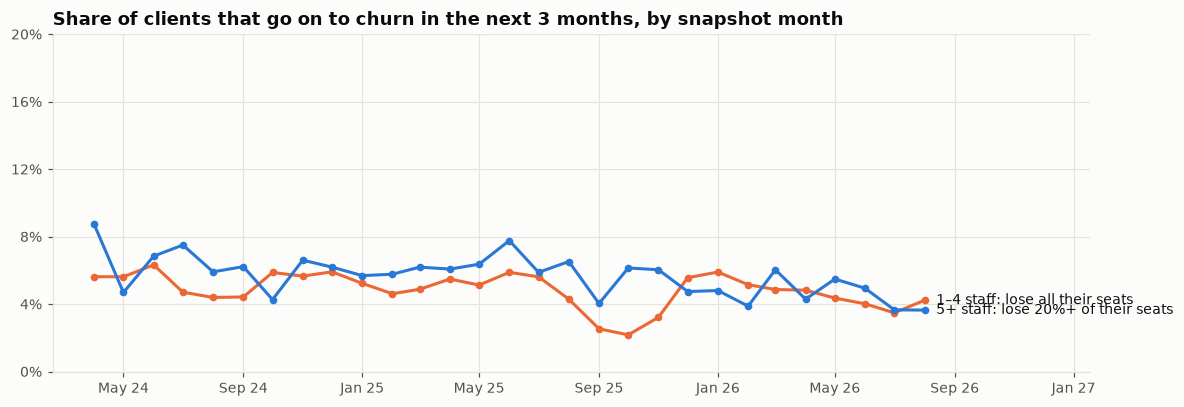

snapshot,1–4 staff: clients,1–4 staff: churned,5+ staff: clients,5+ staff: churned
Apr 2024,587,6%,195,9%
May 2024,605,6%,192,5%
Jun 2024,601,6%,190,7%
Jul 2024,595,5%,200,8%
Aug 2024,592,4%,203,6%
Sep 2024,588,4%,209,6%
Oct 2024,596,6%,211,4%
Nov 2024,601,6%,212,7%
Dec 2024,609,6%,210,6%
Jan 2025,593,5%,211,6%


In [418]:
# ---------------- 2.3 How much churn is there? (by size band) ----------------
s = snapshots
overview = pd.DataFrame({band: {
    "Client-months (snapshots)": f"{len(d):,}",
    "Clients": f"{d['Shortcode'].nunique():,}",
    "Average staff": f"{d['staff'].mean():.1f}",
    "Average seat churn over the next 3 months": pct(d["seat_churn_next_3m"].mean(), 1),
    "  ...counting every reason, incl. business reasons": pct((d["seats_lost_all_reasons_next_3m"] / d["staff"]).clip(upper=1).mean(), 1),
    "No seats lost": pct((d["seat_churn_next_3m"] == 0).mean()),
    "Lost at least one seat": pct((d["seats_lost_next_3m"] > 0).mean(), 1),
    f"Lost {HIGH_CHURN:.0%}+ of seats": pct(d["high_churn"].mean(), 1),
    "Lost 50%+ of seats": pct((d["seat_churn_next_3m"] >= 0.5).mean(), 1),
    "Lost all seats (full exit)": pct(d["full_exit_next_3m"].mean(), 1),
    "Outcome used for this band": f"{BANDS[band]['outcome_words']} ({pct(d['churned'].mean(), 1)})",
} for band in BAND_NAMES for d in [band_rows(s, band)]}).rename_axis("over the next 3 months").reset_index()
show_table(overview, caption="Churn at a glance, by size band")

monthly = (s.groupby(["snapshot", "size_band"]).agg(clients=("Shortcode", "size"), churned=("churned", "mean"))
           .reset_index())
band_color = {BAND_NAMES[0]: COLORS["second"], BAND_NAMES[1]: COLORS["main"]}
fig, ax = plt.subplots(figsize=(11, 3.8))
for band in BAND_NAMES:
    m = monthly[monthly["size_band"] == band]
    ax.plot(m["snapshot"], m["churned"], color=band_color[band], marker="o", markersize=4)
    ax.text(m["snapshot"].iloc[-1] + pd.Timedelta(days=12), m["churned"].iloc[-1],
            f"{band}: {BANDS[band]['outcome_words']}", va="center", fontsize=9, color=COLORS["text"])
ax.set_title("Share of clients that go on to churn in the next 3 months, by snapshot month")
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %y"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, max(0.2, monthly["churned"].max() * 1.2))
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.04))
ax.set_xlim(right=monthly["snapshot"].max() + pd.Timedelta(days=170))
fig.tight_layout()
plt.show()

monthly_wide = monthly.pivot(index="snapshot", columns="size_band", values=["clients", "churned"])
monthly_wide.columns = [f"{b}: {'clients' if m == 'clients' else 'churned'}" for m, b in monthly_wide.columns]
monthly_wide = monthly_wide[[f"{b}: {m}" for b in BAND_NAMES for m in ("clients", "churned")]].reset_index()
monthly_wide["snapshot"] = monthly_wide["snapshot"].dt.strftime("%b %Y")
show_table(monthly_wide, pct_cols=[f"{b}: churned" for b in BAND_NAMES], int_cols=[f"{b}: clients" for b in BAND_NAMES],
           caption="By snapshot month (churned = the band's outcome)")

## 2.4 Which events come before churn?
**How to read it:** each row compares client-months that had the event in the months before the snapshot with those that didn't, separately for each size band. *2x* means twice as likely to churn (full exit for 1–4 staff, 20%+ for 5+ staff). The line is the 95% range: a solid dot means a clear signal, a hollow dot means the range crosses 1x and the difference could be chance.

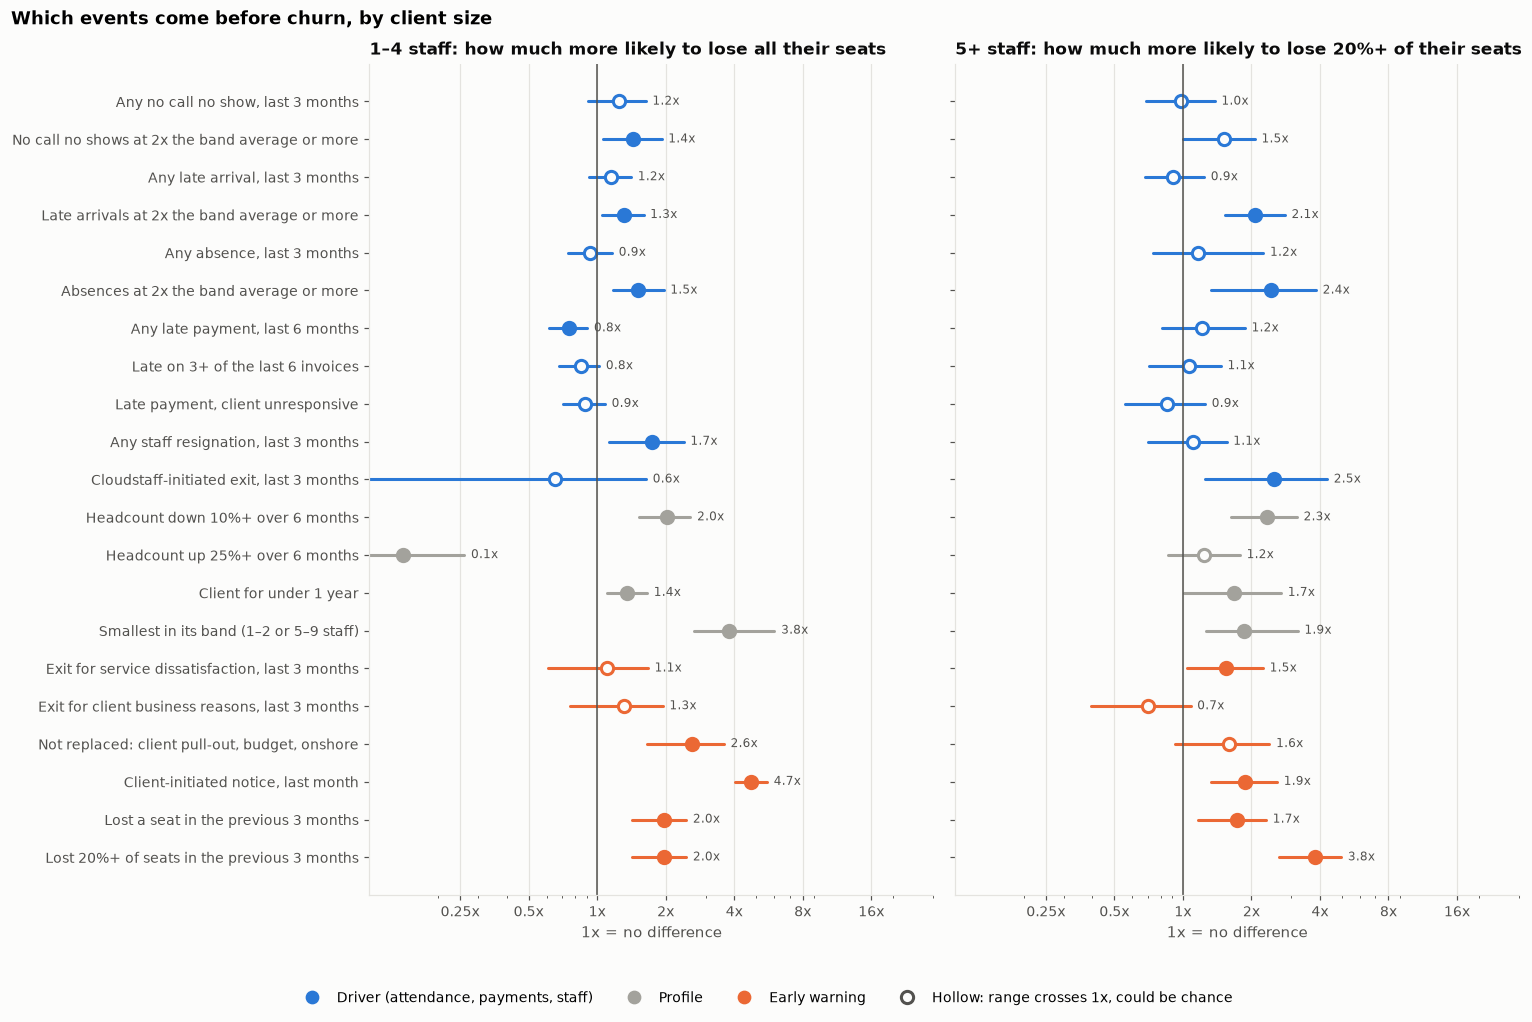

event before the snapshot,group,1–4 staff: x as likely,1–4 staff: clear?,5+ staff: x as likely,5+ staff: clear?
"Any no call no show, last 3 months",Driver: attendance,1.25,no,0.98,no
No call no shows at 2x the band average or more,Driver: attendance,1.43,yes,1.52,no
"Any late arrival, last 3 months",Driver: attendance,1.15,no,0.91,no
Late arrivals at 2x the band average or more,Driver: attendance,1.31,yes,2.07,yes
"Any absence, last 3 months",Driver: attendance,0.93,no,1.17,no
Absences at 2x the band average or more,Driver: attendance,1.51,yes,2.43,yes
"Any late payment, last 6 months",Driver: payments,0.75,yes,1.21,no
Late on 3+ of the last 6 invoices,Driver: payments,0.85,no,1.07,no
"Late payment, client unresponsive",Driver: payments,0.88,no,0.86,no
"Any staff resignation, last 3 months",Driver: staff,1.74,yes,1.11,no


event before the snapshot,group,client-months with it,churn with,churn without,x times as likely,95% range low,95% range high,clear signal
"Any no call no show, last 3 months",Driver: attendance,"1,240",6%,5%,1.25,0.92,1.64,no
No call no shows at 2x the band average or more,Driver: attendance,"1,057",7%,5%,1.43,1.06,1.92,yes
"Any late arrival, last 3 months",Driver: attendance,"3,437",5%,5%,1.15,0.92,1.41,no
Late arrivals at 2x the band average or more,Driver: attendance,"3,078",6%,5%,1.31,1.05,1.60,yes
"Any absence, last 3 months",Driver: attendance,"5,087",5%,5%,0.93,0.74,1.16,no
Absences at 2x the band average or more,Driver: attendance,"2,113",7%,5%,1.51,1.17,1.96,yes
"Any late payment, last 6 months",Driver: payments,"13,095",4%,6%,0.75,0.61,0.91,yes
Late on 3+ of the last 6 invoices,Driver: payments,"6,106",4%,5%,0.85,0.68,1.02,no
"Late payment, client unresponsive",Driver: payments,"7,824",4%,5%,0.88,0.71,1.08,no
"Any staff resignation, last 3 months",Driver: staff,764,8%,5%,1.74,1.13,2.40,yes


event before the snapshot,group,client-months with it,churn with,churn without,x times as likely,95% range low,95% range high,clear signal
"Any no call no show, last 3 months",Driver: attendance,"2,250",6%,6%,0.98,0.69,1.38,no
No call no shows at 2x the band average or more,Driver: attendance,"1,040",8%,5%,1.52,1.00,2.07,no
"Any late arrival, last 3 months",Driver: attendance,"3,944",5%,6%,0.91,0.68,1.24,no
Late arrivals at 2x the band average or more,Driver: attendance,"1,023",10%,5%,2.07,1.53,2.81,yes
"Any absence, last 3 months",Driver: attendance,"4,178",6%,5%,1.17,0.74,2.26,no
Absences at 2x the band average or more,Driver: attendance,604,12%,5%,2.43,1.32,3.85,yes
"Any late payment, last 6 months",Driver: payments,"4,903",6%,5%,1.21,0.81,1.87,no
Late on 3+ of the last 6 invoices,Driver: payments,"2,895",6%,5%,1.07,0.71,1.47,no
"Late payment, client unresponsive",Driver: payments,"2,779",5%,6%,0.86,0.55,1.25,no
"Any staff resignation, last 3 months",Driver: staff,"1,826",6%,5%,1.11,0.70,1.56,no


In [419]:
# ---------------- 2.4 Which events come before churn? (relative risk, by size band) ----------------
# For each event and band: the share that churned (the band's outcome) among client-months that had the event vs those
# that didn't. "x times as likely" = the ratio of the two. Months where the event's source has no data are left out.
# The 95% range comes from resampling whole clients (a client's months are not independent), so a range that crosses
# 1.0 means the difference could be chance. Events seen in fewer than MIN_EVENT_MONTHS client-months are not rated.
MIN_EVENT_MONTHS = 30
s = snapshots
EVENTS = {  # label -> (group, feature, test on the feature)
    "Any no call no show, last 3 months":               ("Driver: attendance", "any_ncns_3m", lambda x: x == 1),
    "No call no shows at 2x the band average or more":  ("Driver: attendance", "ncns_index", lambda x: x >= 2),
    "Any late arrival, last 3 months":                  ("Driver: attendance", "any_tardiness_3m", lambda x: x == 1),
    "Late arrivals at 2x the band average or more":     ("Driver: attendance", "tardiness_index", lambda x: x >= 2),
    "Any absence, last 3 months":                       ("Driver: attendance", "any_absence_3m", lambda x: x == 1),
    "Absences at 2x the band average or more":          ("Driver: attendance", "absence_index", lambda x: x >= 2),
    "Any late payment, last 6 months":                  ("Driver: payments", "late_payment_months_6m", lambda x: x >= 1),
    "Late on 3+ of the last 6 invoices":                ("Driver: payments", "late_payment_months_6m", lambda x: x >= 3),
    "Late payment, client unresponsive":                ("Driver: payments", "late_payment_unresponsive_6m", lambda x: x == 1),
    "Any staff resignation, last 3 months":             ("Driver: staff", "resignations_per10_3m", lambda x: x > 0),
    "Cloudstaff-initiated exit, last 3 months":         ("Driver: staff", "cloudstaff_exits_per10_3m", lambda x: x > 0),
    "Headcount down 10%+ over 6 months":                ("Profile", "headcount_change_6m", lambda x: x <= -0.10),
    "Headcount up 25%+ over 6 months":                  ("Profile", "headcount_change_6m", lambda x: x >= 0.25),
    "Client for under 1 year":                          ("Profile", "client_age_years", lambda x: x < 1),
    "Smallest in its band (1–2 or 5–9 staff)":          ("Profile", "staff", lambda x: (x <= 2) | x.between(5, 9)),
    "Exit for service dissatisfaction, last 3 months":  ("Early warning", "service_dissatisfaction_per10_3m", lambda x: x > 0),
    "Exit for client business reasons, last 3 months":  ("Early warning", "business_reason_exits_per10_3m", lambda x: x > 0),
    "Not replaced: client pull-out, budget, onshore":   ("Early warning", "client_risk_not_replaced_3m", lambda x: x == 1),
    "Client-initiated notice, last month":              ("Early warning", "client_notices_per10_1m", lambda x: x > 0),
    "Lost a seat in the previous 3 months":             ("Early warning", "seat_churn_last_3m", lambda x: x > 0),
    f"Lost {HIGH_CHURN:.0%}+ of seats in the previous 3 months": ("Early warning", "seat_churn_last_3m", lambda x: x >= HIGH_CHURN),
}
# 1 = had the event, 0 = didn't, blank = no data for that month (reused in 2.5)
event_flags = pd.DataFrame({lbl: test(s[f]).astype(float).where(s[f].notna()) for lbl, (_, f, test) in EVENTS.items()}, index=s.index)


def relative_risk(band, n_boot=500, seed=7):
    d = band_rows(s, band)
    flags = event_flags.loc[d.index]
    clients = d["Shortcode"].astype("category")
    codes, n_clients = clients.cat.codes.to_numpy(), len(clients.cat.categories)
    boot = np.random.default_rng(seed).integers(0, n_clients, size=(n_boot, n_clients))
    y = d["churned"].to_numpy(float)
    rows = []
    for label, (group, _, _) in EVENTS.items():
        f = flags[label]
        known, has = f.notna().to_numpy(), (f == 1).to_numpy()
        a, b, c, e = [np.bincount(codes, weights=w.astype(float), minlength=n_clients)
                      for w in (has, has * y, known & ~has, (known & ~has) * y)]
        enough = a.sum() >= MIN_EVENT_MONTHS and c.sum() > 0 and e.sum() > 0
        ratio = (b.sum() / a.sum()) / (e.sum() / c.sum()) if enough else np.nan
        lo = hi = np.nan
        if enough:
            with np.errstate(divide="ignore", invalid="ignore"):
                bs = (b[boot].sum(1) / a[boot].sum(1)) / (e[boot].sum(1) / c[boot].sum(1))
            lo, hi = np.nanpercentile(bs[np.isfinite(bs)], [2.5, 97.5])
        rows.append({"size band": band, "event before the snapshot": label, "group": group, "client-months with it": int(a.sum()),
                     "churn with": b.sum() / a.sum() if a.sum() else np.nan, "churn without": e.sum() / c.sum() if c.sum() else np.nan,
                     "x times as likely": ratio, "95% range low": lo, "95% range high": hi,
                     "clear signal": "too few" if not enough else "yes" if lo > 1 or hi < 1 else "no"})
    return pd.DataFrame(rows)


risk = pd.concat([relative_risk(b) for b in BAND_NAMES], ignore_index=True)

# chart: one panel per band, same rows in the same order; dot = ratio, line = 95% range, log scale
group_color = {"Driver: attendance": COLORS["main"], "Driver: payments": COLORS["main"], "Driver: staff": COLORS["main"],
               "Profile": COLORS["muted"], "Early warning": COLORS["second"]}
row_order = list(EVENTS)[::-1]      # top of the chart = first event
fig, axes = plt.subplots(1, len(BAND_NAMES), figsize=(14, 0.36 * len(row_order) + 1.6), sharey=True)
for ax, band in zip(axes, BAND_NAMES):
    r_band = risk[risk["size band"] == band].set_index("event before the snapshot")
    for yy, label in enumerate(row_order):
        r = r_band.loc[label]
        col = group_color[r["group"]]
        if r["clear signal"] == "too few":
            ax.text(1, yy, "too few months", va="center", ha="center", fontsize=8, color=COLORS["muted"])
            continue
        lo, hi = max(r["95% range low"], 0.1), min(r["95% range high"], 20)
        ax.plot([lo, hi], [yy, yy], color=col, linewidth=2, solid_capstyle="round")
        ax.plot(min(max(r["x times as likely"], 0.1), 20), yy, "o", markersize=8, markeredgewidth=2, markeredgecolor=col,
                color=col if r["clear signal"] == "yes" else COLORS["surface"])
        ax.text(hi * 1.07, yy, f"{r['x times as likely']:.1f}x", va="center", fontsize=8, color=COLORS["text2"])
    ax.axvline(1, color=COLORS["text2"], linewidth=1)
    ax.set_xscale("log")
    ax.set_xlim(0.1, 30)
    ax.set_xticks([0.25, 0.5, 1, 2, 4, 8, 16])
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.xaxis.set_minor_formatter(mtick.NullFormatter())
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{band}: how much more likely to {BANDS[band]['outcome_words']}", fontsize=11)
    ax.set_xlabel("1x = no difference")
axes[0].set_yticks(range(len(row_order)), row_order)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], marker="o", color=c, linestyle="", markersize=8, label=l) for l, c in
                    [("Driver (attendance, payments, staff)", COLORS["main"]), ("Profile", COLORS["muted"]), ("Early warning", COLORS["second"])]]
           + [Line2D([], [], marker="o", color=COLORS["text2"], markerfacecolor=COLORS["surface"], markeredgewidth=2, linestyle="",
                     markersize=8, label="Hollow: range crosses 1x, could be chance")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("Which events come before churn, by client size", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

# side-by-side table: one row per event, the two bands next to each other
side = risk.pivot(index="event before the snapshot", columns="size band", values=["x times as likely", "clear signal"])
side.columns = [f"{b}: {'x as likely' if m == 'x times as likely' else 'clear?'}" for m, b in side.columns]
side = side.reindex(list(EVENTS)).reset_index()
side.insert(1, "group", side["event before the snapshot"].map({k: v[0] for k, v in EVENTS.items()}))
side = side[["event before the snapshot", "group"] + [f"{b}: {m}" for b in BAND_NAMES for m in ("x as likely", "clear?")]]
for b in BAND_NAMES:
    side[f"{b}: x as likely"] = side[f"{b}: x as likely"].astype(float)
show_table(side, num_cols=[f"{b}: x as likely" for b in BAND_NAMES],
           caption="Side by side: 1–4 staff = chance of losing all seats; 5+ staff = chance of losing 20%+ of seats")
for band in BAND_NAMES:
    show_table(risk[risk["size band"] == band].drop(columns="size band"),
               pct_cols=["churn with", "churn without"], num_cols=["x times as likely", "95% range low", "95% range high"],
               int_cols=["client-months with it"], caption=f"{band}: share that went on to {BANDS[band]['outcome_words']}, with and without each event")

## 2.4b Which pairs of events are strong indicators?
**How to read it:** each cell is the share of client-months that went on to churn when *both* events had happened (the diagonal is the event on its own, from 2.4). Darker = more churn. A **red box** marks a pair that is *stronger together*: churn with both is clearly higher than with the stronger of the two on its own (its 95% range, from resampling whole clients, is above 1). The table lists the strongest pairs, with churn for both, each one alone, and neither.

Pairs built from the same measure (for example two NCNS thresholds) are skipped, and so are pairs seen together in fewer than 30 client-months.

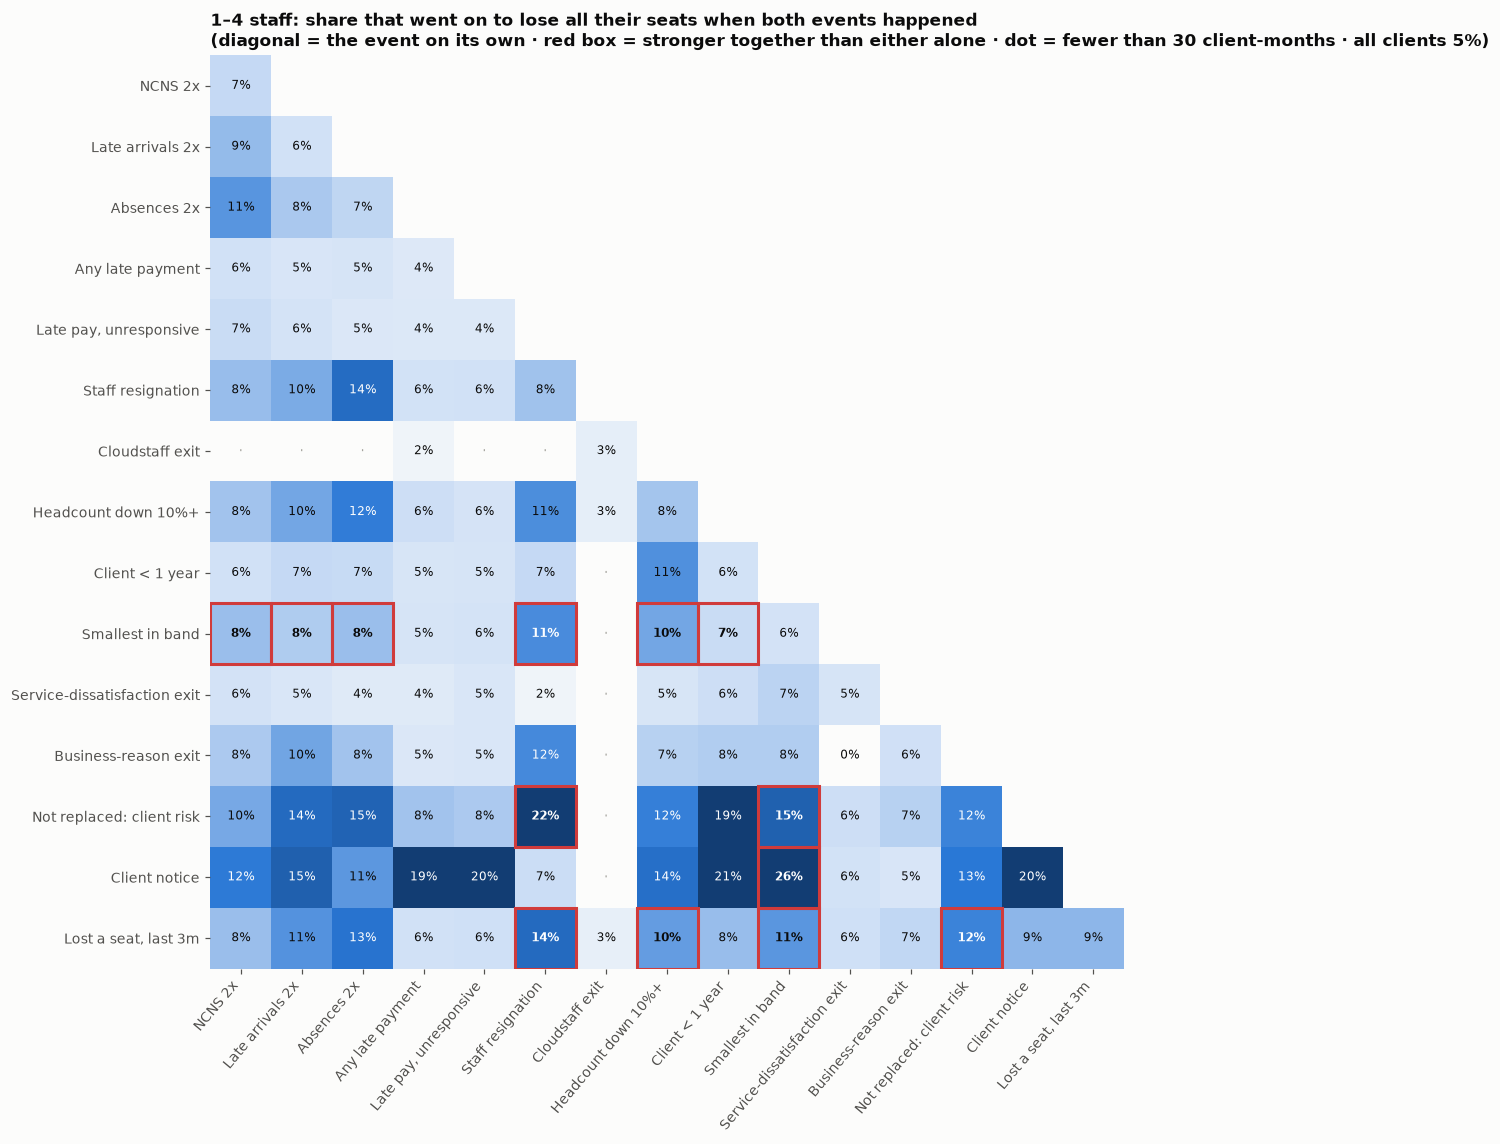

event 1,event 2,client-months with both,churn with both,only event 1,only event 2,neither,x as likely (both vs neither),clear signal,together vs stronger alone,stronger together
Smallest in band,Client notice,445,26%,5%,7%,1%,21.71,yes,3.73,yes
Staff resignation,Not replaced: client risk,138,22%,5%,8%,5%,4.88,yes,2.91,yes
Smallest in band,Not replaced: client risk,311,15%,6%,6%,1%,11.42,yes,2.48,yes
Staff resignation,"Lost a seat, last 3m",391,14%,2%,7%,5%,3.09,yes,2.12,yes
Staff resignation,Smallest in band,453,11%,3%,6%,1%,8.35,yes,2.07,yes
Headcount down 10%+,Smallest in band,"1,231",10%,5%,5%,1%,10.05,yes,2.02,yes
Smallest in band,"Lost a seat, last 3m",839,11%,5%,5%,1%,10.62,yes,2.00,yes
Headcount down 10%+,"Lost a seat, last 3m",888,10%,6%,3%,4%,2.65,yes,1.82,yes
Not replaced: client risk,"Lost a seat, last 3m",475,12%,–,7%,4%,2.67,yes,1.70,yes
Absences 2x,Smallest in band,"1,644",8%,2%,5%,1%,5.71,yes,1.53,yes


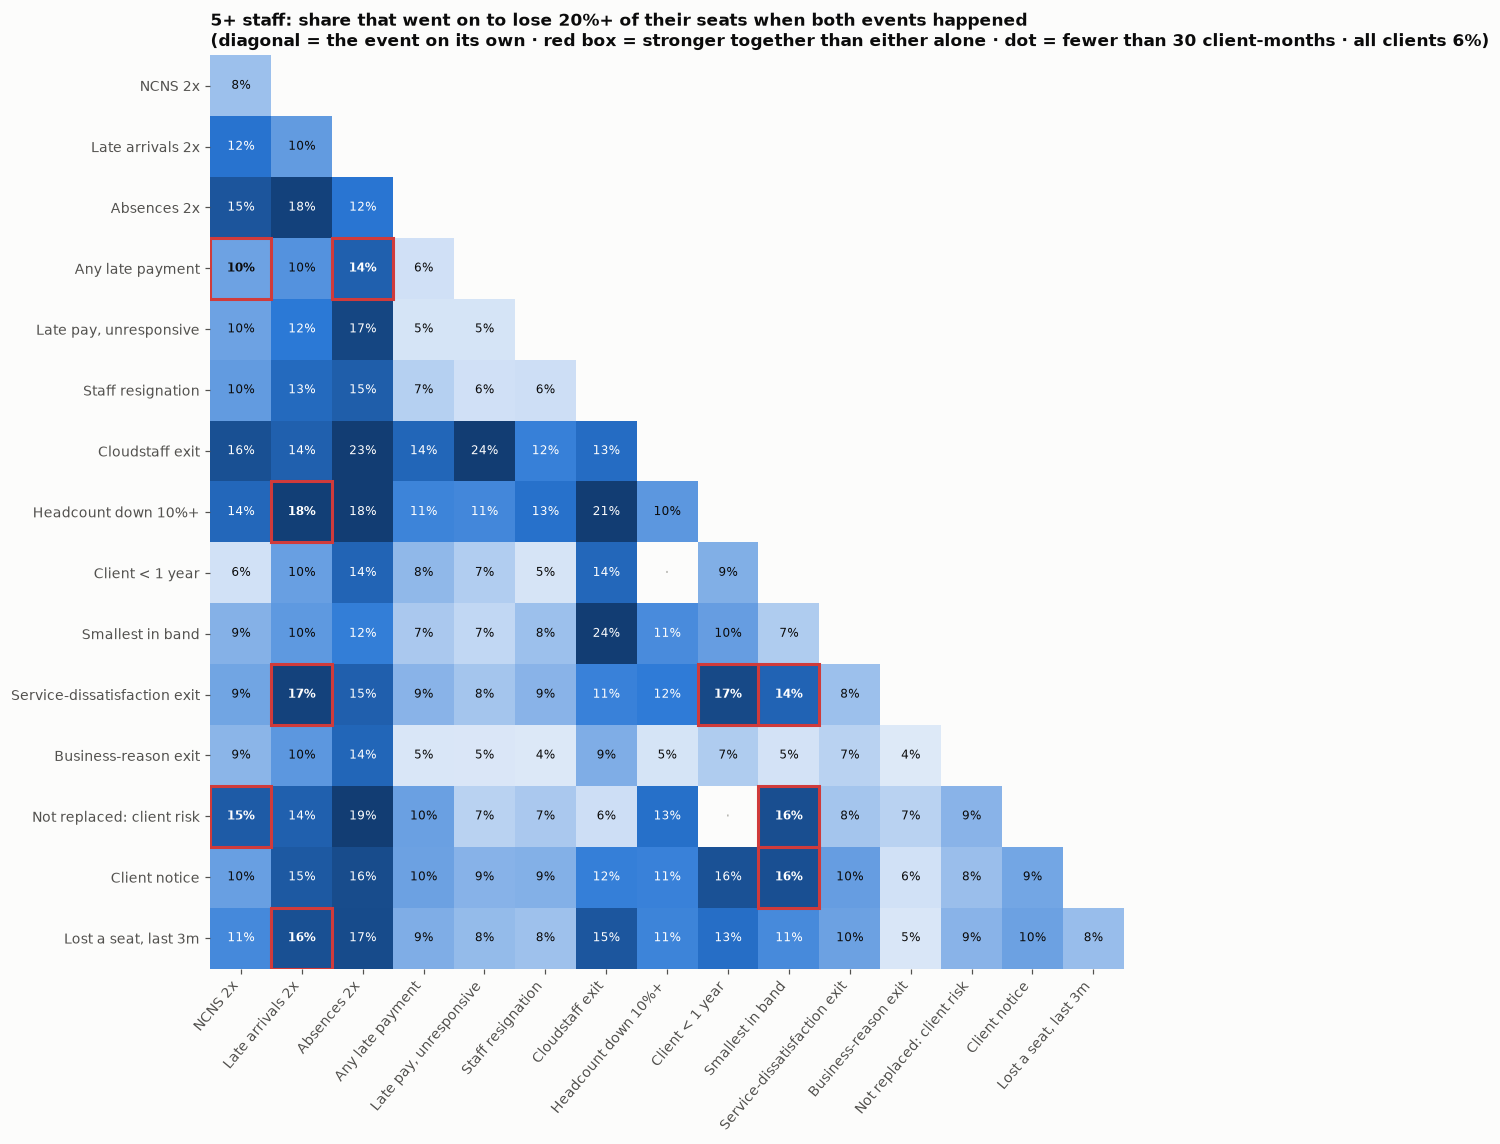

event 1,event 2,client-months with both,churn with both,only event 1,only event 2,neither,x as likely (both vs neither),clear signal,together vs stronger alone,stronger together
Absences 2x,Any late payment,479,14%,4%,5%,5%,2.87,yes,2.86,yes
Smallest in band,Not replaced: client risk,184,16%,7%,5%,4%,4.35,yes,2.46,yes
Client < 1 year,Service-dissatisfaction exit,125,17%,7%,7%,5%,3.43,yes,2.44,yes
Smallest in band,Client notice,260,16%,6%,7%,3%,5.53,yes,2.37,yes
Late arrivals 2x,Service-dissatisfaction exit,235,17%,8%,6%,5%,3.78,yes,2.25,yes
Late arrivals 2x,"Lost a seat, last 3m",324,16%,7%,6%,4%,3.87,yes,2.24,yes
NCNS 2x,Not replaced: client risk,127,15%,7%,7%,5%,2.94,yes,2.17,yes
Smallest in band,Service-dissatisfaction exit,291,14%,7%,6%,3%,5.03,yes,2.16,yes
Late arrivals 2x,Headcount down 10%+,196,18%,8%,8%,4%,4.73,yes,2.12,yes
NCNS 2x,Any late payment,804,10%,2%,5%,5%,1.78,yes,1.86,yes


In [420]:
# ---------------- 2.4b Which pairs of events are strong indicators? ----------------
# For every pair of events from 2.4 (pairs built from the same measure, e.g. two NCNS thresholds, are skipped):
#   churn with both, with only one of them, and with neither (the band's outcome, as in 2.4)
#   "x as likely" = both vs neither
#   "together vs stronger alone" = churn with both / churn with the stronger of the two on its own (1.0 = the pair adds
#   nothing over its stronger half). "Stronger together" = that ratio's 95% range is above 1.
# 95% ranges come from resampling whole clients. Pairs seen together in fewer than MIN_PAIR_MONTHS client-months are skipped.
from matplotlib.colors import LinearSegmentedColormap

MIN_PAIR_MONTHS = 30
PAIR_EVENTS = {  # 2.4 event -> short name for the chart
    "No call no shows at 2x the band average or more": "NCNS 2x",
    "Late arrivals at 2x the band average or more": "Late arrivals 2x",
    "Absences at 2x the band average or more": "Absences 2x",
    "Any late payment, last 6 months": "Any late payment",
    "Late payment, client unresponsive": "Late pay, unresponsive",
    "Any staff resignation, last 3 months": "Staff resignation",
    "Cloudstaff-initiated exit, last 3 months": "Cloudstaff exit",
    "Headcount down 10%+ over 6 months": "Headcount down 10%+",
    "Client for under 1 year": "Client < 1 year",
    "Smallest in its band (1–2 or 5–9 staff)": "Smallest in band",
    "Exit for service dissatisfaction, last 3 months": "Service-dissatisfaction exit",
    "Exit for client business reasons, last 3 months": "Business-reason exit",
    "Not replaced: client pull-out, budget, onshore": "Not replaced: client risk",
    "Client-initiated notice, last month": "Client notice",
    "Lost a seat in the previous 3 months": "Lost a seat, last 3m",
}
PAIR_LIST = list(PAIR_EVENTS)


def pair_table(band, n_boot=300, seed=7):
    d = band_rows(snapshots, band)
    flags = event_flags.loc[d.index, PAIR_LIST]
    y = d["churned"].to_numpy(float)
    codes = d["Shortcode"].astype("category").cat.codes.to_numpy()
    n_clients = codes.max() + 1
    boot = np.random.default_rng(seed).integers(0, n_clients, size=(n_boot, n_clients))
    per_client = lambda m: np.bincount(codes, weights=m.astype(float), minlength=n_clients)
    rows = []
    for i, a in enumerate(PAIR_LIST):
        for b in PAIR_LIST[i + 1:]:
            if EVENTS[a][1] == EVENTS[b][1]:
                continue
            known = (flags[a].notna() & flags[b].notna()).to_numpy()
            A, B = (flags[a] == 1).to_numpy(), (flags[b] == 1).to_numpy()
            groups = {"both": known & A & B, "only 1": known & A & ~B, "only 2": known & ~A & B, "neither": known & ~A & ~B}
            n = {k: per_client(m) for k, m in groups.items()}
            ch = {k: per_client(m * y) for k, m in groups.items()}
            rate = {k: ch[k].sum() / n[k].sum() if n[k].sum() else np.nan for k in groups}
            row = {"size band": band, "event 1": PAIR_EVENTS[a], "event 2": PAIR_EVENTS[b], "client-months with both": int(n["both"].sum()),
                   "churn with both": rate["both"], "only event 1": rate["only 1"], "only event 2": rate["only 2"], "neither": rate["neither"]}
            if n["both"].sum() >= MIN_PAIR_MONTHS and rate["neither"] > 0:
                with np.errstate(divide="ignore", invalid="ignore"):
                    br = {k: ch[k][boot].sum(1) / n[k][boot].sum(1) for k in groups}
                    vs_neither = br["both"] / br["neither"]
                    vs_alone = br["both"] / np.fmax(br["only 1"], br["only 2"])
                lo_n, hi_n = np.nanpercentile(vs_neither[np.isfinite(vs_neither)], [2.5, 97.5])
                lo_a, hi_a = np.nanpercentile(vs_alone[np.isfinite(vs_alone)], [2.5, 97.5])
                stronger_alone = np.nanmax([rate["only 1"], rate["only 2"]])
                row.update({"x as likely (both vs neither)": rate["both"] / rate["neither"], "clear signal": "yes" if lo_n > 1 or hi_n < 1 else "no",
                            "together vs stronger alone": rate["both"] / stronger_alone if stronger_alone > 0 else np.nan,
                            "stronger together": "yes" if lo_a > 1 else "no", "_range": (lo_a, hi_a)})
            rows.append(row)
    return pd.DataFrame(rows)


pairs = pd.concat([pair_table(b) for b in BAND_NAMES], ignore_index=True)

# heatmap per band: churn when both events are present (diagonal = the event on its own, from 2.4)
cmap = LinearSegmentedColormap.from_list("seq", [COLORS["surface"], "#cfe0f6", COLORS["main"], "#123d73"])
short = list(PAIR_EVENTS.values())
for band in BAND_NAMES:
    pb_ = pairs[pairs["size band"] == band]
    base = band_rows(snapshots, band)["churned"].mean()
    M = pd.DataFrame(np.nan, index=short, columns=short)
    strong = set()
    for _, r in pb_.iterrows():
        if r["client-months with both"] >= MIN_PAIR_MONTHS:
            M.loc[r["event 2"], r["event 1"]] = M.loc[r["event 1"], r["event 2"]] = r["churn with both"]
            if r.get("stronger together") == "yes":
                strong |= {(r["event 1"], r["event 2"]), (r["event 2"], r["event 1"])}
    rb = risk[risk["size band"] == band].set_index("event before the snapshot")
    for full, sh in PAIR_EVENTS.items():
        M.loc[sh, sh] = rb.loc[full, "churn with"]
    mask = np.triu(np.ones_like(M, dtype=bool), k=1)
    vmax = np.nanpercentile(M.to_numpy(), 95)
    fig, ax = plt.subplots(figsize=(13, 10.5))
    ax.imshow(np.ma.masked_array(M.to_numpy(), mask=mask | M.isna().to_numpy()), cmap=cmap, vmin=0, vmax=vmax)
    for i in range(len(short)):
        for j in range(i + 1):
            v = M.iat[i, j]
            if pd.isna(v):
                ax.text(j, i, "·", ha="center", va="center", fontsize=8, color=COLORS["muted"])
                continue
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > vmax * 0.6 else COLORS["text"], fontweight="bold" if (short[i], short[j]) in strong else "normal")
            if (short[i], short[j]) in strong:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=COLORS["flag"], linewidth=2))
    ax.set_xticks(range(len(short)), short, rotation=50, ha="right")
    ax.set_yticks(range(len(short)), short)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(f"{band}: share that went on to {BANDS[band]['outcome_words']} when both events happened\n"
                 f"(diagonal = the event on its own · red box = stronger together than either alone · "
                 f"dot = fewer than {MIN_PAIR_MONTHS} client-months · all clients {base:.0%})", fontsize=11)
    fig.tight_layout()
    plt.show()

    top = (pb_.dropna(subset=["x as likely (both vs neither)"]).query("`clear signal` == 'yes'")
           .sort_values(["stronger together", "together vs stronger alone"], ascending=[False, False]).head(15)
           .drop(columns=["size band", "_range"]))
    show_table(top, pct_cols=["churn with both", "only event 1", "only event 2", "neither"],
               num_cols=["x as likely (both vs neither)", "together vs stronger alone"], int_cols=["client-months with both"],
               caption=f"{band}: strongest pairs (clear signals; pairs that are stronger together listed first)")

## 2.5 How early do the signals show?
Follows clients back 6 months from the start of a churn episode, against the average of clients in the same band that weren't about to churn (dashed).

**Testing the driver / early-warning grouping.** If the grouping is right, a driver should already be raised 4–6 months before churn, and an early warning should only rise in the month or two before. The last table checks each event against that.

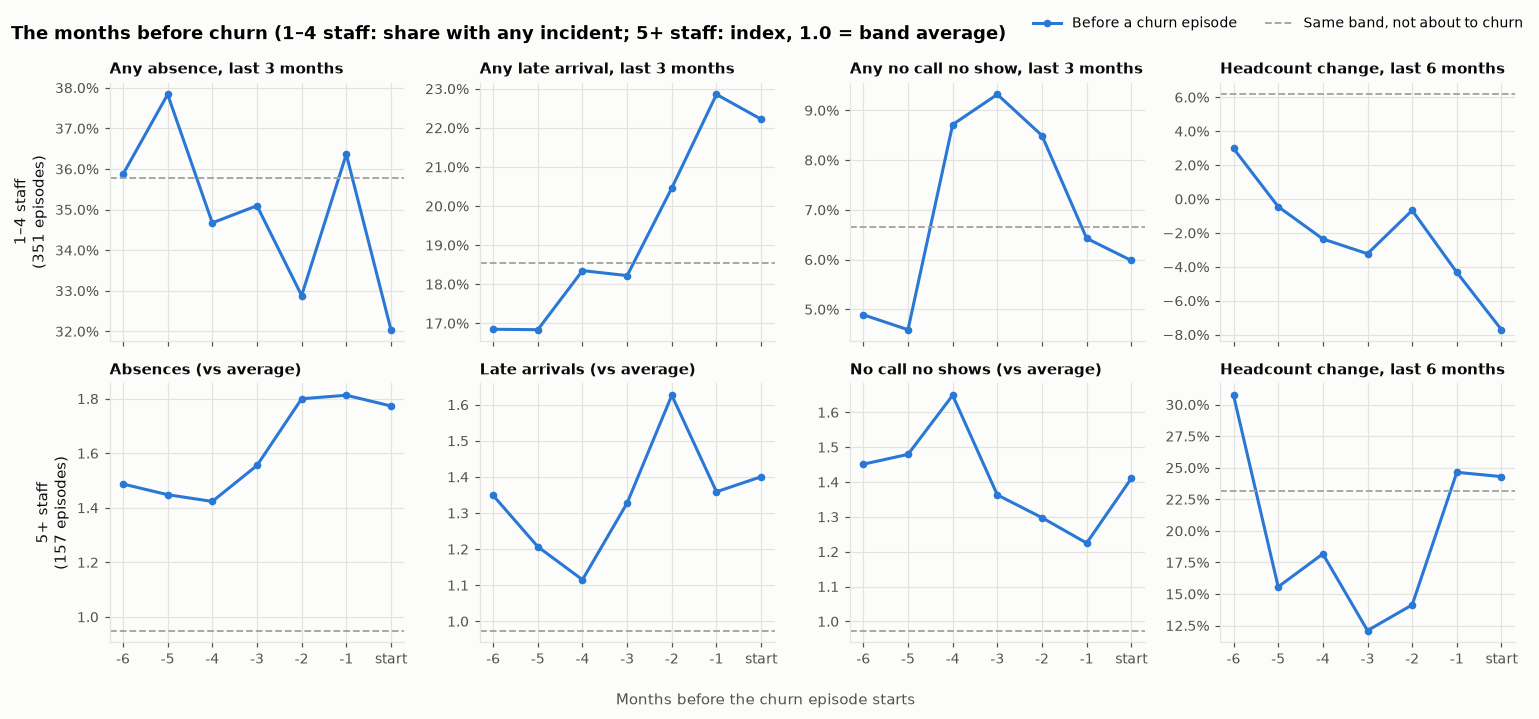

feature,-6 months,-5 months,-4 months,-3 months,-2 months,-1 months,start,not about to churn
"Any absence, last 3 months",0.36,0.38,0.35,0.35,0.33,0.36,0.32,0.36
"Any late arrival, last 3 months",0.17,0.17,0.18,0.18,0.20,0.23,0.22,0.19
"Any no call no show, last 3 months",0.05,0.05,0.09,0.09,0.08,0.06,0.06,0.07
"Headcount change, last 6 months",0.03,-0.00,-0.02,-0.03,-0.01,-0.04,-0.08,0.06


feature,-6 months,-5 months,-4 months,-3 months,-2 months,-1 months,start,not about to churn
Absences (vs average),1.49,1.45,1.42,1.56,1.80,1.81,1.77,0.95
Late arrivals (vs average),1.35,1.21,1.12,1.33,1.63,1.36,1.40,0.97
No call no shows (vs average),1.45,1.48,1.65,1.36,1.30,1.22,1.41,0.97
"Headcount change, last 6 months",0.31,0.16,0.18,0.12,0.14,0.25,0.24,0.23


size band,event,my grouping,4–6 months before (x average),0–1 months before (x average),what the data says,agrees with my grouping?
1–4 staff,"Any no call no show, last 3 months",Driver: attendance,0.91,0.93,not raised before churn,no signal
1–4 staff,No call no shows at 2x the band average or more,Driver: attendance,1.08,1.10,not raised before churn,no signal
1–4 staff,"Any late arrival, last 3 months",Driver: attendance,0.94,1.22,not raised before churn,no signal
1–4 staff,Late arrivals at 2x the band average or more,Driver: attendance,0.95,1.33,raised only just before,no: shows later than a driver should
1–4 staff,"Any absence, last 3 months",Driver: attendance,1.01,0.96,not raised before churn,no signal
1–4 staff,Absences at 2x the band average or more,Driver: attendance,1.30,1.33,raised 4–6 months ahead and just before,yes
1–4 staff,"Any late payment, last 6 months",Driver: payments,1.09,0.91,not raised before churn,no signal
1–4 staff,Late on 3+ of the last 6 invoices,Driver: payments,1.20,0.91,not raised before churn,no signal
1–4 staff,"Late payment, client unresponsive",Driver: payments,1.13,0.94,not raised before churn,no signal
1–4 staff,"Any staff resignation, last 3 months",Driver: staff,1.68,1.29,raised 4–6 months ahead and just before,yes


In [421]:
# ---------------- 2.5 How early do the signals show? (the months before a churn episode, by size band) ----------------
# A churn episode starts at the first snapshot where a client is about to churn (the band's outcome) and the month
# before it was not. Each line follows those clients back 6 months; the dashed line is the average of client-months in
# the same band that were not about to churn.
# The timing table then tests the driver / early-warning grouping against the data: a driver should already be raised
# 4-6 months before an episode; an early warning should only rise in the last month or two.
LEADUP = {"1–4 staff": ["any_absence_3m", "any_tardiness_3m", "any_ncns_3m", "headcount_change_6m"],
          "5+ staff":  ["absence_index", "tardiness_index", "ncns_index", "headcount_change_6m"]}
RAISED = 1.25        # "raised" = at least 25% above the not-about-to-churn average
s = snapshots.sort_values(["Shortcode", "snapshot"]).copy()
s["month_no"] = s["snapshot"].dt.year * 12 + s["snapshot"].dt.month
prev = s.groupby("Shortcode")["churned"].shift(1)
prev_month = s.groupby("Shortcode")["month_no"].shift(1)
s["episode_start"] = s["churned"] & ~((prev == True) & (prev_month == s["month_no"] - 1))
flags = event_flags.loc[s.index].add_prefix("ev: ")
s = pd.concat([s, flags], axis=1)
EV_COLS = list(flags.columns)


def months_before(starts, cols):
    """Average of cols for the episode clients at k = -6 .. 0 months from the episode start."""
    out = {}
    for k in range(-6, 1):
        m = starts[["Shortcode", "month_no"]].assign(month_no=starts["month_no"] + k).merge(s[["Shortcode", "month_no"] + cols],
                                                                                             on=["Shortcode", "month_no"])
        out[k] = m[cols].mean()
    return pd.DataFrame(out).T


timing_rows, leadup = [], {}
for band in BAND_NAMES:
    starts = s[s["episode_start"] & (s["size_band"] == band)]
    base = s[(s["size_band"] == band) & ~s["churned"]]
    feats = LEADUP[band]
    lead = months_before(starts, feats)
    leadup[band] = (lead, base[feats].mean(), len(starts))

    ev = months_before(starts, EV_COLS)
    base_ev = base[EV_COLS].mean()
    for c in EV_COLS:
        label = c[4:]
        early = ev.loc[-6:-4, c].mean() / base_ev[c] if base_ev[c] > 0 else np.nan
        late = ev.loc[-1:0, c].mean() / base_ev[c] if base_ev[c] > 0 else np.nan
        group = EVENTS[label][0]
        if base_ev[c] * len(starts) < 5 or pd.isna(early):
            verdict, agrees = "too rare to tell", "–"
        elif early >= RAISED:
            verdict = "raised 4–6 months ahead and just before" if late >= RAISED else "raised 4–6 months ahead, fades before"
            agrees = "yes" if group.startswith("Driver") else "no: shows earlier than an early warning should"
        elif late >= RAISED:
            verdict = "raised only just before"
            agrees = "yes" if group == "Early warning" else "no: shows later than a driver should"
        else:
            verdict, agrees = "not raised before churn", "no signal"
        timing_rows.append({"size band": band, "event": label, "my grouping": group,
                            "4–6 months before (x average)": early, "0–1 months before (x average)": late,
                            "what the data says": verdict, "agrees with my grouping?": agrees})
timing = pd.DataFrame(timing_rows)

# small multiples: one row per band
fig, axes = plt.subplots(len(BAND_NAMES), 4, figsize=(14, 6.4), sharex=True)
for row, band in zip(axes, BAND_NAMES):
    lead, base, n = leadup[band]
    for ax, f in zip(row, LEADUP[band]):
        ax.plot(lead.index, lead[f], color=COLORS["main"], marker="o", markersize=4, label="Before a churn episode")
        ax.axhline(base[f], color=COLORS["muted"], linestyle="--", linewidth=1.2, label="Same band, not about to churn")
        ax.set_title(LABEL[f], fontsize=9.5)
        ax.set_xticks(range(-6, 1), [f"{k}" if k else "start" for k in range(-6, 1)])
        if f.startswith("any_"):
            ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=None))
        if f == "headcount_change_6m":
            ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=None))
    row[0].set_ylabel(f"{band}\n({n:,} episodes)", fontsize=10, color=COLORS["text"])
fig.legend(*axes[0][0].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(1, 1.01))
fig.supxlabel("Months before the churn episode starts", fontsize=10, color=COLORS["text2"])
fig.suptitle("The months before churn (1–4 staff: share with any incident; 5+ staff: index, 1.0 = band average)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

for band in BAND_NAMES:
    lead, base, n = leadup[band]
    show_table(lead.T.rename(columns=lambda k: f"{k} months" if k else "start").assign(**{"not about to churn": base})
               .rename(index=LABEL).reset_index(names="feature"),
               num_cols=[*(f"{k} months" for k in range(-6, 0)), "start", "not about to churn"],
               caption=f"{band}: average before a churn episode vs clients not about to churn")

show_table(timing[timing["my grouping"] != "Profile"],
           num_cols=["4–6 months before (x average)", "0–1 months before (x average)"],
           caption=f"Does the data agree with the driver / early-warning grouping? (raised = {RAISED:.2f}x the not-about-to-churn average or more)")

## 2.6 Predicting churn
Each band has its own pair of models, trained on snapshots up to October 2025 and scored on January–August 2026, months they never saw. AUC reads like this: 0.5 is a coin flip, about 0.7 is useful.

1–4 staff: training 11,607 client-months (Apr 2024-Oct 2025) · test 5,501 (Jan 2026-Aug 2026), 252 churned
5+ staff: training 4,006 client-months (Apr 2024-Oct 2025) · test 1,899 (Jan 2026-Aug 2026), 87 churned


size band,model,predicts,finds churners (AUC),ranking (Spearman),"churned, top 10% predicted",churners caught in top 10%
1–4 staff,A: drivers,chance of losing all seats,0.67,0.12,9%,19%
1–4 staff,B: drivers + early warnings,chance of losing all seats,0.70,0.14,13%,29%
1–4 staff,no model (everyone the same),chance of losing all seats,0.50,–,5%,10%
5+ staff,A: drivers,predicted seat churn,0.57,0.18,9%,20%
5+ staff,B: drivers + early warnings,predicted seat churn,0.63,0.18,9%,20%
5+ staff,no model (everyone the same),predicted seat churn,0.50,–,5%,10%


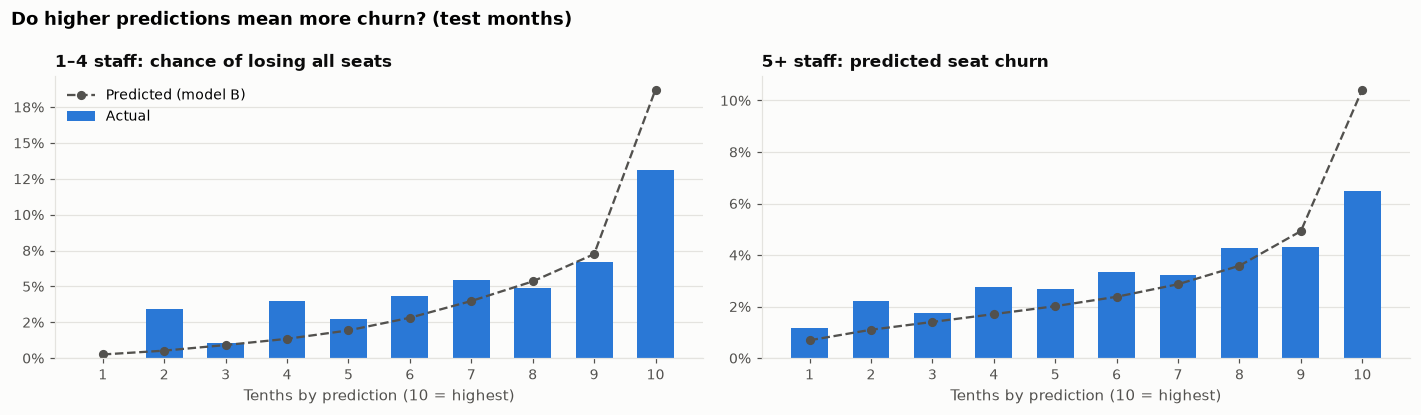

predicted tenth,predicted,actual,churned,months
1,0%,0%,0%,551
2,1%,3%,3%,550
3,1%,1%,1%,550
4,1%,4%,4%,550
5,2%,3%,3%,550
6,3%,4%,4%,550
7,4%,5%,5%,550
8,5%,5%,5%,550
9,7%,7%,7%,550
10,19%,13%,13%,550


predicted tenth,predicted,actual,churned,months
1,1%,1%,1%,190
2,1%,2%,4%,190
3,1%,2%,2%,190
4,2%,3%,3%,190
5,2%,3%,6%,190
6,2%,3%,5%,189
7,3%,3%,3%,190
8,4%,4%,7%,190
9,5%,4%,6%,190
10,10%,7%,9%,190


In [422]:
# ---------------- 2.6 Predicting churn (one pair of models per size band) ----------------
# Each band gets its own models, because the outcome differs:
#   1-4 staff: the chance the client loses all its seats in the next 3 months
#   5+ staff : the client's seat churn over the next 3 months (0-100%)
# and two feature sets:
#   A "drivers"      : attendance, payments, staff events and profile - answers "what leads to churn"
#   B "with warnings": A plus the early warnings (notices, client exits, recent churn) - best for flagging clients now
# Tested the honest way: trained on earlier snapshots, scored on later ones the model never saw.
import lightgbm as lgb
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

MODEL_PARAMS = dict(objective="cross_entropy", n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=40,
                    subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=7)
MODELS = {"A: drivers": DRIVER_FEATURES + ["region"], "B: drivers + early warnings": ALL_FEATURES + ["region"]}
PB = "pred B: drivers + early warnings"

test_from = pd.Timestamp(TEST_FROM)
is_train = snapshots["snapshot"] <= test_from - pd.Timedelta(days=HORIZON_DAYS)   # outcome windows end before the test starts
is_test = snapshots["snapshot"] >= test_from


def fit(data, cols):
    return lgb.LGBMRegressor(**MODEL_PARAMS).fit(data[cols], data["target"])


tests, scores = {}, []
for band in BAND_NAMES:
    train, test = band_rows(snapshots[is_train], band), band_rows(snapshots[is_test], band).copy()
    print(f"{band}: training {len(train):,} client-months ({train['snapshot'].min():%b %Y}-{train['snapshot'].max():%b %Y}) · "
          f"test {len(test):,} ({test['snapshot'].min():%b %Y}-{test['snapshot'].max():%b %Y}), {int(test['churned'].sum())} churned")
    for name, cols in MODELS.items():
        p = np.clip(fit(train, cols).predict(test[cols]), 0, 1)
        test[f"pred {name}"] = p
        top = p >= np.quantile(p, 0.9)
        scores.append({"size band": band, "model": name, "predicts": BANDS[band]["target_words"],
                       "finds churners (AUC)": roc_auc_score(test["churned"], p),
                       "ranking (Spearman)": spearmanr(p, test["target"]).statistic,
                       "churned, top 10% predicted": test.loc[top, "churned"].mean(),
                       "churners caught in top 10%": test.loc[top, "churned"].sum() / test["churned"].sum()})
    scores.append({"size band": band, "model": "no model (everyone the same)", "predicts": BANDS[band]["target_words"],
                   "finds churners (AUC)": 0.5, "ranking (Spearman)": np.nan,
                   "churned, top 10% predicted": test["churned"].mean(), "churners caught in top 10%": 0.10})
    tests[band] = test
model_scores = pd.DataFrame(scores)
show_table(model_scores, pct_cols=["churned, top 10% predicted", "churners caught in top 10%"],
           num_cols=["finds churners (AUC)", "ranking (Spearman)"],
           caption="How well each model does on later months it never saw (AUC: 0.5 = coin flip, about 0.7 = useful)")

# predicted vs actual, by tenths of model B's prediction (test months), one panel per band
fig, axes = plt.subplots(1, len(BAND_NAMES), figsize=(13, 3.8))
calib = {}
for ax, band in zip(axes, BAND_NAMES):
    test = tests[band]
    test["predicted tenth"] = pd.qcut(test[PB].rank(method="first"), 10, labels=range(1, 11))
    c = test.groupby("predicted tenth", observed=True).agg(predicted=(PB, "mean"), actual=("target", "mean"),
                                                           churned=("churned", "mean"), months=("Shortcode", "size"))
    calib[band] = c
    x = c.index.astype(int)
    ax.bar(x, c["actual"], color=COLORS["main"], width=0.6, label="Actual")
    ax.plot(x, c["predicted"], color=COLORS["text2"], marker="o", markersize=5, linestyle="--", linewidth=1.5, label="Predicted (model B)")
    ax.set_xticks(x, [f"{i}" for i in x])
    ax.set_xlabel("Tenths by prediction (10 = highest)")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_title(f"{band}: {BANDS[band]['target_words']}", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left")
fig.suptitle("Do higher predictions mean more churn? (test months)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()
for band in BAND_NAMES:
    show_table(calib[band].reset_index(), pct_cols=["predicted", "actual", "churned"], int_cols=["months"],
               caption=f"{band}: by tenth of predicted {BANDS[band]['target_words']} (churned = share that went on to {BANDS[band]['outcome_words']})")

## 2.6b Does it work on clients the model has never seen?
In 2.6 the same client can be in the training months and the test months, so a model could partly recognise the client instead of learning what leads to churn. Here every client is placed in one of 5 groups; each group's test-month rows are scored by a model trained only on the *other* groups' clients. The time split and settings are the same, so any drop in AUC is the cost of not having seen the client. The line on each bar is the 95% range, from resampling whole clients.

size band,model,"AUC, clients seen in training (2.6)","AUC, new clients",95% range low,95% range high,drop,"churners caught in top 10%, new clients",test rows from clients seen in training
1–4 staff,A: drivers,0.67,0.66,0.61,0.70,0.01,18%,79%
1–4 staff,B: drivers + early warnings,0.70,0.69,0.65,0.73,0.01,28%,79%
5+ staff,A: drivers,0.57,0.59,0.52,0.68,-0.03,22%,89%
5+ staff,B: drivers + early warnings,0.63,0.62,0.54,0.70,0.01,26%,89%


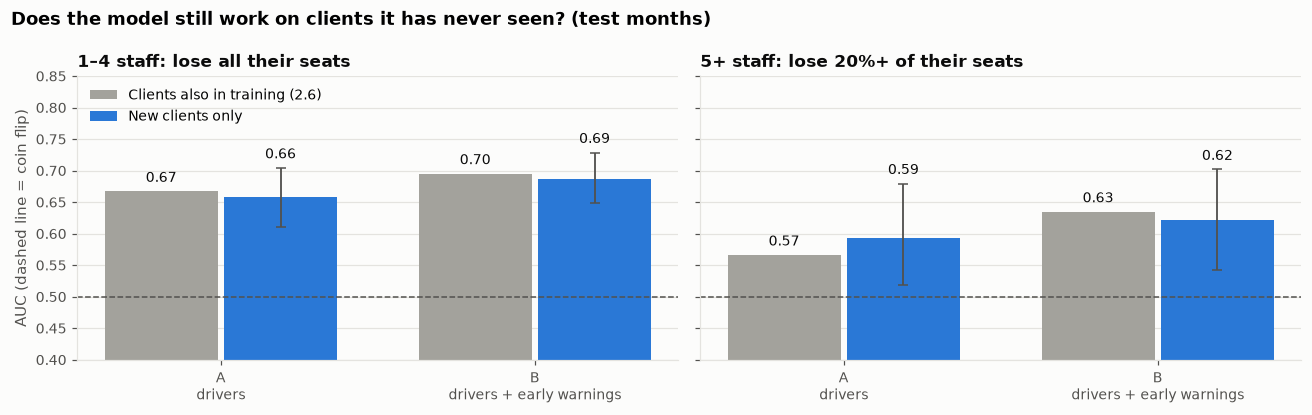

In [423]:
# ---------------- 2.6b Same test months, but on clients the model has never seen ----------------
# In 2.6 a client can be in both the training months and the test months, so the model may partly recognise the client.
# Here every client is put in one of N_FOLDS groups at random. For each group, the models are trained on the *other*
# groups' clients (training months only) and scored on this group's clients in the same test months. Every test row is
# therefore scored by a model that has never seen that client. Same split in time, same models, same settings as 2.6.
N_FOLDS = 5
all_clients = snapshots["Shortcode"].unique()
fold_of = pd.Series(np.random.default_rng(7).permutation(len(all_clients)) % N_FOLDS, index=all_clients)


def auc_with_range(y, p, clients, n_boot=300, seed=7):
    """AUC and a 95% range from resampling whole clients (a client's months are not independent)."""
    y, p = np.asarray(y), np.asarray(p)
    rows_by_client = list(pd.Series(np.arange(len(y))).groupby(np.asarray(clients)).apply(np.array))
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_by_client[i] for i in rng.integers(0, len(rows_by_client), len(rows_by_client))])
        if 0 < y[idx].sum() < len(idx):
            aucs.append(roc_auc_score(y[idx], p[idx]))
    return roc_auc_score(y, p), *np.percentile(aucs, [2.5, 97.5])


rows, new_client_pred = [], {}
for band in BAND_NAMES:
    train_b, test_b = band_rows(snapshots[is_train], band), tests[band]
    seen_share = test_b["Shortcode"].isin(train_b["Shortcode"]).mean()
    for name, cols in MODELS.items():
        pred = pd.Series(np.nan, index=test_b.index)
        for k in range(N_FOLDS):
            held = fold_of.index[fold_of == k]
            te = test_b[test_b["Shortcode"].isin(held)]
            if len(te):
                pred.loc[te.index] = np.clip(fit(train_b[~train_b["Shortcode"].isin(held)], cols).predict(te[cols]), 0, 1)
        new_client_pred[band, name] = pred
        auc_new, lo, hi = auc_with_range(test_b["churned"], pred, test_b["Shortcode"])
        top = pred >= pred.quantile(0.9)
        seen = model_scores[(model_scores["size band"] == band) & (model_scores["model"] == name)].iloc[0]
        rows.append({"size band": band, "model": name,
                     "AUC, clients seen in training (2.6)": seen["finds churners (AUC)"],
                     "AUC, new clients": auc_new, "95% range low": lo, "95% range high": hi,
                     "drop": seen["finds churners (AUC)"] - auc_new,
                     "churners caught in top 10%, new clients": test_b.loc[top, "churned"].sum() / test_b["churned"].sum(),
                     "test rows from clients seen in training": seen_share})
client_check = pd.DataFrame(rows)
show_table(client_check, pct_cols=["churners caught in top 10%, new clients", "test rows from clients seen in training"],
           num_cols=["AUC, clients seen in training (2.6)", "AUC, new clients", "95% range low", "95% range high", "drop"],
           caption="Test months scored on clients the model has never seen (AUC: 0.5 = coin flip, about 0.7 = useful)")

fig, axes = plt.subplots(1, len(BAND_NAMES), figsize=(12, 3.8), sharey=True)
for ax, band in zip(axes, BAND_NAMES):
    d = client_check[client_check["size band"] == band].reset_index(drop=True)
    x = np.arange(len(d))
    for off, col, lbl, color in [(-0.19, "AUC, clients seen in training (2.6)", "Clients also in training (2.6)", COLORS["muted"]),
                                 (0.19, "AUC, new clients", "New clients only", COLORS["main"])]:
        bars = ax.bar(x + off, d[col], width=0.36, color=color, label=lbl)
        top_of = d["95% range high"] if off > 0 else d[col]          # new-client labels sit above their whisker
        for b, v, t in zip(bars, d[col], top_of):
            ax.text(b.get_x() + b.get_width() / 2, t + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=COLORS["text"])
    ax.errorbar(x + 0.19, d["AUC, new clients"], yerr=[d["AUC, new clients"] - d["95% range low"], d["95% range high"] - d["AUC, new clients"]],
                fmt="none", ecolor=COLORS["text2"], elinewidth=1.2, capsize=3)
    ax.axhline(0.5, color=COLORS["text2"], linestyle="--", linewidth=1)
    ax.set_xticks(x, d["model"].str.replace(": ", "\n", n=1))
    ax.set_ylim(0.4, 0.85)
    ax.set_title(f"{band}: {BANDS[band]['outcome_words']}", fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("AUC (dashed line = coin flip)")
axes[0].legend(loc="upper left")
fig.suptitle("Does the model still work on clients it has never seen? (test months)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

## 2.7 Which factors matter most?
**How to read it:** the bar is the factor's share of everything that moves the model's predictions. The direction says whether a higher value pushes predicted churn up or down *after accounting for the other factors*, so it can differ from 2.4. For example, late-payment months mostly belong to long-standing clients, who churn less. For 1–4 staff, *Staff at snapshot* leads mostly because a 1-person client needs only one exit to leave entirely.

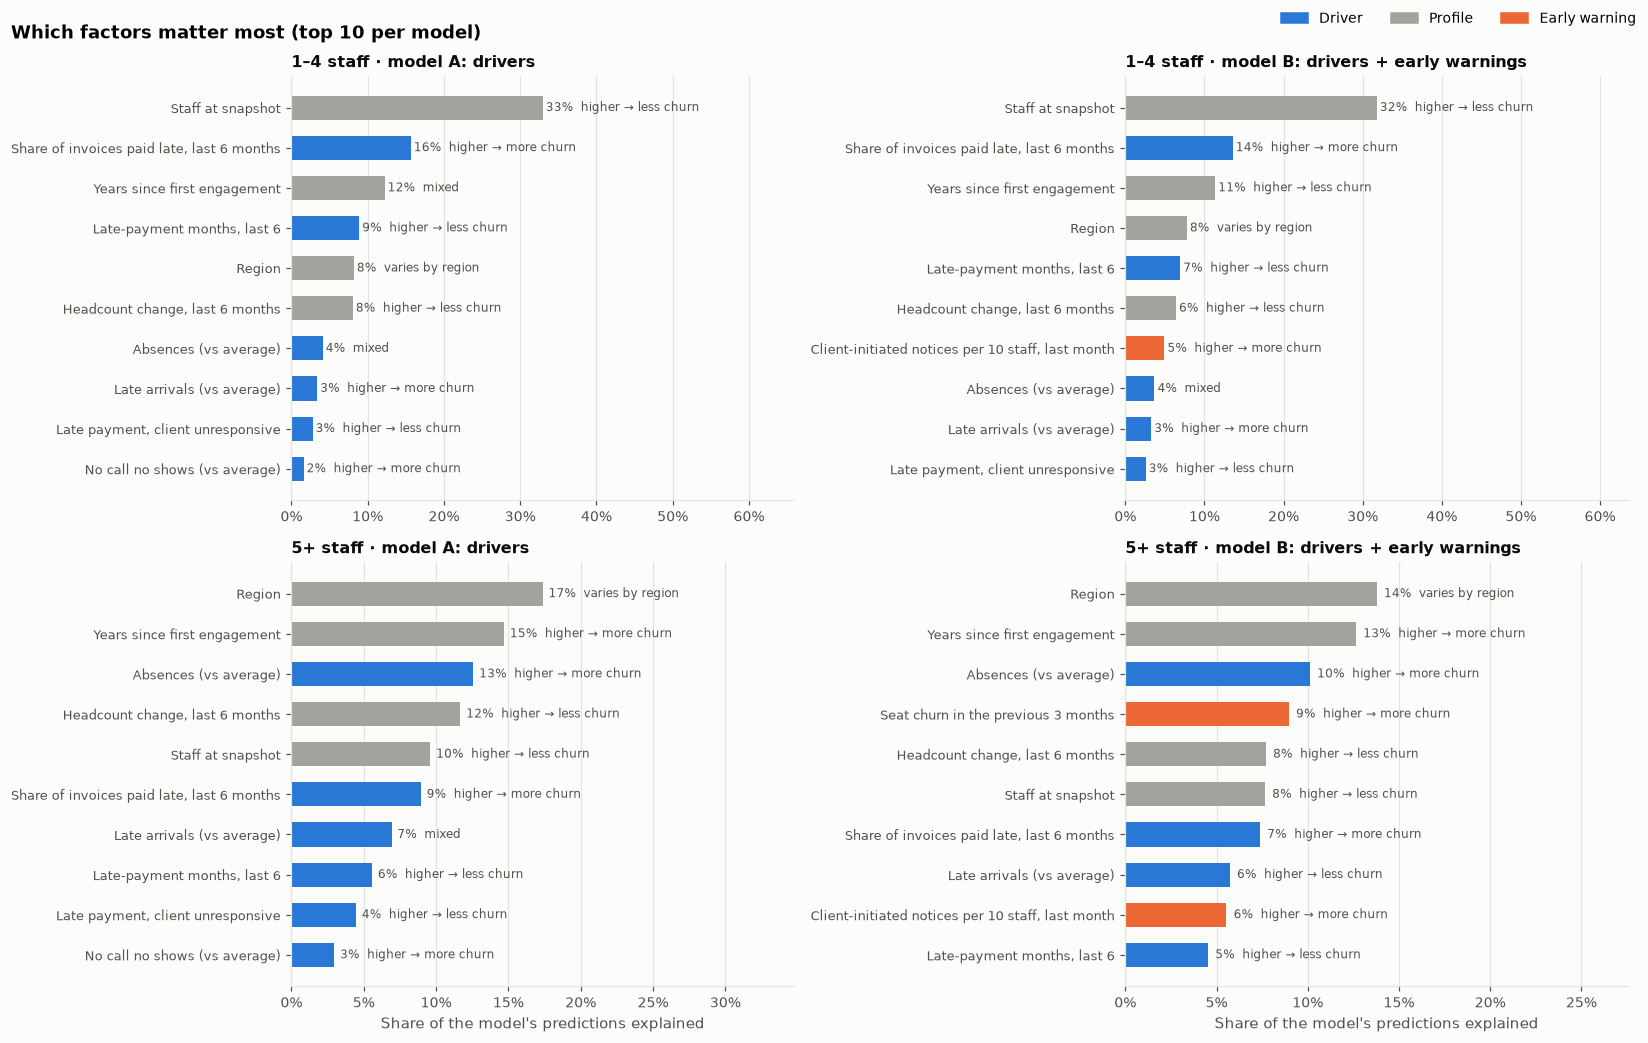

factor,group,importance,direction
Staff at snapshot,Profile,33%,higher → less churn
"Share of invoices paid late, last 6 months",Driver: payments,16%,higher → more churn
Years since first engagement,Profile,12%,mixed
"Late-payment months, last 6",Driver: payments,9%,higher → less churn
Region,Profile,8%,varies by region
"Headcount change, last 6 months",Profile,8%,higher → less churn
Absences (vs average),Driver: attendance,4%,mixed
Late arrivals (vs average),Driver: attendance,3%,higher → more churn
"Late payment, client unresponsive",Driver: payments,3%,higher → less churn
No call no shows (vs average),Driver: attendance,2%,higher → more churn


factor,group,importance,direction
Staff at snapshot,Profile,32%,higher → less churn
"Share of invoices paid late, last 6 months",Driver: payments,14%,higher → more churn
Years since first engagement,Profile,11%,higher → less churn
Region,Profile,8%,varies by region
"Late-payment months, last 6",Driver: payments,7%,higher → less churn
"Headcount change, last 6 months",Profile,6%,higher → less churn
"Client-initiated notices per 10 staff, last month",Early warning,5%,higher → more churn
Absences (vs average),Driver: attendance,4%,mixed
Late arrivals (vs average),Driver: attendance,3%,higher → more churn
"Late payment, client unresponsive",Driver: payments,3%,higher → less churn


factor,group,importance,direction
Region,Profile,17%,varies by region
Years since first engagement,Profile,15%,higher → more churn
Absences (vs average),Driver: attendance,13%,higher → more churn
"Headcount change, last 6 months",Profile,12%,higher → less churn
Staff at snapshot,Profile,10%,higher → less churn
"Share of invoices paid late, last 6 months",Driver: payments,9%,higher → more churn
Late arrivals (vs average),Driver: attendance,7%,mixed
"Late-payment months, last 6",Driver: payments,6%,higher → less churn
"Late payment, client unresponsive",Driver: payments,4%,higher → less churn
No call no shows (vs average),Driver: attendance,3%,higher → more churn


factor,group,importance,direction
Region,Profile,14%,varies by region
Years since first engagement,Profile,13%,higher → more churn
Absences (vs average),Driver: attendance,10%,higher → more churn
Seat churn in the previous 3 months,Early warning,9%,higher → more churn
"Headcount change, last 6 months",Profile,8%,higher → less churn
Staff at snapshot,Profile,8%,higher → less churn
"Share of invoices paid late, last 6 months",Driver: payments,7%,higher → more churn
Late arrivals (vs average),Driver: attendance,6%,higher → less churn
"Client-initiated notices per 10 staff, last month",Early warning,6%,higher → more churn
"Late-payment months, last 6",Driver: payments,5%,higher → less churn


In [424]:
# ---------------- 2.7 Which factors matter most? (model explanations, by size band) ----------------
# Each band's models are refitted on all of that band's snapshots, and SHAP measures how much each factor moves each
# prediction. Importance = the factor's share of all movement; direction = whether a higher value means more or less
# predicted churn, after accounting for the other factors.
import shap


def explain(data, cols):
    m = fit(data, cols)
    sv = pd.DataFrame(shap.TreeExplainer(m).shap_values(data[cols]), columns=cols, index=data.index)
    imp = sv.abs().mean()
    out = []
    for c in cols:
        x = pd.to_numeric(data[c], errors="coerce") if c != "region" else None
        rho = spearmanr(x, sv[c], nan_policy="omit").statistic if x is not None and x.nunique() > 1 else np.nan
        direction = ("varies by region" if c == "region" else "higher → more churn" if rho > 0.1
                     else "higher → less churn" if rho < -0.1 else "mixed")
        out.append({"factor": LABEL.get(c, "Region"), "group": GROUP.get(c, "Profile"), "importance": imp[c] / imp.sum(), "direction": direction})
    return m, pd.DataFrame(out).sort_values("importance", ascending=False).reset_index(drop=True)


final_models, drivers = {}, {}   # (band, model name) -> fitted model / ranked factors
for band in BAND_NAMES:
    for name, cols in MODELS.items():
        final_models[band, name], drivers[band, name] = explain(band_rows(snapshots, band), cols)

TOP_N = 10
fig, axes = plt.subplots(len(BAND_NAMES), len(MODELS), figsize=(15, 9.5))
for r, band in enumerate(BAND_NAMES):
    for c, name in enumerate(MODELS):
        ax, d = axes[r][c], drivers[band, name].head(TOP_N).iloc[::-1]
        cols = [COLORS["second"] if g == "Early warning" else COLORS["muted"] if g == "Profile" else COLORS["main"] for g in d["group"]]
        ax.barh(d["factor"], d["importance"], color=cols, height=0.6)
        for yy, (v, dirn) in enumerate(zip(d["importance"], d["direction"])):
            ax.text(v + 0.004, yy, f"{v:.0%}  {dirn}", va="center", fontsize=8, color=COLORS["text2"])
        ax.set_xlim(0, d["importance"].max() * 2)
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
        ax.set_title(f"{band} · model {name}", fontsize=10.5)
        ax.tick_params(axis="y", labelsize=8.5)
        ax.grid(axis="y", visible=False)
for ax in axes[-1]:
    ax.set_xlabel("Share of the model's predictions explained")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=COLORS["main"], label="Driver"), Patch(color=COLORS["muted"], label="Profile"),
                    Patch(color=COLORS["second"], label="Early warning")], loc="upper right", ncol=3)
fig.suptitle(f"Which factors matter most (top {TOP_N} per model)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()
for band in BAND_NAMES:
    for name in MODELS:
        show_table(drivers[band, name], pct_cols=["importance"], caption=f"{band} · model {name}: most important first")

## 2.8 Where to set the flag?
Each band gets its own threshold, chosen on the test months for the best balance between flagging clients that really churn (precision) and catching the clients that do (recall). For 5+ staff a 50% threshold catches almost nobody, because few client-months lose half their seats; for 1–4 staff the chance of a full exit runs higher, so a 50% threshold can work.

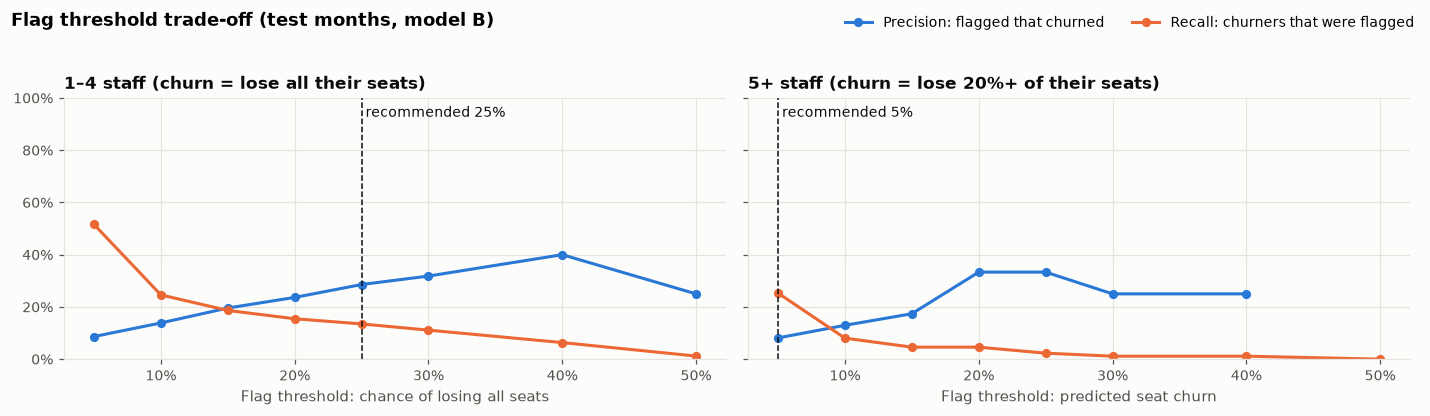

threshold,flagged per month,share of clients flagged,flagged that churned (precision),churners flagged (recall),balance (F1)
5%,187.62,27%,9%,52%,0.15
10%,55.88,8%,14%,25%,0.18
15%,30.00,4%,20%,19%,0.19
20%,20.62,3%,24%,15%,0.19
25%,14.88,2%,29%,13%,0.18
30%,11.00,2%,32%,11%,0.16
40%,5.00,1%,40%,6%,0.11
50%,1.50,0%,25%,1%,0.02


threshold,flagged per month,share of clients flagged,flagged that churned (precision),churners flagged (recall),balance (F1)
5%,33.75,14%,8%,25%,0.12
10%,6.75,3%,13%,8%,0.10
15%,2.88,1%,17%,5%,0.07
20%,1.50,1%,33%,5%,0.08
25%,0.75,0%,33%,2%,0.04
30%,0.50,0%,25%,1%,0.02
40%,0.50,0%,25%,1%,0.02
50%,0.00,0%,–,0%,0.00


**1–4 staff:** flag clients whose chance of losing all seats is 25% or more. On the test months that flags about 15 clients a month (2%); 29% of them went on to lose all their seats (vs 5% of all clients in the band), and it caught 13% of those who did.

**5+ staff:** flag clients whose predicted seat churn is 5% or more. On the test months that flags about 34 clients a month (14%); 8% of them went on to lose 20%+ of their seats (vs 5% of all clients in the band), and it caught 25% of those who did.

For 5+ staff, a 50% threshold flags 0.0 clients a month: the model rarely predicts that much churn, because only 1% of their client-months lose half their seats.

In [425]:
# ---------------- 2.8 Where to set the flag? (one threshold per size band) ----------------
# A client is flagged when its band's model B prediction is at or above the threshold. For each threshold, on the test
# months: how many clients a month get flagged, how many of those really churned (precision), and how many of the
# clients who churned were flagged (recall). The recommendation is the threshold with the best balance (F1); when
# thresholds are within 0.01 of the best, the higher one wins (fewer, surer flags for the same balance).
flag_tables, RECOMMENDED_THRESHOLD, recommendation = {}, {}, {}
for band in BAND_NAMES:
    test = tests[band]
    n_months = test["snapshot"].nunique()
    rows = []
    for th in FLAG_THRESHOLDS:
        flag = test[PB] >= th
        tp = (flag & test["churned"]).sum()
        rows.append({"threshold": th, "flagged per month": flag.sum() / n_months, "share of clients flagged": flag.mean(),
                     "flagged that churned (precision)": tp / flag.sum() if flag.sum() else np.nan,
                     "churners flagged (recall)": tp / test["churned"].sum()})
    ft = pd.DataFrame(rows)
    p_, r_ = ft["flagged that churned (precision)"], ft["churners flagged (recall)"]
    ft["balance (F1)"] = (2 * p_ * r_ / (p_ + r_)).fillna(0)
    near_best = ft[ft["balance (F1)"] >= ft["balance (F1)"].max() - 0.01]
    th = float(near_best["threshold"].max())
    rec = ft.set_index("threshold").loc[th]
    flag_tables[band], RECOMMENDED_THRESHOLD[band] = ft, th
    recommendation[band] = (f"**{band}:** flag clients whose {BANDS[band]['target_words']} is {th:.0%} or more. On the test months that flags "
                            f"about {rec['flagged per month']:.0f} clients a month ({rec['share of clients flagged']:.0%}); "
                            f"{rec['flagged that churned (precision)']:.0%} of them went on to {BANDS[band]['outcome_words']} "
                            f"(vs {test['churned'].mean():.0%} of all clients in the band), and it caught {rec['churners flagged (recall)']:.0%} of those who did.")

fig, axes = plt.subplots(1, len(BAND_NAMES), figsize=(13, 3.8), sharey=True)
for ax, band in zip(axes, BAND_NAMES):
    ft, th = flag_tables[band], RECOMMENDED_THRESHOLD[band]
    ax.plot(ft["threshold"], ft["flagged that churned (precision)"], color=COLORS["main"], marker="o", markersize=5, label="Precision: flagged that churned")
    ax.plot(ft["threshold"], ft["churners flagged (recall)"], color=COLORS["second"], marker="o", markersize=5, label="Recall: churners that were flagged")
    ax.axvline(th, color=COLORS["text"], linestyle="--", linewidth=1)
    right = th >= max(FLAG_THRESHOLDS)
    ax.text(th, 0.97, f"recommended {th:.0%} " if right else f" recommended {th:.0%}", va="top", ha="right" if right else "left", fontsize=9, color=COLORS["text"])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_ylim(0, 1)
    ax.set_xlabel(f"Flag threshold: {BANDS[band]['target_words']}")
    ax.set_title(f"{band} (churn = {BANDS[band]['outcome_words']})", fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, bbox_to_anchor=(1, 1.0))
fig.suptitle("Flag threshold trade-off (test months, model B)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
for band in BAND_NAMES:
    show_table(flag_tables[band], pct_cols=["threshold", "share of clients flagged", "flagged that churned (precision)", "churners flagged (recall)"],
               num_cols=["flagged per month", "balance (F1)"], caption=f"{band}: flag thresholds compared")

text = "\n\n".join(recommendation.values())
at50 = flag_tables["5+ staff"].set_index("threshold").loc[0.50] if 0.50 in FLAG_THRESHOLDS else None
if at50 is not None:
    text += (f"\n\nFor 5+ staff, a 50% threshold flags {at50['flagged per month']:.1f} clients a month: the model rarely predicts that much "
             f"churn, because only {(band_rows(snapshots, '5+ staff')['seat_churn_next_3m'] >= 0.5).mean():.0%} of their client-months lose half their seats.")
from IPython.display import Markdown
display(Markdown(text))

## 2.9 Clients to watch now

In [426]:
# ---------------- 2.9 Clients to watch now ----------------
# Today's snapshot (1st of this month), each client scored by its band's model B (refitted on every snapshot with a
# known outcome). Flagged = prediction at or above the band's recommended threshold. "Main reasons" are the three
# factors pushing that client's prediction up the most. Sources with no recent data (e.g. Absences) are blank.
now = pd.Timestamp.today().normalize().replace(day=1)
current = add_features(build_snapshots([now], with_outcome=False))
cols_b = MODELS["B: drivers + early warnings"]
parts = []
for band in BAND_NAMES:
    d = band_rows(current, band).copy()
    m = final_models[band, "B: drivers + early warnings"]
    d["prediction"] = np.clip(m.predict(d[cols_b]), 0, 1)
    sv = pd.DataFrame(shap.TreeExplainer(m).shap_values(d[cols_b]), columns=cols_b, index=d.index)
    d["main reasons"] = ["; ".join(LABEL.get(c, "Region") for c, v in sv.loc[i].sort_values(ascending=False).head(3).items() if v > 0)
                         for i in d.index]
    d["predicts"] = BANDS[band]["target_words"]
    d["flag"] = d["prediction"] >= RECOMMENDED_THRESHOLD[band]
    parts.append(d)
current = pd.concat(parts)
watch = (current[current["flag"]].sort_values(["size_band", "prediction"], ascending=[False, False])
         [["Shortcode", "size_band", "staff", "predicts", "prediction", "main reasons"]].rename(columns={"size_band": "size band"}))
summary = current.groupby("size_band").agg(clients=("Shortcode", "size"), flagged=("flag", "sum")).reindex(BAND_NAMES)
print(f"{now:%d %b %Y}: " + " · ".join(f"{b}: {r.flagged:,} of {r.clients:,} clients flagged at {RECOMMENDED_THRESHOLD[b]:.0%}+"
                                       for b, r in summary.iterrows()))
show_table(watch, pct_cols=["prediction"], int_cols=["staff"], caption=f"Clients to watch ({now:%b %Y})")

01 Nov 2026: 1–4 staff: 8 of 754 clients flagged at 25%+ · 5+ staff: 21 of 254 clients flagged at 5%+


Shortcode,size band,staff,predicts,prediction,main reasons
REMMAP,5+ staff,5,predicted seat churn,46%,"Client-initiated notices per 10 staff, last month; Years since first engagement; Region"
DOMINGUEZFIRM,5+ staff,7,predicted seat churn,20%,Region; Cloudstaff-initiated exits per 10 staff; Seat churn in the previous 3 months
ADRENTAL,5+ staff,26,predicted seat churn,14%,"Region; Headcount change, last 6 months; Years since first engagement"
OPAVISION,5+ staff,5,predicted seat churn,11%,"Years since first engagement; Staff at snapshot; Headcount change, last 6 months"
REPLI,5+ staff,9,predicted seat churn,10%,"Years since first engagement; Client-initiated notices per 10 staff, last month; Seat churn in the previous 3 months"
OPIHARMONYFIRE,5+ staff,7,predicted seat churn,10%,"Share of invoices paid late, last 6 months; Headcount change, last 6 months; Client-initiated notices per 10 staff, last month"
POWERDRY,5+ staff,12,predicted seat churn,10%,"Client-initiated notices per 10 staff, last month; Seat churn in the previous 3 months; Headcount change, last 6 months"
GDR,5+ staff,5,predicted seat churn,9%,"Client-initiated notices per 10 staff, last month; Staff at snapshot; Region"
ZILKERTRAIL,5+ staff,11,predicted seat churn,8%,"Client-initiated notices per 10 staff, last month; Region; Years since first engagement"
ARRIVIA,5+ staff,355,predicted seat churn,8%,Seat churn in the previous 3 months; Region; Cloudstaff-initiated exits per 10 staff


## 2.10 Key findings

In [427]:
# ---------------- 2.10 Key findings (written from the results above, so they update when the data does) ----------------
from IPython.display import Markdown


def bullets(d):
    return "\n".join(f"  - {r['event before the snapshot']}: **{r['x times as likely']:.1f}x** as likely "
                     f"({r['churn with']:.0%} vs {r['churn without']:.0%})" for _, r in d.sort_values("x times as likely", ascending=False).iterrows()) or "  - none"


sections = []
for band in BAND_NAMES:
    rb = risk[risk["size band"] == band]
    up = rb[(rb["clear signal"] == "yes") & (rb["x times as likely"] > 1)]
    down = rb[(rb["clear signal"] == "yes") & (rb["x times as likely"] < 1)]
    not_clear = rb[rb["group"].str.startswith("Driver") & (rb["clear signal"] != "yes")]["event before the snapshot"].tolist()
    sc = model_scores[(model_scores["size band"] == band)].set_index("model")
    cc = client_check[client_check["size band"] == band].set_index("model")
    d = band_rows(snapshots, band)
    tm = timing[(timing["size band"] == band) & (timing["my grouping"] != "Profile")]
    sections.append(f"""
### {band}
**Churn here means:** {BANDS[band]['outcome_words']} within 3 months, not counting exits for {', '.join(c.replace('exit_client_', '').replace('_', ' ') for c in OUTCOME_EXCLUDE) or 'no reason'}. That happens in {d['churned'].mean():.0%} of client-months ({d['Shortcode'].nunique():,} clients).

**Events that clearly come before churn** (the 95% range doesn't cross 1x):
- Drivers:
{bullets(up[up['group'].str.startswith('Driver')])}
- Client profile:
{bullets(up[up['group'] == 'Profile'])}
- Early warnings:
{bullets(up[up['group'] == 'Early warning'])}

**Linked to less churn:** {'; '.join(f"{r['event before the snapshot']} ({r['x times as likely']:.1f}x)" for _, r in down.iterrows()) or 'none'}.

**Drivers that are not a clear signal on their own:** {'; '.join(not_clear) or 'none'}.

**Timing check:** {(tm['agrees with my grouping?'] == 'yes').sum()} of {len(tm)} driver and early-warning events behave as their group predicts; {(tm['agrees with my grouping?'] == 'no signal').sum()} show no rise before churn (table in 2.5).

**Most important factors, drivers-only model:** {'; '.join(drivers[band, 'A: drivers']['factor'].head(5))}.

**How predictable?** On months the models never saw: drivers only AUC {sc.loc['A: drivers', 'finds churners (AUC)']:.2f}; with early warnings AUC {sc.loc['B: drivers + early warnings', 'finds churners (AUC)']:.2f}, whose top 10% of predictions catch {sc.loc['B: drivers + early warnings', 'churners caught in top 10%']:.0%} of the clients who churn. On clients the models had never seen (2.6b) the AUCs are {cc.loc['A: drivers', 'AUC, new clients']:.2f} and {cc.loc['B: drivers + early warnings', 'AUC, new clients']:.2f}, a drop of at most {cc['drop'].max():.2f}.

{recommendation[band]}
""")
display(Markdown("\n".join(sections)))


### 1–4 staff
**Churn here means:** lose all their seats within 3 months, not counting exits for business reasons. That happens in 5% of client-months (1,342 clients).

**Events that clearly come before churn** (the 95% range doesn't cross 1x):
- Drivers:
  - Any staff resignation, last 3 months: **1.7x** as likely (8% vs 5%)
  - Absences at 2x the band average or more: **1.5x** as likely (7% vs 5%)
  - No call no shows at 2x the band average or more: **1.4x** as likely (7% vs 5%)
  - Late arrivals at 2x the band average or more: **1.3x** as likely (6% vs 5%)
- Client profile:
  - Smallest in its band (1–2 or 5–9 staff): **3.8x** as likely (6% vs 2%)
  - Headcount down 10%+ over 6 months: **2.0x** as likely (8% vs 4%)
  - Client for under 1 year: **1.4x** as likely (6% vs 4%)
- Early warnings:
  - Client-initiated notice, last month: **4.7x** as likely (20% vs 4%)
  - Not replaced: client pull-out, budget, onshore: **2.6x** as likely (12% vs 5%)
  - Lost a seat in the previous 3 months: **2.0x** as likely (9% vs 4%)
  - Lost 20%+ of seats in the previous 3 months: **2.0x** as likely (9% vs 4%)

**Linked to less churn:** Any late payment, last 6 months (0.8x); Headcount up 25%+ over 6 months (0.1x).

**Drivers that are not a clear signal on their own:** Any no call no show, last 3 months; Any late arrival, last 3 months; Any absence, last 3 months; Late on 3+ of the last 6 invoices; Late payment, client unresponsive; Cloudstaff-initiated exit, last 3 months.

**Timing check:** 2 of 17 driver and early-warning events behave as their group predicts; 8 show no rise before churn (table in 2.5).

**Most important factors, drivers-only model:** Staff at snapshot; Share of invoices paid late, last 6 months; Years since first engagement; Late-payment months, last 6; Region.

**How predictable?** On months the models never saw: drivers only AUC 0.67; with early warnings AUC 0.70, whose top 10% of predictions catch 29% of the clients who churn. On clients the models had never seen (2.6b) the AUCs are 0.66 and 0.69, a drop of at most 0.01.

**1–4 staff:** flag clients whose chance of losing all seats is 25% or more. On the test months that flags about 15 clients a month (2%); 29% of them went on to lose all their seats (vs 5% of all clients in the band), and it caught 13% of those who did.


### 5+ staff
**Churn here means:** lose 20%+ of their seats within 3 months, not counting exits for business reasons. That happens in 6% of client-months (348 clients).

**Events that clearly come before churn** (the 95% range doesn't cross 1x):
- Drivers:
  - Cloudstaff-initiated exit, last 3 months: **2.5x** as likely (13% vs 5%)
  - Absences at 2x the band average or more: **2.4x** as likely (12% vs 5%)
  - Late arrivals at 2x the band average or more: **2.1x** as likely (10% vs 5%)
- Client profile:
  - Headcount down 10%+ over 6 months: **2.3x** as likely (10% vs 4%)
  - Smallest in its band (1–2 or 5–9 staff): **1.9x** as likely (7% vs 4%)
  - Client for under 1 year: **1.7x** as likely (9% vs 5%)
- Early warnings:
  - Lost 20%+ of seats in the previous 3 months: **3.8x** as likely (18% vs 5%)
  - Client-initiated notice, last month: **1.9x** as likely (9% vs 5%)
  - Lost a seat in the previous 3 months: **1.7x** as likely (8% vs 5%)
  - Exit for service dissatisfaction, last 3 months: **1.5x** as likely (8% vs 5%)

**Linked to less churn:** none.

**Drivers that are not a clear signal on their own:** Any no call no show, last 3 months; No call no shows at 2x the band average or more; Any late arrival, last 3 months; Any absence, last 3 months; Any late payment, last 6 months; Late on 3+ of the last 6 invoices; Late payment, client unresponsive; Any staff resignation, last 3 months.

**Timing check:** 7 of 17 driver and early-warning events behave as their group predicts; 9 show no rise before churn (table in 2.5).

**Most important factors, drivers-only model:** Region; Years since first engagement; Absences (vs average); Headcount change, last 6 months; Staff at snapshot.

**How predictable?** On months the models never saw: drivers only AUC 0.57; with early warnings AUC 0.63, whose top 10% of predictions catch 20% of the clients who churn. On clients the models had never seen (2.6b) the AUCs are 0.59 and 0.62, a drop of at most 0.01.

**5+ staff:** flag clients whose predicted seat churn is 5% or more. On the test months that flags about 34 clients a month (14%); 8% of them went on to lose 20%+ of their seats (vs 5% of all clients in the band), and it caught 25% of those who did.


## 2.11 Charts for the exec readout
Two charts in plain language for presenting the findings, drawn from 2.4 and 2.4b so they update with the data.
1. **Warning signs, ranked:** how many times as likely a client is to churn after each sign, for both client sizes. Grey bars are not clear signals (could be chance).
2. **Combinations:** churn after each sign on its own vs both together, for the pairs where the combination is clearly stronger than either sign alone and at least one sign is something we can act on.

In [ ]:
# ---------------- 2.11 Charts for the exec readout ----------------
# Two charts in plain language, drawn from the results above (2.4 and 2.4b), so they update with the data.
#   1. Warning signs, ranked: how much more likely churn is after each sign, for both client sizes
#   2. Combinations: churn after each sign on its own vs both together
import textwrap

KIND_COLOR = {"act": COLORS["main"], "profile": COLORS["muted"], "late": COLORS["second"]}
KIND_LABEL = {"act": "Early sign we can act on", "profile": "Client profile", "late": "Late stage: client already leaving"}
SIGNS = [  # 2.4 event -> (plain label, kind), in display order within each kind
    ("Absences at 2x the band average or more", "Absences at 2x normal", "act"),
    ("Late arrivals at 2x the band average or more", "Late arrivals at 2x normal", "act"),
    ("No call no shows at 2x the band average or more", "No call no shows at 2x normal", "act"),
    ("Cloudstaff-initiated exit, last 3 months", "Staff let go by Cloudstaff (AWOL, behaviour, fraud)", "act"),
    ("Any staff resignation, last 3 months", "A staff member resigned", "act"),
    ("Exit for service dissatisfaction, last 3 months", "Staff exit for service dissatisfaction", "act"),
    ("Any late payment, last 6 months", "Paid an invoice late", "act"),
    ("Headcount down 10%+ over 6 months", "Headcount down 10%+ in 6 months", "profile"),
    ("Client for under 1 year", "Client for less than a year", "profile"),
    ("Client-initiated notice, last month", "Client gave notice in the last month", "late"),
    (f"Lost {HIGH_CHURN:.0%}+ of seats in the previous 3 months", f"Already lost {HIGH_CHURN:.0%}+ of seats recently", "late"),
]
PLAIN = {  # 2.4b short names -> plain language
    "NCNS 2x": "No call no shows at 2x normal", "Late arrivals 2x": "Late arrivals at 2x normal", "Absences 2x": "Absences at 2x normal",
    "Any late payment": "Paid an invoice late", "Late pay, unresponsive": "Unresponsive about a late payment",
    "Staff resignation": "A staff member resigned", "Cloudstaff exit": "Staff let go by Cloudstaff",
    "Headcount down 10%+": "Headcount down 10%+", "Client < 1 year": "Client for less than a year",
    "Smallest in band": "Smallest clients (1–2 or 5–9 staff)", "Service-dissatisfaction exit": "Exit for service dissatisfaction",
    "Business-reason exit": "Exit for business reasons", "Not replaced: client risk": "Client not replacing staff (pulling out, budget)",
    "Client notice": "Client gave notice", "Lost a seat, last 3m": "Lost a seat recently",
}
EXEC_BANDS = ["5+ staff", "1–4 staff"]   # larger clients first: most seats at stake
wrap = lambda s, w=26: "\n".join(textwrap.wrap(s, w))
SMALLEST = {"1–4 staff": "Client has 1–2 staff", "5+ staff": "Client has 5–9 staff"}     # "smallest in band" means different things per band
plain_name = lambda short, band: SMALLEST[band] if short == "Smallest in band" else PLAIN[short]

# ---- 1. Warning signs, ranked ----
rank = []
for band in EXEC_BANDS:
    rb = risk[risk["size band"] == band].set_index("event before the snapshot")
    for event, plain, kind in SIGNS:
        r = rb.loc[event]
        rank.append({"size band": band, "warning sign": plain, "kind": kind, "x as likely": r["x times as likely"],
                     "churn with it": r["churn with"], "churn without": r["churn without"], "clear": r["clear signal"] == "yes"})
rank = pd.DataFrame(rank)
order = []                                   # within each kind, strongest first for the larger clients
for kind in KIND_COLOR:
    k = rank[(rank["size band"] == EXEC_BANDS[0]) & (rank["kind"] == kind)]
    order += list(k.assign(s=k["x as likely"].where(k["clear"], 0)).sort_values("s", ascending=False)["warning sign"])

top = rank[(rank["size band"] == EXEC_BANDS[0]) & (rank["kind"] == "act") & rank["clear"]].sort_values("x as likely", ascending=False)
title = (f"The strongest early warning signs for clients with 5+ staff: \"{top.iloc[0]['warning sign']}\" ({top.iloc[0]['x as likely']:.1f}x as "
         f"likely to churn) and \"{top.iloc[1]['warning sign']}\" ({top.iloc[1]['x as likely']:.1f}x)" if len(top) > 1 else "Warning signs before churn")
fig, axes = plt.subplots(1, len(EXEC_BANDS), figsize=(14, 0.5 * len(order) + 2.4), sharey=True, gridspec_kw={"wspace": 0.12})
ypos = np.arange(len(order))[::-1]
xmax = max(4.5, rank["x as likely"].max() * 1.15)
for ax, band in zip(axes, EXEC_BANDS):
    d = rank[rank["size band"] == band].set_index("warning sign").loc[order]
    for y, (sign, r) in zip(ypos, d.iterrows()):
        col = KIND_COLOR[r["kind"]]
        if r["clear"]:
            ax.barh(y, r["x as likely"], color=col, height=0.62)
            note = "  (less churn)" if r["x as likely"] < 1 else ""
            ax.text(max(r["x as likely"], 1) + 0.06, y, f"{r['x as likely']:.1f}x{note}", va="center", fontsize=10, fontweight="bold", color=COLORS["text"])
        else:
            ax.barh(y, r["x as likely"], color=COLORS["grid"], height=0.62)
            ax.text(max(r["x as likely"], 1) + 0.06, y, "not a clear signal", va="center", fontsize=9, color=COLORS["text2"], style="italic")
    ax.axvline(1, color=COLORS["text"], linewidth=1.2)
    ax.text(1.04, -0.75, "1x = no difference", fontsize=8.5, color=COLORS["text2"], va="center")
    ax.set_xlim(0, xmax)
    ax.set_ylim(-1.1, len(order) - 0.4)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}x"))
    ax.grid(axis="y", visible=False)
    base = band_rows(snapshots, band)["churned"].mean()
    ax.set_title(f"Clients with {band}", fontsize=12, loc="left", pad=22)
    ax.text(0, 1.015, f"churn = {BANDS[band]['outcome_words'].replace('their', 'its')} in 3 months; normally {base:.0%}",
            transform=ax.transAxes, fontsize=9, color=COLORS["text2"], va="bottom")
    ax.set_xlabel("How many times as likely to churn")
axes[0].set_yticks(ypos, order, fontsize=10)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=KIND_LABEL[k]) for k, c in KIND_COLOR.items()] + [Patch(color=COLORS["grid"], label="Not a clear signal")],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01), fontsize=9.5)
fig.suptitle(wrap(title, 115), x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.subplots_adjust(top=1 - 1.25 / fig.get_figheight())         # room for the two-line title above the panel titles
plt.show()

wide = rank.pivot(index="warning sign", columns="size band", values="x as likely").loc[order, EXEC_BANDS]
clear = rank.pivot(index="warning sign", columns="size band", values="clear").loc[order, EXEC_BANDS]
show_table(wide.where(clear).reset_index().rename(columns={b: f"{b}: x as likely" for b in EXEC_BANDS}),
           num_cols=[f"{b}: x as likely" for b in EXEC_BANDS], caption="Warning signs, ranked (blank = not a clear signal)")

# ---- 2. Combinations matter more than single signs ----
FULL_OF = {v: k for k, v in PAIR_EVENTS.items()}
is_driver = lambda short: EVENTS[FULL_OF[short]][0].startswith("Driver")
N_PAIRS = {"5+ staff": 4, "1–4 staff": 3}
MAX_PREVALENCE = 0.5   # a "sign" most clients have (e.g. any late payment in 6 months: ~3 in 4 clients with 5+ staff) is the
                       # normal state, not a warning, so pairs that include one are not shown
combo_rows = []
for band in EXEC_BANDS:
    known = event_flags.loc[band_rows(snapshots, band).index]
    prevalence = {short: (known[full] == 1).sum() / known[full].notna().sum() for full, short in PAIR_EVENTS.items()}
    p = pairs[(pairs["size band"] == band) & (pairs["stronger together"] == "yes")].copy()
    p = p[p["event 1"].map(is_driver) | p["event 2"].map(is_driver)]          # at least one sign we can act on
    p = p[(p["event 1"].map(prevalence) <= MAX_PREVALENCE) & (p["event 2"].map(prevalence) <= MAX_PREVALENCE)]
    p = p.sort_values("together vs stronger alone", ascending=False).head(N_PAIRS[band])
    if p.empty:
        continue
    base_all = band_rows(snapshots, band)["churned"].mean()
    rows = []                                                                    # (label, value, style) top to bottom
    for _, r in p.iterrows():
        a, b = plain_name(r["event 1"], band), plain_name(r["event 2"], band)
        rows += [(f"{a}  +  {b}", None, "head"), (f"{a}, alone", r["only event 1"], "alone"),
                 (f"{b}, alone", r["only event 2"], "alone"), ("Both together", r["churn with both"], "both"), ("", None, "gap")]
        combo_rows.append({"size band": band, "warning signs": f"{a} + {b}", "first only": r["only event 1"], "second only": r["only event 2"],
                           "both together": r["churn with both"], "neither": r["neither"], "client-months with both": r["client-months with both"],
                           "together vs stronger alone": r["together vs stronger alone"], "_range": r["_range"],
                           "_event 1": r["event 1"], "_event 2": r["event 2"]})          # 2.4b short names, used by the one-pager export
    rows = rows[:-1]
    y = np.arange(len(rows))[::-1]
    fig, ax = plt.subplots(figsize=(11, 0.36 * len(rows) + 1.6))
    vmax = max(v for _, v, k in rows if v is not None)
    for yy, (label, v, kind) in zip(y, rows):
        if kind == "head":
            ax.text(0, yy - 0.1, label, ha="left", va="center", fontsize=10.5, fontweight="bold", color=COLORS["text"])   # heading across the plot
        elif kind in ("alone", "both"):
            ax.barh(yy, v, height=0.72, color=COLORS["flag"] if kind == "both" else COLORS["muted"])
            ax.text(v + vmax * 0.01, yy, f"{v:.0%}", va="center", fontsize=10, fontweight="bold" if kind == "both" else "normal", color=COLORS["text"])
            ax.text(-0.005, yy, label, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=9.5,
                    color=COLORS["text"] if kind == "both" else COLORS["text2"])
    ax.axvline(base_all, color=COLORS["text2"], linestyle="--", linewidth=1)
    ax.text(base_all, len(rows) - 0.3, f" all clients: {base_all:.0%}", fontsize=8.5, color=COLORS["text2"], va="bottom")
    ax.set_yticks([])
    ax.set_ylim(-0.7, len(rows) + 0.2)
    ax.set_xlim(0, vmax * 1.15)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05))
    ax.set_xlabel(f"Share of clients that went on to {BANDS[band]['outcome_words']} in the next 3 months")
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    best = p.iloc[0]
    fig.suptitle(wrap(f"Clients with {band}: two warning signs together are far stronger than either alone. "
                      f"{plain_name(best['event 1'], band)} together with {plain_name(best['event 2'], band).lower()}: {best['churn with both']:.0%} churn, "
                      f"vs {max(best['only event 1'], best['only event 2']):.0%} for either on its own", 95),
                 x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    fig.tight_layout()
    fig.subplots_adjust(left=0.34)
    plt.show()
combos = pd.DataFrame(combo_rows)
show_table(combos.drop(columns=[c for c in combos.columns if c.startswith("_")]), pct_cols=["first only", "second only", "both together", "neither"],
           num_cols=["together vs stronger alone"], int_cols=["client-months with both"],
           caption="Combinations shown above: share that went on to churn")

## Scratch

## Data dictionary: `timeline`
One row per `timeline` column: where it comes from, what it means and how it is built (`timeline_data_dictionary`), followed by the data assumptions behind them (`timeline_assumptions`). The cell checks that every column is listed. Export with `timeline_data_dictionary.to_excel(...)`.

In [429]:
# ---------------- Data dictionary: timeline ----------------
ENG = "SC Engagement List (Engagement Raw A:N)"
UB = "UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)"
NCNS = "NCNS.xlsx, 'NCNS' tab (no call no show log)"
TARDY = "Tardiness.xlsx, 'Tardiness' tab (late arrival log)"
ABS = "Absences.xlsx, 'Absences' tab (notified absence log)"
LATE = "Late Payments.xlsx, sheets 2023-2026 (monthly days to pay and late flag per client)"
UB_EXIT = "Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation."
rows = [
    # field, source, definition, derivation
    ("Shortcode", ENG, "Client shortcode.", "Engagement Raw 'Shortcode', trimmed (clean_id). Exits and notices use the shortcode of the engagement, not the one typed on the ticket."),
    ("date", f"{ENG}; {UB}", "Calendar day of the events on the row.", "Engagement Date for starts, Disengagement Date for exits, UB4108 'Termination Notice Date' for notices, NCNS 'Date' for no call no shows, Tardiness 'Date' for late arrivals, Absences 'Date' for absences, the 15th of the month for late payments. One row per Shortcode per date with at least one event."),
    ("seat_added", ENG, "Staff who started with the client that day.", "Count of engagements with engagement_date = date. Engagements starting after today are left out."),
    ("seat_exit", ENG, "Staff who left the client that day (any reason).", "Count of engagements with disengagement_date = date. Still-active engagements (blank, today's or a future end date) are left out. Equals the sum of the exit_ reason columns, and of the three replacement columns."),
    ("active_staff", f"Derived from {ENG}", "Headcount at the client after the day's starts and exits.", "Running total of seat_added - seat_exit per Shortcode, in date order."),
    ("exit_staff_resignation", UB, "Exits where the staff member left by choice.", UB_EXIT + " Here: 'Reason for Disengagement' = Voluntary, with no client reason."),
    ("exit_client_service_dissatisfaction", UB, "Exits the client initiated because it was unhappy with the staff member's service (performance, attendance, code of conduct).", UB_EXIT + " Here: 'Type of Customer Initiated' = Service Dissatisfaction."),
    ("exit_client_business_reasons", UB, "Exits the client initiated for its own business reasons (restructure, slowdown, role moved).", UB_EXIT + " Here: 'Type of Customer Initiated' = Business Reasons."),
    ("exit_client_contract_cancellation", UB, "Exits because the client cancelled its contract and disengaged all staff (client pull-out).", UB_EXIT + " Here: 'Type of Customer Initiated' = Client Contract Cancellation (All Staff Disengaged) - Client Pull-out."),
    ("exit_client_hire_direct", UB, "Exits because the client hired the staff member directly (staff buy-out).", UB_EXIT + " Here: 'Type of Customer Initiated' = Want to Hire Staff Direct."),
    ("exit_client_end_of_role", UB, "Exits because the client's role ended or became redundant.", UB_EXIT + " Here: 'Type of Customer Initiated' = End of Role."),
    ("exit_client_other", UB, "Other client-initiated exits.", UB_EXIT + " Here: 'Type of Customer Initiated' = CS Now Contract, Client Deal Retracted, Temporary Role or Staff Moving Between MSAs."),
    ("exit_cloudstaff_initiated", UB, "Exits Cloudstaff initiated (AWOL, behaviour, fraud, attendance, medical).", UB_EXIT + " Here: 'Type of Involuntary' = Cloudstaff Initiated."),
    ("exit_record_only", UB, "Exits recorded for documentation only, e.g. a move to OfficeFLEX; not a real loss of the staff member.", UB_EXIT + " Here: 'Reason for Disengagement' = For Record Purpose Only, or 'Type of Disengagement' = Disengagement For Documentation."),
    ("exit_reason_unknown", f"{ENG}; {UB}", "Exits with no usable reason.", "Exits with no matched UB4108 ticket (most exits before 2021, when the ticket data starts, and most internal staff), an involuntary ticket with no reason below level 1 (common before 2023), a ticket whose 'Type of Disengagement' is Cancelled Disengagement, or a ticket with no reason filled."),
    ("exit_replaced", UB, "Exits where the client will fill the seat again.", "Exits whose ticket 'Type of Disengagement' is Disengagement with Replacement or Resignation with Replacement."),
    ("exit_not_replaced", UB, "Exits where the seat will not be filled again (a real loss of headcount).", "Exits whose ticket 'Type of Disengagement' is Disengagement with NO replacement or Resignation with NO replacement."),
    ("exit_replacement_unknown", f"{ENG}; {UB}", "Exits where replacement is not known.", "Exits with no matched ticket, or a ticket of type Disengagement For Documentation or Cancelled Disengagement."),
    ("exit_not_replaced_client_risk", UB, "Not-replaced exits whose reason points to the client shrinking or leaving. A subset of exit_not_replaced.", "exit_not_replaced exits whose 'Reason for NO Replacement' is client pull out, Subclient pulling out/not replacing, Budget constraints, Moving onshore/other provider, or client has gone unresponsive. Operational reasons (no Backfill classes scheduled, no active projects, changed mind) are not counted."),
    ("exit_notices_received", UB, "Disengagement notices given that day, for exits that happened or are still to come. An early signal: the median notice is 13 days before the last day.", "Count of matched tickets whose 'Termination Notice Date' = date (up to today). Cancelled and record-only tickets are left out. Does not change active_staff."),
    ("ncns_incidents", NCNS, "No call no shows that day: staff on the client who neither turned up nor notified, with no logs. Counts from Jan 2026 are about 10x earlier years because recording changed (automatic detection from 2026), so compare clients within the same period, not across years.", "NCNS 'NCNS' tab rows (Attendance = NCNS, Actual NCNS = No logs), counted only when the staff member was on an engagement with that client on that date: 'Client Shortcode' = engagement Shortcode, 'Employee ID' = engagement CSID, and engagement_date <= Date <= disengagement_date. Other records are in ncns_unmatched. Does not change active_staff."),
    ("tardiness_incidents", TARDY, "Late arrivals that day by staff on the client. Automatic recording started in Q3 2026, so that quarter's counts are about 3x earlier quarters.", "Tardiness rows (all Attendance = Late), counted only when the staff member was on an engagement with that client on that date: 'Client Shortcode' = engagement Shortcode, 'Employee ID' = engagement CSID, and engagement_date <= Date <= disengagement_date. Records also in NCNS.xlsx (same Log ID) are left out, as they are counted in ncns_incidents. Other records are in tardiness_unmatched. Does not change active_staff."),
    ("absence_incidents", ABS, "Staff on the client who were absent that day with notice (any reason: health, caring, personal, weather…). The absence file ends on 16 Feb 2026: after that date zero means no data, not no absences.", "Absences rows, counted only when the staff member was on an engagement with that client on that date: 'Shortcode' = engagement Shortcode and 'CSID' = engagement CSID; records that don't match on CSID (it is blank on about 1 in 8 rows) are tried on 'Username' = engagement Username before the @; and engagement_date <= Date <= disengagement_date. At most one per staff member per day (the file repeats some). The same staff-day can also appear in ncns_incidents or tardiness_incidents. Other records are in absences_unmatched. Does not change active_staff."),
    ("late_payment_reported", LATE, "1 on the 15th of each month the client was in the late-payment report (it had an invoice). Lets late_payment = 0 be read as 'paid on time' rather than 'no data'.", "One per client per month where the days-to-pay column for that month is above 0, placed on the 15th of the month, only when the client had at least one active engagement that day ('Mystaff Shortcode' = engagement Shortcode). Other client-months are in late_payments_unmatched."),
    ("late_payment", LATE, "1 on the 15th of a month in which the client paid its invoice late.", "The sheet's 1/0 flag for that month (the second block of month columns, headers ending '.1'); it equals days to pay > the client's Terms in every row. Same placement as late_payment_reported."),
    ("late_payment_cause_client_unresponsive", LATE, "1 on a late month when the client's Cause of Delay that year is 'Client unresponsive'.", "late_payment = 1 and that sheet's 'Cause of Delay' = Client unresponsive. Cause of Delay is one value per client per year, so it marks every late month that year."),
    ("late_payment_cause_invoice_issue", LATE, "1 on a late month when the client's Cause of Delay that year is 'Client with previous Invoice Issue'.", "late_payment = 1 and that sheet's 'Cause of Delay' = Client with previous Invoice Issue. Same yearly caveat as above."),
    ("exit_notices_client_initiated", UB, "The client-initiated part of exit_notices_received.", "exit_notices_received tickets whose exit reason is one of the exit_client_ columns."),
]
timeline_data_dictionary = pd.DataFrame(rows, columns=["field", "source", "definition", "derivation"])
assert set(timeline_data_dictionary["field"]) == set(timeline.columns), set(timeline.columns) ^ set(timeline_data_dictionary["field"])
timeline_data_dictionary = (timeline_data_dictionary.set_index("field").loc[list(timeline.columns)].reset_index())   # same order as timeline
with pd.option_context("display.max_colwidth", None):
    display(timeline_data_dictionary.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

# ---------------- Data assumptions behind the timeline ----------------
assumptions = [
    ("All", "An engagement with a blank, today's or future Disengagement Date is still active (it runs to today); engagements starting after today are left out."),
    ("All", "Shortcodes and staff IDs are compared trimmed and in upper case (clean_key)."),
    ("UB4108", "From PB-4108.xlsx, not the workbook tab (which stopped at its 6,800-row link range). One ticket per engagement: the latest submitted. Tickets start in 2020 (in volume from 2021); before 2023 the detailed reason is often blank, so those exits are mostly exit_reason_unknown or resignations, though their replacement status and notice date are filled. Blank 'Submitted at' (about 5%) is taken as the Termination Notice Date."),
    ("UB4108", "Tickets are matched in steps (all three keys, then pairs, then shortcode + username, then CSID); steps 3 and 5 are the least certain (ub4108_match_method)."),
    ("NCNS", "Only the 'NCNS' tab (Actual NCNS = No logs) is used. Counts from Jan 2026 are about 10x earlier years because recording changed."),
    ("Tardiness", "Records with the same Log ID as an NCNS record are counted once, as an NCNS. Automatic recording from Q3 2026 roughly triples that quarter's count."),
    ("Absences", "Matched on CSID, then Username; at most one absence per staff member per day. The file ends 16 Feb 2026: after that, 0 means no data."),
    ("NCNS, Tardiness, Absences", "Counted only while the staff member is on an engagement with that client on that date. The same staff-day can appear in more than one of these columns."),
    ("Late Payments", "A month's late payment is reported on the 15th of that month; the event is dated the 15th."),
    ("Late Payments", "The second block of month columns (headers ending '.1') is a 1/0 late flag. Checked: it equals days to pay > the client's Terms in every row."),
    ("Late Payments", "The first block of month columns is days to pay. Blank (2023-24) or 0 (2025-26) means the client wasn't in that month's report, so no event is created."),
    ("Late Payments", "Headers such as 2024-07-31 are read as their month (July 2024)."),
    ("Late Payments", "Months with no data: December 2024 (no column in the 2024 sheet) and November-December 2026 (not filled yet). Nothing is reported for them."),
    ("Late Payments", "The client is the sheet's 'Mystaff Shortcode' (it matches the engagement list better than 2025-26's 'Short Code'); '-' means no shortcode and is not placed."),
    ("Late Payments", "A month counts only if the client had at least one active engagement on the 15th; months after all staff left are in late_payments_unmatched."),
    ("Late Payments", "A shortcode listed twice in the same sheet is one event per month: each flag is 1 if any of its rows is 1."),
    ("Late Payments", "Cause of Delay is one value per client per year and is applied to every late month of that year. Only its two common values get a column; rare ones (client financial issue, bank or credit card payment issue, own pay run) are not flagged. Remarks are not used."),
]
timeline_assumptions = pd.DataFrame(assumptions, columns=["dataset", "assumption"])
with pd.option_context("display.max_colwidth", None):
    display(timeline_assumptions.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

field,source,definition,derivation
Shortcode,SC Engagement List (Engagement Raw A:N),Client shortcode.,"Engagement Raw 'Shortcode', trimmed (clean_id). Exits and notices use the shortcode of the engagement, not the one typed on the ticket."
date,"SC Engagement List (Engagement Raw A:N); UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)",Calendar day of the events on the row.,"Engagement Date for starts, Disengagement Date for exits, UB4108 'Termination Notice Date' for notices, NCNS 'Date' for no call no shows, Tardiness 'Date' for late arrivals, Absences 'Date' for absences, the 15th of the month for late payments. One row per Shortcode per date with at least one event."
active_staff,Derived from SC Engagement List (Engagement Raw A:N),Headcount at the client after the day's starts and exits.,"Running total of seat_added - seat_exit per Shortcode, in date order."
seat_added,SC Engagement List (Engagement Raw A:N),Staff who started with the client that day.,Count of engagements with engagement_date = date. Engagements starting after today are left out.
seat_exit,SC Engagement List (Engagement Raw A:N),Staff who left the client that day (any reason).,"Count of engagements with disengagement_date = date. Still-active engagements (blank, today's or a future end date) are left out. Equals the sum of the exit_ reason columns, and of the three replacement columns."
exit_staff_resignation,"UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)",Exits where the staff member left by choice.,"Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation. Here: 'Reason for Disengagement' = Voluntary, with no client reason."
exit_client_service_dissatisfaction,"UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)","Exits the client initiated because it was unhappy with the staff member's service (performance, attendance, code of conduct).","Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation. Here: 'Type of Customer Initiated' = Service Dissatisfaction."
exit_client_business_reasons,"UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)","Exits the client initiated for its own business reasons (restructure, slowdown, role moved).","Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation. Here: 'Type of Customer Initiated' = Business Reasons."
exit_client_contract_cancellation,"UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)",Exits because the client cancelled its contract and disengaged all staff (client pull-out).,"Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation. Here: 'Type of Customer Initiated' = Client Contract Cancellation (All Staff Disengaged) - Client Pull-out."
exit_client_hire_direct,"UB4108 disengagement tickets, PB-4108.xlsx (via the ub4108_ join)",Exits because the client hired the staff member directly (staff buy-out).,"Exits only. Reason from the matched UB4108 ticket, first rule that applies: no ticket or cancelled ticket -> unknown; record only; Cloudstaff initiated; client reason (Type of Customer Initiated); Voluntary -> resignation. Here: 'Type of Customer Initiated' = Want to Hire Staff Direct."


dataset,assumption
All,"An engagement with a blank, today's or future Disengagement Date is still active (it runs to today); engagements starting after today are left out."
All,Shortcodes and staff IDs are compared trimmed and in upper case (clean_key).
UB4108,"From PB-4108.xlsx, not the workbook tab (which stopped at its 6,800-row link range). One ticket per engagement: the latest submitted. Tickets start in 2020 (in volume from 2021); before 2023 the detailed reason is often blank, so those exits are mostly exit_reason_unknown or resignations, though their replacement status and notice date are filled. Blank 'Submitted at' (about 5%) is taken as the Termination Notice Date."
UB4108,"Tickets are matched in steps (all three keys, then pairs, then shortcode + username, then CSID); steps 3 and 5 are the least certain (ub4108_match_method)."
NCNS,Only the 'NCNS' tab (Actual NCNS = No logs) is used. Counts from Jan 2026 are about 10x earlier years because recording changed.
Tardiness,"Records with the same Log ID as an NCNS record are counted once, as an NCNS. Automatic recording from Q3 2026 roughly triples that quarter's count."
Absences,"Matched on CSID, then Username; at most one absence per staff member per day. The file ends 16 Feb 2026: after that, 0 means no data."
"NCNS, Tardiness, Absences",Counted only while the staff member is on an engagement with that client on that date. The same staff-day can appear in more than one of these columns.
Late Payments,A month's late payment is reported on the 15th of that month; the event is dated the 15th.
Late Payments,The second block of month columns (headers ending '.1') is a 1/0 late flag. Checked: it equals days to pay > the client's Terms in every row.


## Export: exec one-pager
Writes `data/churn_warning_signs.json`: the warning signs (2.4 and 2.11), the combinations (2.4b and 2.11), and a data dictionary that traces every indicator ID on the page to its feature (2.2), the timeline columns it is built from (the dictionary above) and the source file. Only results are exported: no client names or shortcodes. `work/churn_warning_signs/README.md` says how to build the page from it.

In [ ]:
# ---------------- Export: data for the exec one-pager (warning signs + data dictionary) ----------------
# Writes data/churn_warning_signs.json (next to this notebook). The page is built from it with
#   .venv/Scripts/python.exe .claude/skills/cs-dashboard/scripts/build_dashboard.py --template "Churn Analysis/work/churn_warning_signs/dashboard_template.html"
#       --data "Churn Analysis/data/churn_warning_signs.json" --out "Churn Analysis/outputs/html/{date}_Churn_Warning_Signs.html"
# Traceability: indicator ID (on the charts) -> feature column (2.2) -> timeline column(s) (data dictionary above) -> source file.
# Only results are exported (rates, ratios, counts): no client names or shortcodes.
import json
import datetime as _dt

EXPORT_PATH = Path("data") / "churn_warning_signs.json"

INDICATORS = [  # ID, 2.4 event, plain name, kind, the test in words
    ("A1", "Absences at 2x the band average or more", "Absences at 2x normal", "act",
     "Absences per 10 staff in the 3 months before the snapshot are at least twice the average of clients in the same size band that month."),
    ("A2", "Late arrivals at 2x the band average or more", "Late arrivals at 2x normal", "act",
     "Late arrivals per 10 staff in the 3 months before the snapshot are at least twice the average of clients in the same size band that month."),
    ("A3", "No call no shows at 2x the band average or more", "No call no shows at 2x normal", "act",
     "No call no shows per 10 staff in the 3 months before the snapshot are at least twice the average of clients in the same size band that month."),
    ("A4", "Cloudstaff-initiated exit, last 3 months", "Staff let go by Cloudstaff (AWOL, behaviour, fraud)", "act",
     "At least one exit in the last 3 months that Cloudstaff initiated (AWOL, behaviour, fraud, failed review, non-payment suspension, ...)."),
    ("A5", "Any staff resignation, last 3 months", "A staff member resigned", "act", "At least one staff resignation in the last 3 months."),
    ("A6", "Exit for service dissatisfaction, last 3 months", "Staff exit for service dissatisfaction", "act",
     "At least one exit in the last 3 months that the client initiated for service dissatisfaction (performance, attendance, conduct)."),
    ("A7", "Any late payment, last 6 months", "Paid an invoice late", "act", "At least one month in the last 6 with an invoice paid later than the client's terms."),
    ("A8", "Late payment, client unresponsive", "Unresponsive about a late payment", "act",
     "A late payment in the last 6 months whose Cause of Delay is 'Client unresponsive'."),
    ("P1", "Headcount down 10%+ over 6 months", "Headcount down 10%+ in 6 months", "profile", "Staff at the snapshot are at least 10% below staff 6 months earlier."),
    ("P2", "Client for under 1 year", "Client for less than a year", "profile", "The client's first engagement started less than a year before the snapshot."),
    ("P3", "Smallest in its band (1–2 or 5–9 staff)", "Smallest clients in the band (1–2 or 5–9 staff)", "profile",
     "1–2 staff (in the 1–4 band) or 5–9 staff (in the 5+ band) at the snapshot."),
    ("L1", "Client-initiated notice, last month", "Client gave notice in the last month", "late",
     "At least one disengagement notice with a client reason, dated in the 31 days before the snapshot."),
    ("L2", f"Lost {HIGH_CHURN:.0%}+ of seats in the previous 3 months", f"Already lost {HIGH_CHURN:.0%}+ of seats recently", "late",
     f"Seats lost (all reasons) in the 3 months before the snapshot are {HIGH_CHURN:.0%}+ of staff."),
    ("L3", "Lost a seat in the previous 3 months", "Lost a seat recently", "late", "At least one seat lost (all reasons) in the 3 months before the snapshot."),
    ("L4", "Not replaced: client pull-out, budget, onshore", "Client not replacing staff (pulling out, budget)", "late",
     "At least one exit in the last 3 months not replaced because the client is pulling out, cutting budget, moving onshore or unresponsive."),
    ("L5", "Exit for client business reasons, last 3 months", "Staff exit for business reasons", "late",
     "At least one exit in the last 3 months that the client initiated for business reasons (restructure, slow down, downsizing, budget)."),
]
KIND_NAME = {"act": "Early sign we can act on", "profile": "Client profile", "late": "Late stage: client already leaving"}
ID_OF_EVENT = {ev: i for i, ev, *_ in INDICATORS}
ID_OF_SHORT = {short: ID_OF_EVENT[full] for full, short in PAIR_EVENTS.items()}
assert set(PAIR_EVENTS) <= set(ID_OF_EVENT) and {e for e, *_ in SIGNS} <= set(ID_OF_EVENT)

FEATURE_TRACE = {  # feature -> (window, timeline columns it is built from, how)
    "ncns_index": ("3 months", ["ncns_incidents", "active_staff"], "NCNS per 10 staff, divided by the average for the same size band that month (1.0 = average)."),
    "tardiness_index": ("3 months", ["tardiness_incidents", "active_staff"], "Late arrivals per 10 staff, divided by the same-band average that month."),
    "absence_index": ("3 months", ["absence_incidents", "active_staff"], "Absences per 10 staff, divided by the same-band average that month. Blank after the absence log ends."),
    "any_ncns_3m": ("3 months", ["ncns_incidents"], "1 if any no call no show, else 0."),
    "any_tardiness_3m": ("3 months", ["tardiness_incidents"], "1 if any late arrival, else 0."),
    "any_absence_3m": ("3 months", ["absence_incidents"], "1 if any absence, else 0. Blank after the absence log ends."),
    "late_payment_months_6m": ("6 months", ["late_payment"], "Number of months paid late."),
    "late_payment_share_6m": ("6 months", ["late_payment", "late_payment_reported"], "Months paid late / months in the payment report."),
    "late_payment_unresponsive_6m": ("6 months", ["late_payment_cause_client_unresponsive"], "1 if any late month with Cause of Delay 'Client unresponsive'."),
    "resignations_per10_3m": ("3 months", ["exit_staff_resignation", "active_staff"], "Resignations per 10 staff."),
    "cloudstaff_exits_per10_3m": ("3 months", ["exit_cloudstaff_initiated", "active_staff"], "Cloudstaff-initiated exits per 10 staff."),
    "headcount_change_6m": ("6 months", ["active_staff"], "Staff at the snapshot / staff 6 months earlier - 1."),
    "staff": ("at the snapshot", ["active_staff"], "Active staff at the start of the snapshot day."),
    "client_age_years": ("at the snapshot", ["(SC Engagement List: earliest Engagement Date of the client)"], "Years since the client's first engagement."),
    "service_dissatisfaction_per10_3m": ("3 months", ["exit_client_service_dissatisfaction", "active_staff"], "Service-dissatisfaction exits per 10 staff."),
    "business_reason_exits_per10_3m": ("3 months", ["exit_client_business_reasons", "active_staff"], "Business-reason exits per 10 staff."),
    "client_risk_not_replaced_3m": ("3 months", ["exit_not_replaced_client_risk"], "1 if any exit not replaced for a client-risk reason."),
    "client_notices_per10_1m": ("1 month", ["exit_notices_client_initiated", "active_staff"], "Client-initiated notices per 10 staff."),
    "seat_churn_last_3m": ("3 months", ["seat_exit", "exit_record_only", "exit_replaced", "active_staff"], "Seats lost (exits not record-only and not replaced, all reasons) / staff."),
}
assert set(FEATURE_TRACE) == set(FEATURES), set(FEATURE_TRACE) ^ set(FEATURES)
OUTCOME_COLS = ["seat_exit", "exit_record_only", "exit_replaced", *OUTCOME_EXCLUDE, "active_staff"]


def _clean(v):
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (np.floating, float)):
        return None if not np.isfinite(v) else round(float(v), 6)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (pd.Timestamp, _dt.date)):
        return str(v)[:10]
    return v


rec = lambda df: [{k: _clean(v) for k, v in r.items()} for r in df.to_dict("records")]

# indicators, with how common each one is in each band and where it appears on the page
shown = {i: [] for i, *_ in INDICATORS}
for ev, *_ in SIGNS:
    shown[ID_OF_EVENT[ev]].append("Warning signs ranked")
for _, r in combos.iterrows():
    for k in ("_event 1", "_event 2"):
        tag = f"Combinations ({r['size band']})"
        if tag not in shown[ID_OF_SHORT[r[k]]]:
            shown[ID_OF_SHORT[r[k]]].append(tag)
ind_rows = []
for i, ev, name, kind, test in INDICATORS:
    feat = EVENTS[ev][1]
    prev = {}
    for band in BAND_NAMES:
        f = event_flags.loc[band_rows(snapshots, band).index, ev]
        prev[band] = (f == 1).sum() / f.notna().sum()
    ind_rows.append({"id": i, "name": name, "kind": kind, "kind_name": KIND_NAME[kind], "test": test, "feature": feat,
                     "feature_label": LABEL[feat], "shown_in": shown[i], "prevalence": {b: _clean(v) for b, v in prev.items()}})

# warning signs ranked (2.4 numbers for the 2.11 signs)
sign_rows = []
for ev, plain, kind in SIGNS:
    for band in BAND_NAMES:
        r = risk[(risk["size band"] == band) & (risk["event before the snapshot"] == ev)].iloc[0]
        sign_rows.append({"id": ID_OF_EVENT[ev], "band": band, "x": r["x times as likely"], "lo": r["95% range low"], "hi": r["95% range high"],
                          "churn_with": r["churn with"], "churn_without": r["churn without"], "months_with": r["client-months with it"],
                          "clear": r["clear signal"] == "yes"})

# combinations (the pairs drawn in 2.11)
combo_out = [{"band": r["size band"], "id1": ID_OF_SHORT[r["_event 1"]], "id2": ID_OF_SHORT[r["_event 2"]], "only1": r["first only"],
              "only2": r["second only"], "both": r["both together"], "neither": r["neither"], "months_both": r["client-months with both"],
              "lift": r["together vs stronger alone"], "lift_lo": r["_range"][0], "lift_hi": r["_range"][1]} for _, r in combos.iterrows()]

# bands: outcome, base rate, model accuracy
band_rows_out = []
for band in BAND_NAMES:
    d = band_rows(snapshots, band)
    sc = model_scores[model_scores["size band"] == band].set_index("model")
    cc = client_check[client_check["size band"] == band].set_index("model")
    band_rows_out.append({"band": band, "outcome": BANDS[band]["outcome_words"], "outcome_col": BANDS[band]["outcome"],
                          "client_months": len(d), "clients": d["Shortcode"].nunique(), "churned_months": int(d["churned"].sum()),
                          "base_rate": d["churned"].mean(), "auc_early": sc.loc["A: drivers", "finds churners (AUC)"],
                          "auc_full": sc.loc["B: drivers + early warnings", "finds churners (AUC)"],
                          "auc_early_new_clients": cc.loc["A: drivers", "AUC, new clients"],
                          "auc_full_new_clients": cc.loc["B: drivers + early warnings", "AUC, new clients"]})

# features -> timeline columns -> sources
used_by = {f: [i for i, ev, *_ in INDICATORS if EVENTS[ev][1] == f] for f in FEATURES}
feat_rows = [{"feature": f, "label": LABEL[f], "group": GROUP[f], "window": FEATURE_TRACE[f][0], "built_from": FEATURE_TRACE[f][1],
              "how": FEATURE_TRACE[f][2], "indicators": used_by[f],
              "models": "early-signal and full" if f in DRIVER_FEATURES else "full only"} for f in FEATURES]
used_cols = sorted({c for f in FEATURE_TRACE.values() for c in f[1] if not c.startswith("(")} | set(OUTCOME_COLS),
                   key=list(timeline.columns).index)
tl_dict = timeline_data_dictionary[timeline_data_dictionary["field"].isin(used_cols)]

# outcome reconciliation over the snapshot window: every exit, and which ones count as churn
win = events[(events["seat_exit"] > 0) & (events["date"] >= snapshot_dates.min()) & (events["date"] < snapshot_dates.max() + pd.Timedelta(days=HORIZON_DAYS))]
counted = (win["exit_record_only"] == 0) & (win["exit_replaced"] == 0) & (win[OUTCOME_EXCLUDE].sum(axis=1) == 0)
qa = [
    {"step": f"Exits from {snapshot_dates.min():%d %b %Y} to {snapshot_dates.max() + pd.Timedelta(days=HORIZON_DAYS - 1):%d %b %Y} (all clients)", "rows": len(win)},
    {"step": "  of which record-only (data clean-up, not a real exit)", "rows": int((win["exit_record_only"] > 0).sum())},
    {"step": "  of which replaced (the client kept the seat)", "rows": int(((win["exit_record_only"] == 0) & (win["exit_replaced"] > 0)).sum())},
    {"step": "  of which business reasons, not replaced (market churn, not counted)",
     "rows": int(((win["exit_record_only"] == 0) & (win["exit_replaced"] == 0) & (win[OUTCOME_EXCLUDE].sum(axis=1) > 0)).sum())},
    {"step": "  = seats lost that count as churn", "rows": int(counted.sum())},
    *[row for b in BAND_NAMES for row in (
        {"step": f"Client-months, clients with {b} (CS and OPTI clients)", "rows": len(band_rows(snapshots, b))},
        {"step": f"  of which churned ({BANDS[b]['outcome_words']} in the next 3 months)", "rows": int(band_rows(snapshots, b)["churned"].sum())})],
]

out = {
    "meta": {"title": "Churn warning signs", "subtitle": "What comes before client churn",
             "source": "SC Engagement List, PB-4108 tickets, attendance and payment logs",
             "extract": str(timeline["date"].max())[:10], "first_month": f"{snapshot_dates.min():%Y-%m}", "last_month": f"{snapshot_dates.max():%Y-%m}",
             "generated": _dt.datetime.now().isoformat(timespec="seconds"), "horizon_days": HORIZON_DAYS, "high_churn": HIGH_CHURN,
             "outcome_exclude": OUTCOME_EXCLUDE, "min_event_months": MIN_EVENT_MONTHS, "min_pair_months": MIN_PAIR_MONTHS,
             "max_prevalence": MAX_PREVALENCE, "test_from": TEST_FROM},
    "bands": rec(pd.DataFrame(band_rows_out)), "indicators": ind_rows, "signs": rec(pd.DataFrame(sign_rows)), "combos": rec(pd.DataFrame(combo_out)),
    "features": feat_rows, "timeline": rec(tl_dict), "sources": rec(load_summary), "qa": qa,
}
EXPORT_PATH.parent.mkdir(exist_ok=True)
EXPORT_PATH.write_text(json.dumps(out, indent=1, ensure_ascii=False, allow_nan=False), encoding="utf-8")
print(f"wrote {EXPORT_PATH.resolve()} · {len(ind_rows)} indicators · {len(sign_rows)} sign rows · {len(combo_out)} combinations · "
      f"{len(feat_rows)} features · {len(tl_dict)} timeline columns")